# Regression with uncertainty estimation

This notebook is Mother's regression-uncertainty tutorial. It keeps the full GP CatBoost comparison — what the posterior sampler is, the toy problems, ESOL, FreeSolv, the hyperparameter check and the discussion — and it keeps the other CatBoost uncertainty tools as well.

`CatboostRegressorMother` can estimate uncertainty in several ways:

1. [**RMSE**](#3.-Performance-on-ESOL-solubility) with **virtual ensembles**: one ordinary model, and a knowledge score taken from the later trees of that same run. The full list of CatBoost regression losses is in the [CatBoost documentation](https://catboost.ai/docs/en/concepts/loss-functions-regression).
2. [**RMSEWithUncertainty**](https://catboost.ai/docs/en/references/uncertainty): the model predicts a noise level for every molecule and still returns a virtual-ensemble knowledge score. Mother combines them as `total_uncertainty`.
3. [**MultiQuantile**](#9.-Further-estimates:-MultiQuantile,-bootstrap,-and-the-per-molecule-plots): pass `quantiles` and the loss switches to MultiQuantile. Mother returns the median as `pred` and the interquartile range as `total_uncertainty`.
4. **Bootstrap**: refit the RMSE model on resampled training sets. The spread of those predictions is another knowledge score. It costs one fit per resample.
5. **GP CatBoost** (`CatboostGaussianProcessRegressorMother`): samples from a Gaussian-process posterior and uses their disagreement as knowledge uncertainty.

Read them as tools. The measured comparison is sections 4, 6 and 7, and every table and figure from that comparison is kept below.

* **GP CatBoost** is the knowledge uncertainty. On ESOL it orders the errors (Spearman 0.32) and it rises for molecules unlike the training set (Spearman −0.41 with max similarity).
* **`RMSEWithUncertainty`** is the data uncertainty. On FreeSolv, where a few hard molecules dominate the error, its total uncertainty ranks errors with Spearman 0.52.
* **Plain RMSE with virtual ensembles** comes for free with a model you would train anyway. The overall Spearman is 0.11 on ESOL and 0.17 on FreeSolv. The tails still carry a signal: the most certain 10 % have 0.70× the average error on ESOL and 0.53× on FreeSolv, the least certain 10 % are a review list on ESOL (1.15× the average error, high/low median 1.8×), and on FreeSolv the high side is softer (75–90 % band 1.49×, top 10 % 0.93×).
* **MultiQuantile** and **bootstrap** are fit in section 9 on the same FreeSolv split. The scatter, quartile boxes and ANOVA from the shorter form of this tutorial are applied there to every score, including the three above.

`predict_uncertainty` returns `pred`, `mean_predictions`, `knowledge_uncertainty`, `data_uncertainty` and `total_uncertainty`. Use `pred` as the prediction. `mean_predictions` is the virtual-ensemble mean when that ensemble exists; it is empty for GP CatBoost and for MultiQuantile. Through a pipeline, pass extra arguments with the step prefix, for example `ml_model__n_ensembles` and `ml_model__return_quantiles`.

Sections 1 to 8 below are the full knowledge-versus-data comparison, unchanged in what they cover.


## Knowledge vs. data uncertainty: GP CatBoost and CatBoost `RMSEWithUncertainty`

A prediction can be wrong for two different reasons, and Mother has a CatBoost model for each:

* **Knowledge (epistemic) uncertainty:** the model has not seen comparable training data, so it has to guess.
  `CatboostGaussianProcessRegressorMother` ("GP CatBoost") estimates this. It turns gradient boosting into a
  **Gaussian process (GP) sampler**: it trains a small ensemble whose members are random draws from a GP posterior,
  and their disagreement is the uncertainty. After fitting, all members are merged into one ordinary CatBoost model.
* **Data (aleatoric) uncertainty:** the label itself is noisy, e.g. because of measurement error.
  `CatboostRegressorMother(loss_function="RMSEWithUncertainty")` predicts this noise level for every molecule,
  and adds a knowledge part from **virtual ensembles** (sub-models taken from the later stages of its boosting run).

Which score to read depends on what drives the errors. Each of the three CatBoost uncertainties is good at something different:

* On **ESOL solubility** the errors are spread over many molecules and grow for chemistry unlike the training set.
  **GP CatBoost** is the knowledge-uncertainty model: its std orders those errors and rises for unfamiliar molecules.
* On **FreeSolv hydration free energies** a few hard molecules cause most of the error, and those molecules have
  relatives in the training set. **`RMSEWithUncertainty`** is the model for that: its predicted label noise picks the
  hard molecules out. GP CatBoost is still the better *knowledge* score on this set.
* **Plain CatBoost with the RMSE loss and virtual ensembles** is the uncertainty that comes for free with a model you
  would train anyway. The overall ranking is the modest one (Spearman 0.11 on ESOL, 0.17 on FreeSolv), and the tails
  are where it still earns its place. **Very low** scores mark smaller errors on both sets: the most certain 10 % have
  0.70× the average error on ESOL and 0.53× on FreeSolv, in the same range as GP CatBoost's confident end.
  **Very high** scores are a real review list on ESOL (least certain 10 % at 1.15× the average error; high/low
  median error 1.8×). On FreeSolv the high side is softer and still not empty: the 75–90 % band is 1.49× the
  average error, while the single highest 10 % falls back to 0.93×. Keep the score because `predict_uncertainty`
  only regroups the trees of the fitted RMSE model. No second loss and no posterior ensemble.

This notebook covers:

1. [**What GP CatBoost is and how it works**](#1.-What-GP-CatBoost-is-and-how-it-works): the idea, the algorithm, how the members are combined into one model, and what every parameter does.
2. [**Intuition on toy data**](#2.-Intuition-on-toy-problems): what kind of "unfamiliar" the GP uncertainty detects, and what it does not.
3. [**Accuracy on ESOL solubility**](#3.-Performance-on-ESOL-solubility).
4. [**Quality of the uncertainties on ESOL**](#4.-Quality-of-the-uncertainty-estimates): ranking, very low vs. very high uncertainty, calibration, recalibration, the signal for unfamiliar molecules, and what is inside `RMSEWithUncertainty`.
5. [**Effect of the GP hyperparameters**](#5.-Effect-of-the-hyperparameters).
6. [**FreeSolv, where data uncertainty matters more**](#6.-Second-real-data-set:-FreeSolv-hydration-free-energies).
7. [**Discussion: knowledge or data uncertainty?**](#7.-Discussion:-knowledge-or-data-uncertainty?)
8. [**Summary**](#8.-Summary).
9. [**Further estimates on the same FreeSolv split**](#9.-Further-estimates:-MultiQuantile,-bootstrap,-and-the-per-molecule-plots): MultiQuantile, a bootstrap, Mother feature selection, and the per-molecule scatter, quartile and ANOVA plots.

**GP CatBoost or a standard Gaussian process?** A standard (exact) GP, such as scikit-learn's `GaussianProcessRegressor`, needs a kernel that says which molecules are similar, and it has to invert an $N \times N$ matrix. As a rough guide:

* **Feature types.** A standard GP works best on one homogeneous feature type with a kernel made for it: an RBF kernel on standardised descriptors, or a Tanimoto kernel on fingerprint bits. Mixing fingerprints, counts, descriptors on very different scales or categorical features requires designing and combining kernels. GP CatBoost uses trees, so it takes mixed features as they are, without kernel design or scaling.
* **Number of features.** Distance-based kernels such as RBF weigh all features alike, so many irrelevant or noisy features dilute the similarity. They suit tens to a few hundred informative features. GP CatBoost's trees pick the informative features themselves, so thousands of features are fine.
* **Data size.** An exact GP's cost grows with $N^3$ and its memory with $N^2$, which makes it practical up to a few thousand training molecules. GP CatBoost scales like ordinary boosting, at about `samples` times the cost of one model.

For a small data set with one well-understood feature type, an exact GP with a suitable kernel is a strong uncertainty baseline. For larger data sets or high-dimensional, mixed features, GP CatBoost brings GP-style uncertainty to the boosting workflow.

Both real data sets are high-dimensional (about 1,400–2,100 Morgan-fingerprint and descriptor features for a few hundred training molecules), which is the typical setting for compound property models.

### Why the kind of uncertainty matters

A prediction can be wrong for two different reasons. Section 1 defines both properly; this is the practical version, including what each one is for.

* **Knowledge (epistemic) uncertainty** is high where the model has seen little comparable data. More labelled molecules in that region can reduce it. It is the score for an applicability-domain check, for active learning and for Bayesian optimisation.
* **Data (aleatoric) uncertainty** comes from the label itself: measurement noise, or a compound class the features describe poorly. More data of the same kind does not remove it.

**Active learning** lets the model choose which unlabelled molecules are worth measuring next. Uncertainty sampling queries the molecules with the highest knowledge uncertainty, so the next labels fall where the model is guessing. A data-uncertainty score answers a different question: which molecules look like the ones the model already gets badly wrong, including molecules that have relatives in the training set. Sections 4 and 6 measure which score actually tracks the error on ESOL and on FreeSolv.

A large data uncertainty is not, by itself, evidence of overfitting. On both sets below, the predicted noise is about 99 % of the `RMSEWithUncertainty` total, including on FreeSolv where that score is the right tool.


## 1. What GP CatBoost is and how it works

### 1.1 The problem it solves

A standard regressor returns one number per molecule. Two kinds of uncertainty sit behind that number:

* **Data (aleatoric) uncertainty.** The label itself is noisy, e.g. because of measurement error. More training data does not reduce it.
* **Knowledge (epistemic) uncertainty.** The model has seen little or no comparable data, so many different functions would fit the training set equally well and they disagree on this molecule. More data in that region *does* reduce it.

GP CatBoost estimates the **knowledge** uncertainty. That is the quantity you need for applicability-domain checks ("is this molecule too different from the training set?"), for active learning and for Bayesian optimisation.

### 1.2 What a Gaussian process is

A Gaussian process is a probability distribution over *functions*. Before seeing data (the **prior**), it says which functions are plausible. Its **kernel** $K(x, x')$ says how strongly the function values at two inputs are coupled. If $K(x, x')$ is large, $x$ and $x'$ are "similar" and must get similar predictions.

After conditioning on the training data (the **posterior**), the plausible functions are those that pass close to the data:

* Near training points they are pinned down, so they all agree and the posterior variance is small.
* Away from the data they can still differ, so the posterior variance is large.

The posterior mean is the prediction; the posterior standard deviation is the knowledge uncertainty.

### 1.3 Why boosting is a Gaussian process

[Ustimenko, Prokhorenkova & co. (ICLR 2023), *Gradient Boosting Performs Gaussian Process Inference*](https://arxiv.org/abs/2206.05608) showed that gradient boosting with symmetric (oblivious) trees, the kind CatBoost grows, and **randomised split selection** converges to the posterior mean of a GP.

The kernel of that GP is defined by the trees. Roughly, $K(x, x')$ is the probability that $x$ and $x'$ land in the **same leaf** of a randomly built tree. Two molecules that random splits on their features rarely separate are "similar"; for fingerprints that means they share many substructure counts.

The same paper gives a recipe (its "Algorithm 4") for drawing **samples** from that GP posterior with nothing but ordinary boosting. CatBoost implements it as `catboost.sample_gaussian_process`, and `CatboostGaussianProcessRegressorMother` wraps it in the Mother API.

### 1.4 The algorithm, step by step

**The idea in one paragraph.** Imagine asking ten experts to each draw a curve through the same data points. Before seeing the data, each expert has their own random "gut feeling" curve. Each then corrects that curve until it passes close to the data. Near the data points the corrected curves all agree, because the data forces them to. Between and away from the data points, every expert keeps part of their own gut feeling, so the curves differ. The **average** of the ten curves is the prediction; **how far they spread** is the uncertainty. GP CatBoost does exactly this, with boosted trees as the curves: step 1 creates the gut feeling, step 2 corrects it, step 3 combines the two.

**Notation.** $x$ is a molecule's feature vector, $y$ its measured label, $N$ the number of training molecules and $S$ the number of ensemble members (`samples`). A *function* $f(x)$ here is simply a model that maps a molecule to a number; a sum of trees is such a function.

For each member $s = 1, \dots, S$, `fit` does the following.

#### Step 1: draw a random function from the prior (the gut feeling)

*In plain words.* Build a model that has nothing to do with the data: random trees with random leaf values. It is a random but "tree-shaped" guess of what the function could look like.

*What happens.* CatBoost grows `prior_iterations` trees (default 100) while fitting pure noise, with an enormous random perturbation of the split choice. The data play no role in where the trees split, so the tree **structures** are random. The fitted leaf values are then thrown away and replaced by random Gaussian numbers. The result is

$$f_\text{prior}(x) = \frac{\sigma}{\sqrt{T}} \sum_{t=1}^{T} g_t(x),$$

where $g_t$ is the $t$-th random tree, $T$ = `prior_iterations` and $\sigma$ = `sigma`.

*Why this formula.* Each random tree contributes an independent random value at every input. When independent random values are added up, their **variances add up**: the sum of $T$ trees has $T$ times the variance of one tree. Dividing by $\sqrt{T}$ undoes that, so the prior's spread is set by `sigma` alone and does not depend on how many prior trees are used. Adding many independent pieces also makes the result approximately **Gaussian** (central limit theorem), which is what a *Gaussian* process requires.

*Where the kernel comes from.* Two molecules that fall into the same leaf of a tree receive the same random leaf value from that tree. The more random trees put them into the same leaf, the more similar their values in $f_\text{prior}$. This shared-leaf frequency is the tree kernel $K(x, x')$ from section 1.3, so $f_\text{prior}$ is a draw from the prior $\mathcal{GP}(0, \sigma^2 K)$: a Gaussian process with mean 0, kernel $K$ and scale $\sigma$.

#### Step 2: correct the random function towards the data

*In plain words.* Fit a second boosting model that learns **what the gut-feeling function got wrong** on the training molecules, while being discouraged from moving further away from the gut feeling than the data require.

*What happens.* A second CatBoost model $f_\text{posterior}$ with `iterations - prior_iterations` trees (900 with the defaults) is fitted on the targets

$$\tilde y_i = y_i - f_\text{prior}(x_i) + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \delta^2).$$

Each part of this formula has a purpose:

* **$y_i - f_\text{prior}(x_i)$ is the residual**: the gap between the measured label and the random guess. Fitting the residual means that $f_\text{prior} + f_\text{posterior}$ reproduces the data, while $f_\text{prior}$ is kept wherever the data say nothing.
* **$\varepsilon_i$ is fresh random noise with standard deviation $\delta$** (`delta`). It accounts for the fact that the measured labels could have come out slightly differently. With noisy labels, each member should only follow the data up to the noise level, and different members should see differently perturbed labels. With the default $\delta = 0$ the labels are treated as exact.

Two settings of this boosting run make it a posterior sample rather than an ordinary fit:

* **Randomised split choice.** Random noise drawn from a Gumbel distribution, scaled by `random_strength` ($\beta$ in the paper), is added to the quality score of every candidate split. Better splits are still chosen more often, but not always. The paper shows that this randomness is what makes boosting behave like GP inference with the tree kernel, rather than settling on one particular set of trees.
* **Shrinkage towards the prior.** After every boosting iteration the trees learned so far are shrunk slightly towards zero, by a factor $1 - \eta \cdot (\beta / \sigma)^2 / N$ with learning rate $\eta$. Because $f_\text{posterior}$ is a *correction* of the prior, shrinking it towards zero pulls the member back towards its gut-feeling function. This is the boosting equivalent of the GP prior's regularisation (comparable to weight decay in neural networks). Read the rate from right to left: more data ($N$ large) means less shrinkage, so the data dominate, as in any Bayesian posterior; a wider prior ($\sigma$ large) also means less shrinkage, because the model is allowed to move further from the prior.

Plain boosting is used without bootstrap and without L2 leaf regularisation, because the shrinkage already plays that role.

#### Step 3: add the two together

The ensemble member is

$$f^{(s)}(x) = f_\text{prior}(x) + f_\text{posterior}(x).$$

*Why this is a posterior sample.* This trick is called **sample-then-optimise**. Start from a random draw of the prior, perturb the labels by the assumed noise, and fit the correction with a penalty for moving away from the prior. For linear Gaussian models, the fitted result is then distributed exactly like the Bayesian posterior: it agrees with the data where there is data, and it stays as random as the prior where there is none. The paper shows that boosting with the randomisation and shrinkage above approximates this for the tree kernel.

Each member uses its own random seeds, for its prior trees, its leaf values, its label noise and its split randomisation. The members are therefore independent draws, and they differ exactly where the data do not pin them down.

#### At prediction time

* **Prediction.** `pred` is the average over the members,
  $$\bar f(x) = \frac{1}{S}\sum_{s=1}^{S} f^{(s)}(x).$$
  This estimates the posterior mean, i.e. the GP's best guess.
* **Uncertainty.** `knowledge_uncertainty` is the standard deviation over the members,
  $$\text{std}(x) = \sqrt{\frac{1}{S}\sum_{s=1}^{S} \left(f^{(s)}(x) - \bar f(x)\right)^2}.$$
  In words: how far, on average, the members' predictions lie from their mean. It is in the same units as the target. Under the Gaussian assumption, about 68 % of plausible values lie within ±1 std and about 95 % within ±1.96 std of the prediction. Because it is estimated from only $S$ members, a small `samples` gives a noisy std (section 5).

### 1.5 How the members are combined into one CatBoost model

After sampling, `fit` merges the $S$ members into the estimator itself with `catboost.sum_models`.

* **One model.** The merged model contains the trees of all members, one after the other: member 1's trees, then member 2's, and so on. With the defaults that is $10 \times 1000 = 10{,}000$ trees.
* **Weights 1/S.** Every member enters with weight $1/S$, i.e. its leaf values are scaled by $1/S$. The merged model's ordinary prediction is therefore $\sum_s \frac{1}{S} f^{(s)}(x) = \bar f(x)$, the posterior mean. A plain `predict` costs one CatBoost call.
* **Tree ranges.** Member $s$ occupies a contiguous block of trees $[a_s, b_s)$. The ranges are computed from each member's own tree count, so members of different size (for example after early stopping) are handled correctly. They are available as `posterior_tree_ranges_`.
* **Recovering a member.** CatBoost can predict with only a block of trees (`ntree_start=a_s, ntree_end=b_s`). That gives $\frac{1}{S} f^{(s)}(x)$, so member $s$ is recovered as $f^{(s)}(x) = S \cdot \text{predict}_{[a_s, b_s)}(x)$. One detail: CatBoost adds the merged model's bias only to blocks that start at tree 0. `predict_posterior_samples` corrects for that and adds each member's own bias. `predict_uncertainty` uses `predict_posterior_samples` to compute the std.
* **Stored with the model.** The ranges and biases are written into the CatBoost **model metadata**. Pickling, `save_model` and `load_model` therefore keep the uncertainty, and CatBoost tools such as `get_feature_importance` work on the merged model as for any CatBoost model.

Section 2.3 checks all of this numerically on a fitted model.

### 1.6 Intuition: what makes the uncertainty large

Every member is a sum of trees, and each tree assigns a value per leaf.

* **Leaves that contain training points** are pulled to the data by step 2, so all members agree there.
* **Leaves that contain no training point** keep their random prior value, so the members disagree.

The uncertainty is therefore large for inputs that fall into **leaf regions, i.e. combinations of feature values, that no training point occupies**: for example a molecule with an unseen combination of substructures.

Note what this is *not*: a distance measure. A point far beyond the training range along a single feature lands in the same leaves as the outermost training points, so it gets the same (small) uncertainty. Section 2 shows both cases.

### 1.7 Parameters

The parameters below control the GP sampler; the rest is fixed by the algorithm (see the end of this section).

| Parameter | Default | What it does | When to change it |
|---|---|---|---|
| `samples` | 10 | Number of posterior samples, i.e. ensemble members. The std is estimated from them, so more samples give a less noisy uncertainty. | Keep at least 10; use more if the uncertainty ranking matters a lot. Fit and prediction time grow linearly. |
| `sigma` | 0.1 | Scale of the GP prior, **in target units**. It sets how large the random prior function is and, through the shrinkage $(\text{random\_strength}/\sigma)^2/N$, how strongly the posterior fit is regularised. Larger `sigma` means more prior variance, wider uncertainty and weaker regularisation. | It works like a calibration setting: it scales the width of the uncertainty almost proportionally (section 5). Choose it relative to the target spread, e.g. 0.05 × target std, or fit on a standardised target. Too large a value hurts accuracy. |
| `delta` | 0 | Assumed label noise (std, **in target units**). Each member is fitted on labels with $\mathcal{N}(0, \delta^2)$ noise added, which smooths the fit and lets the members also reflect label noise. With 0 the labels are treated as exact. | Set it to roughly the measurement error of the assay when labels are noisy. The returned std still mainly reflects knowledge uncertainty. |
| `prior_iterations` | 100 | Number of random trees in the prior function. More trees give a smoother, better-resolved prior. The posterior step gets the remaining `iterations - prior_iterations` trees. | Rarely; 50–300 is a sensible range. Larger values leave fewer trees for fitting the data. |
| `iterations` | 1000 | Trees per member, prior plus posterior. The aliases `n_estimators`, `num_boost_round` and `num_trees` work as in CatBoost. | More trees give the posterior step more room to fit the data; fit and prediction time grow linearly. It must be larger than `prior_iterations`. |
| `learning_rate` | 0.1 | Step size of the posterior boosting, as in ordinary CatBoost. | Lower it together with more data if the fit is noisy. |
| `max_depth` | 6 | Depth of every tree (prior and posterior). Deeper trees mean a kernel that resolves more feature interactions. | As for ordinary CatBoost, 4–8. |
| `random_strength` | 0.1 | Amount of random noise added to the split scores in the posterior step ($\beta$ in the paper). The randomisation is what makes boosting converge to the GP posterior, and it enters the shrinkage together with `sigma`. | Rarely. |
| `random_score_type` | `"Gumbel"` | Distribution of that split noise. `"Gumbel"` is the one used in the paper; `"NormalWithModelSizeDecrease"` is CatBoost's usual default. | Keep `"Gumbel"` unless you have a reason. |
| `eps` | 1e-4 | Technical precision of the prior step: the prior trees are grown with learning rate `eps` on noise of size `eps` and split randomisation `1/eps`. | Leave it. |

**Fixed by the algorithm:** plain boosting, no bootstrap, no L2 leaf regularisation, symmetric trees and the RMSE loss.

**As in `CatBoostRegressor`:** `random_seed` (default 0) is passed to the sampler, so refitting with the same seed gives identical models. `cat_features`, `text_features` and `embedding_features` are passed on as well. `X` can be a DataFrame, a numpy array or a scipy sparse matrix and may contain missing values. Other CatBoost keyword arguments are stored by the estimator but are not used by the sampler.

### 1.8 Consequences worth knowing before using it

| Property | Consequence |
|---|---|
| Only knowledge uncertainty | `data_uncertainty` and `total_uncertainty` are `None`. With the default `delta=0`, intervals on noisy assay data can be too narrow; we check this below and show how to add a noise term. |
| `sigma` and `delta` are in **target units** | Mother does not rescale the target. The default `sigma=0.1` suits targets whose spread is of order 1–2. For targets with a very different scale, adjust `sigma` or fit on a standardised target (section 6). |
| Cost | `samples` full boosting runs of `iterations` trees each (1000 by default), i.e. roughly 10× a single CatBoost fit with the defaults. Prediction evaluates all 10,000 trees once for the mean and once more for the std. |
| One merged CatBoost model | `predict` returns the mean directly, and pickling, `save_model`/`load_model` and CatBoost's model tools work as usual. |

In [1]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
from scipy import stats
from sklearn import pipeline as sklearn_pipeline
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.utils import resample

import mother.ml as ml
import mother.pipeline_utils as mother_takes_care
from mother import cv as cv_module
from mother import feature_generation as fg
from mother.preprocessing import SmilesToMolTransformer, StandardizerTransformer

warnings.filterwarnings("ignore")
%matplotlib inline
logging.basicConfig(level=logging.ERROR)
logging.getLogger("mother").setLevel(logging.ERROR)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# One seed for the toy data, the data splits and every model, so a rerun reproduces all numbers
SEED = 0

## 2. Intuition on toy problems

Both toys compare against `CatboostRegressorMother` with the default RMSE loss and **virtual ensembles**, the standard CatBoost knowledge uncertainty. Virtual ensembles are sub-models taken from the later stages of *one* boosting run, so they measure how much the prediction still changes along that run. That is a different quantity from the GP posterior spread, and it is typically much smaller.

### 2.1 One feature: gaps and extrapolation

We train on $y = \sin(2x) + \text{noise}$ with data only in two windows, $x \in [-3, -1]$ and $x \in [1, 3]$. We then predict on $[-5, 5]$, which includes a gap in the middle and extrapolation on both sides.

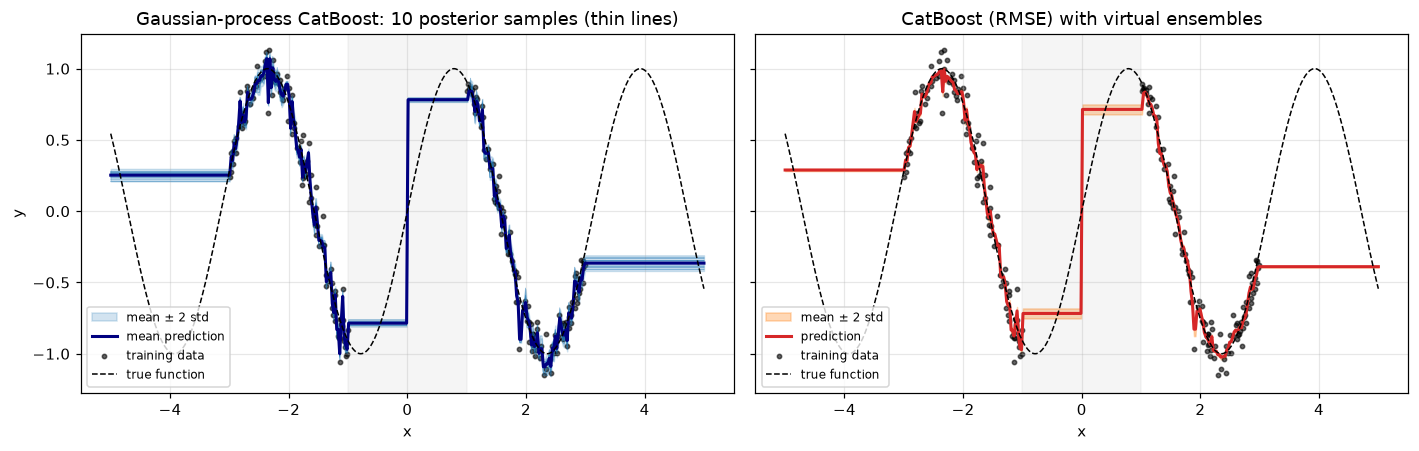

GP CatBoost                  mean std inside data: 0.030   in the gap / outside: 0.020
CatBoost virtual ensembles   mean std inside data: 0.005   in the gap / outside: 0.008


In [2]:
rng = np.random.default_rng(SEED)
x_toy = np.concatenate([rng.uniform(-3, -1, 100), rng.uniform(1, 3, 100)])
y_toy = np.sin(2 * x_toy) + rng.normal(0, 0.1, x_toy.size)
X_toy = pd.DataFrame({"x": x_toy})
X_grid = pd.DataFrame({"x": np.linspace(-5, 5, 400)})

gp_toy = ml.CatboostGaussianProcessRegressorMother(random_seed=SEED).fit(X_toy, pd.Series(y_toy))
gp_toy_unc = gp_toy.predict_uncertainty(X_grid)
member_curves = gp_toy.predict_posterior_samples(X_grid)

cb_toy = ml.CatboostRegressorMother(logging_level="Silent", random_seed=SEED).fit(X_toy, pd.Series(y_toy))
cb_toy_unc = cb_toy.predict_uncertainty(X_grid, n_ensembles=10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
xg = X_grid["x"].values
ax = axes[0]
for curve in member_curves:
    ax.plot(xg, curve, color="tab:blue", lw=0.6, alpha=0.5)
mean, std = gp_toy_unc["pred"].values, gp_toy_unc["knowledge_uncertainty"].values
ax.fill_between(xg, mean - 2 * std, mean + 2 * std, color="tab:blue", alpha=0.2, label="mean ± 2 std")
ax.plot(xg, mean, color="navy", lw=2, label="mean prediction")
ax.set_title(f"Gaussian-process CatBoost: {len(member_curves)} posterior samples (thin lines)")
ax = axes[1]
mean_cb, std_cb = cb_toy_unc["pred"].values, cb_toy_unc["knowledge_uncertainty"].astype(float).values
ax.fill_between(xg, mean_cb - 2 * std_cb, mean_cb + 2 * std_cb, color="tab:orange", alpha=0.3, label="mean ± 2 std")
ax.plot(xg, mean_cb, color="tab:red", lw=2, label="prediction")
ax.set_title("CatBoost (RMSE) with virtual ensembles")
for ax in axes:
    ax.scatter(x_toy, y_toy, s=8, color="k", alpha=0.6, label="training data")
    ax.plot(xg, np.sin(2 * xg), "k--", lw=1, label="true function")
    ax.axvspan(-1, 1, color="grey", alpha=0.08)
    ax.set_xlabel("x")
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

inside = (np.abs(xg) >= 1) & (np.abs(xg) <= 3)
for name, s in [("GP CatBoost", std), ("CatBoost virtual ensembles", std_cb)]:
    print(f"{name:28s} mean std inside data: {s[inside].mean():.3f}   in the gap / outside: {s[~inside].mean():.3f}")

**What to see:** the GP uncertainty does **not** grow in the gap or beyond the data; it is even slightly smaller there.

With a single feature every split is a threshold on $x$. Any point in the gap or beyond the data therefore falls into the same leaf as the nearest training points, so the tree kernel treats it as *identical* to them. Two other things follow:

* Trees continue with a constant prediction beyond the data, and they jump in the middle of the gap.
* The small band inside the windows is the left-over disagreement between members. It is not the label noise (std 0.1 here), because `delta=0` assumes noise-free labels.

**Take-away:** GP CatBoost does not detect "far away along one feature". The next toy shows what it does detect.

### 2.2 Two features: unseen feature combinations

Now the training data lies along the diagonal band $x_2 \approx x_1$. Every *single* feature value in $[-3, 3]$ has been seen, but the off-diagonal *combinations*, such as $x_1 = 2, x_2 = -2$, have not. This mirrors chemistry: every substructure of a new molecule may occur in the training set, while their combination is new.

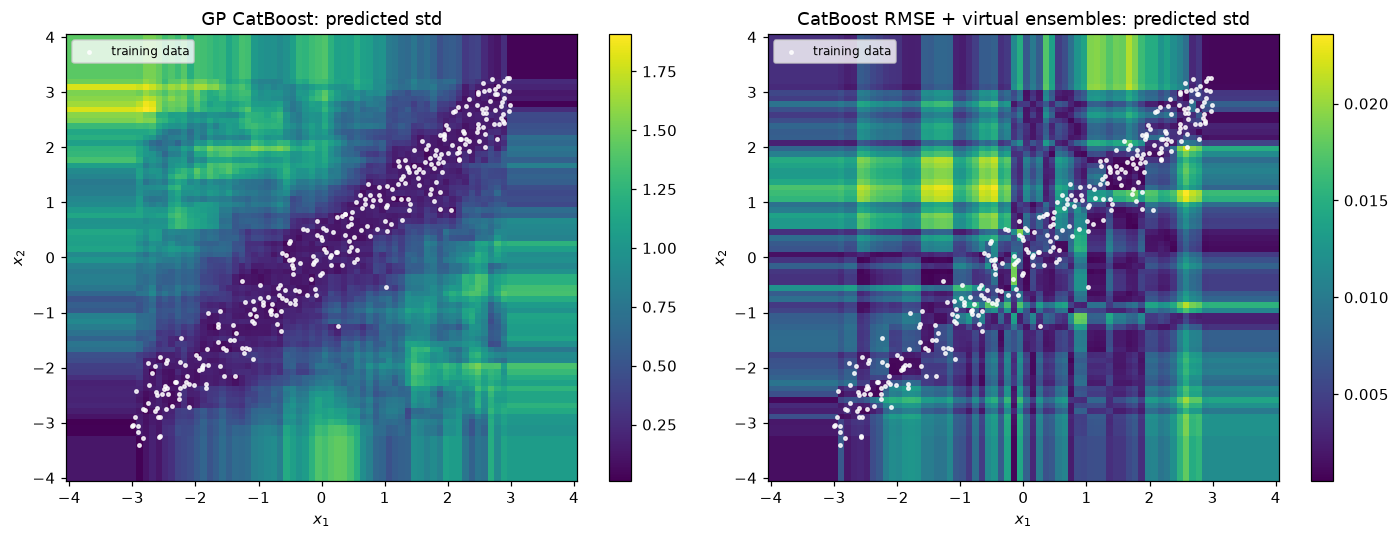

GP CatBoost                  mean std on the band: 0.157   off the band: 1.052
CatBoost virtual ensembles   mean std on the band: 0.005   off the band: 0.008


In [3]:
rng = np.random.default_rng(SEED)
x1 = rng.uniform(-3, 3, 300)
x2 = x1 + rng.normal(0, 0.4, 300)
y_band = np.sin(x1) + 0.5 * x2 + rng.normal(0, 0.1, 300)
X_band = pd.DataFrame({"x1": x1, "x2": x2})
g = np.linspace(-4, 4, 80)
G1, G2 = np.meshgrid(g, g)
X_plane = pd.DataFrame({"x1": G1.ravel(), "x2": G2.ravel()})

gp_band = ml.CatboostGaussianProcessRegressorMother(random_seed=SEED).fit(X_band, pd.Series(y_band))
std_gp_plane = gp_band.predict_uncertainty(X_plane)["knowledge_uncertainty"].to_numpy(float).reshape(G1.shape)
cb_band = ml.CatboostRegressorMother(logging_level="Silent", random_seed=SEED).fit(X_band, pd.Series(y_band))
std_cb_plane = (
    cb_band.predict_uncertainty(X_plane, n_ensembles=10)["knowledge_uncertainty"].to_numpy(float).reshape(G1.shape)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, std_plane, title in [
    (axes[0], std_gp_plane, "GP CatBoost: predicted std"),
    (axes[1], std_cb_plane, "CatBoost RMSE + virtual ensembles: predicted std"),
]:
    mesh = ax.pcolormesh(G1, G2, std_plane, shading="auto", cmap="viridis")
    ax.scatter(x1, x2, s=5, color="white", alpha=0.8, label="training data")
    plt.colorbar(mesh, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.grid(False)
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

off_diagonal = np.abs(G2 - G1)
for name, std_plane in [("GP CatBoost", std_gp_plane), ("CatBoost virtual ensembles", std_cb_plane)]:
    print(
        f"{name:28s} mean std on the band: {std_plane[off_diagonal < 0.8].mean():.3f}   "
        f"off the band: {std_plane[off_diagonal > 2.5].mean():.3f}"
    )

**What to see:**

* **GP CatBoost.** It is confident on the band and several times more uncertain off the band, exactly where the model would have to guess. The two corners at the *ends* of the band stay confident; that is the "beyond the edge looks like the edge" effect from 2.1. This is the knowledge signal: unseen combinations of features, not distance along one axis.
* **Virtual ensembles.** Their std is about two orders of magnitude smaller. In this toy it is not tied to where the training data lies, because one boosting run's trees stay similar to each other. On the real sets that small score still has information in its tails (section 4.1): very low means the run agrees, very high means it does not. It is not a map of the training support, and it does not pretend to be. It is also available from the ordinary RMSE fit.

On real data with many features, a new molecule almost always differs by a *combination* of features, which is why the GP's signal for unfamiliar molecules on ESOL (section 4.4) is clear.

### 2.3 Inside the fitted model: one merged CatBoost model

The fitted estimator is a single CatBoost model that contains the trees of all posterior samples (section 1.5). The cell below looks inside the 1D toy model from 2.1 and checks three things:

* `predict` on the merged model equals the mean of the individual samples;
* `knowledge_uncertainty` equals their standard deviation;
* one sample can be recovered by predicting with its own tree range and multiplying by the number of samples.

In [4]:
n_samples = len(gp_toy.posterior_tree_ranges_)
print(f"posterior samples: {n_samples}, trees in the merged model: {gp_toy.tree_count_}")
print("tree range of each sample:", gp_toy.posterior_tree_ranges_)

samples_on_grid = gp_toy.predict_posterior_samples(X_grid)
mean_gap = np.abs(gp_toy.predict(X_grid) - samples_on_grid.mean(axis=0)).max()
std_gap = np.abs(gp_toy_unc["knowledge_uncertainty"].to_numpy(float) - samples_on_grid.std(axis=0)).max()
ntree_start, ntree_end = gp_toy.posterior_tree_ranges_[1]
second_sample = n_samples * gp_toy.predict(X_grid, ntree_start=ntree_start, ntree_end=ntree_end)
sample_gap = np.abs(second_sample - samples_on_grid[1]).max()

print(f"\nshape of predict_posterior_samples: {samples_on_grid.shape}  (samples × rows)")
print(f"max |predict - mean of samples|:              {mean_gap:.1e}")
print(f"max |knowledge_uncertainty - std of samples|: {std_gap:.1e}")
print(f"max |{n_samples} × trees {ntree_start}–{ntree_end} - sample 2|:     {sample_gap:.1e}")

posterior samples: 10, trees in the merged model: 10000
tree range of each sample: [(0, 1000), (1000, 2000), (2000, 3000), (3000, 4000), (4000, 5000), (5000, 6000), (6000, 7000), (7000, 8000), (8000, 9000), (9000, 10000)]

shape of predict_posterior_samples: (10, 400)  (samples × rows)
max |predict - mean of samples|:              4.9e-15
max |knowledge_uncertainty - std of samples|: 0.0e+00
max |10 × trees 1000–2000 - sample 2|:     0.0e+00


All three differences are zero up to floating-point rounding: the merged model *is* the ensemble, stored as one CatBoost object with 10 blocks of 1,000 trees.

### How the molecule pipeline below is built

ESOL and FreeSolv use the same four steps. The next code cells are the whole pipeline in one block; the steps are named here so the block is easy to follow.

1. **Standardise the structure.** `StandardizerTransformer` with `STANDARDIZE`, `NEUTRALIZE` and `DESALT` cleans the SMILES.
2. **Turn SMILES into molecules.** `SmilesToMolTransformer` writes an rdkit molecule column.
3. **Build the feature matrix.** A `FeatureUnion` of `MorganFingerprints` and `ChemicalDescriptors`. `MaccsFingerprints` is added to that union in the same way when MACCS keys are wanted. The numbers in this notebook use Morgan fingerprints plus descriptors, with constant columns removed.
4. **Keep similar molecules together.** `TanimotoGroupingFromMols(similarity_threshold=0.4)` builds the groups, and `GroupShuffleSplit` places each group entirely in train, calibration or test. The calibration split is held out of the fit and is used only to rescale an uncertainty (section 4.3).

The same steps work from a local table. FreeSolv in section 6 is the full public set, with the experimental hydration free energy `expt` in kcal/mol.


## 3. Performance on ESOL solubility

**Data.** The [ESOL / Delaney](https://pubs.acs.org/doi/10.1021/ci034243x) data set (1,128 molecules, measured log solubility in mol/L), as distributed with [MoleculeNet / DeepChem](https://github.com/deepchem/deepchem). It is downloaded on the fly.

**Features.** Morgan fingerprints and RDKit chemical descriptors, as in the other regression notebooks.

**Split.** Molecules are clustered with `TanimotoGroupingFromMols`, and whole clusters are assigned to one split, so the test set contains chemistry the model has not seen. The split is:

* **train** (about 60 %): model fitting;
* **calibration** (about 15 %): used only to *recalibrate* the uncertainties in section 4.3;
* **test** (about 25 %): all reported numbers.

**Reproducibility.** The toy data, both splits and every model use the same seed (`SEED = 0`), so rerunning the notebook gives the same numbers.

In [5]:
ESOL_URL = "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv"
TARGET_COL = "measured log solubility in mols per litre"
data = pd.read_csv(ESOL_URL)[["Compound ID", "smiles", TARGET_COL]]
print(data.shape)
data.head()

(1128, 3)


,Compound ID,smiles,measured log solubility in mols per litre
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,citral,CC(C)=CCCC(C)=CC(=O),-2.06
3,Picene,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,Thiophene,c1ccsc1,-1.33


In [6]:
preprocessing = sklearn_pipeline.Pipeline(
    [
        ("standardizer", StandardizerTransformer(flags=["STANDARDIZE", "NEUTRALIZE", "DESALT"])),
        ("smiles_to_mol", SmilesToMolTransformer()),
    ]
).set_output(transform="pandas")
mols = preprocessing.fit_transform(data["smiles"])["Molecule"]

features = (
    sklearn_pipeline.FeatureUnion([("morgan", fg.MorganFingerprints()), ("descriptors", fg.ChemicalDescriptors())])
    .set_output(transform="pandas")
    .fit_transform(mols)
)
features = features.loc[:, features.std() > 0]
y = data[TARGET_COL]

groups = (
    cv_module.TanimotoGroupingFromMols(similarity_threshold=0.4).set_output(transform="pandas").fit_transform(mols)
)["tanimoto-group"]
print(f"features: {features.shape}, Tanimoto groups: {groups.nunique()}, target std: {y.std():.2f} log units")

[11:21:32] Initializing Normalizer


[11:21:32] Initializing MetalDisconnector


[11:21:32] Initializing Normalizer


features: (1128, 2054), Tanimoto groups: 462, target std: 2.10 log units


In [7]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
trainval_idx, test_idx = next(outer.split(features, y, groups))
inner = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
fit_pos, cal_pos = next(inner.split(trainval_idx, groups=groups.iloc[trainval_idx]))
train_idx, cal_idx = trainval_idx[fit_pos], trainval_idx[cal_pos]

X_train, y_train = features.iloc[train_idx], y.iloc[train_idx]
X_cal, y_cal = features.iloc[cal_idx], y.iloc[cal_idx]
X_test, y_test = features.iloc[test_idx], y.iloc[test_idx]
print(f"train {len(train_idx)}, calibration {len(cal_idx)}, test {len(test_idx)}")

train 596, calibration 190, test 342


### Models

| Name | Model | Uncertainty used |
|---|---|---|
| **GP CatBoost** | `CatboostGaussianProcessRegressorMother()` with defaults | `knowledge_uncertainty` (std over 10 posterior samples) |
| **CatBoost RMSE + VE** | `CatboostRegressorMother(loss_function="RMSE")` | `knowledge_uncertainty` from 10 virtual ensembles |
| **CatBoost RMSEWithUncertainty** | `CatboostRegressorMother(loss_function="RMSEWithUncertainty")` | `total_uncertainty` = √(knowledge² + data²); the model also predicts the label noise |

All uncertainties are returned as **standard deviations** in target units. Read them as three tools, not as a winner and two leftovers:

* **GP CatBoost** answers "has the model seen this kind of chemistry?"
* **RMSEWithUncertainty** answers "is this the kind of molecule the model gets badly wrong?", because it predicts the label noise as well as a small virtual-ensemble spread.
* **RMSE + virtual ensembles** answers the same knowledge question more coarsely, at no extra training cost. The middle of its ranking is flat. The very low scores still mark smaller errors on both data sets, and the very high scores still mark larger errors on ESOL, with a softer high end on FreeSolv (sections 4.1 and 6.1).

In [8]:
def fit_and_predict(model, uncertainty_col, **predict_kwargs):
    start = time.time()
    model.fit(X_train, y_train)
    fit_seconds = time.time() - start
    out = {}
    for split, X_split in [("cal", X_cal), ("test", X_test)]:
        unc = model.predict_uncertainty(X_split, **predict_kwargs)
        out[split] = (unc["pred"].to_numpy(float), unc[uncertainty_col].to_numpy(float))
        out[f"{split}_frame"] = unc
    out["fit_seconds"] = fit_seconds
    return model, out


gp_model, gp_out = fit_and_predict(ml.CatboostGaussianProcessRegressorMother(random_seed=SEED), "knowledge_uncertainty")
_, cb_ve_out = fit_and_predict(
    ml.CatboostRegressorMother(loss_function="RMSE", logging_level="Silent", random_seed=SEED),
    "knowledge_uncertainty",
    n_ensembles=10,
)
_, cb_rwu_out = fit_and_predict(
    ml.CatboostRegressorMother(loss_function="RMSEWithUncertainty", logging_level="Silent", random_seed=SEED),
    "total_uncertainty",
    n_ensembles=10,
)
results = {"GP CatBoost": gp_out, "CatBoost RMSE + VE": cb_ve_out, "CatBoost RMSEWithUncertainty": cb_rwu_out}

In [9]:
performance = pd.DataFrame(
    {
        name: {
            "RMSE": root_mean_squared_error(y_test, out["test"][0]),
            "MAE": mean_absolute_error(y_test, out["test"][0]),
            "R²": r2_score(y_test, out["test"][0]),
            "fit time [s]": out["fit_seconds"],
        }
        for name, out in results.items()
    }
).T
performance.round(3)

,RMSE,MAE,R²,fit time [s]
GP CatBoost,0.645,0.487,0.913,94.339
CatBoost RMSE + VE,0.617,0.471,0.920,10.106
CatBoost RMSEWithUncertainty,0.632,0.488,0.916,15.985


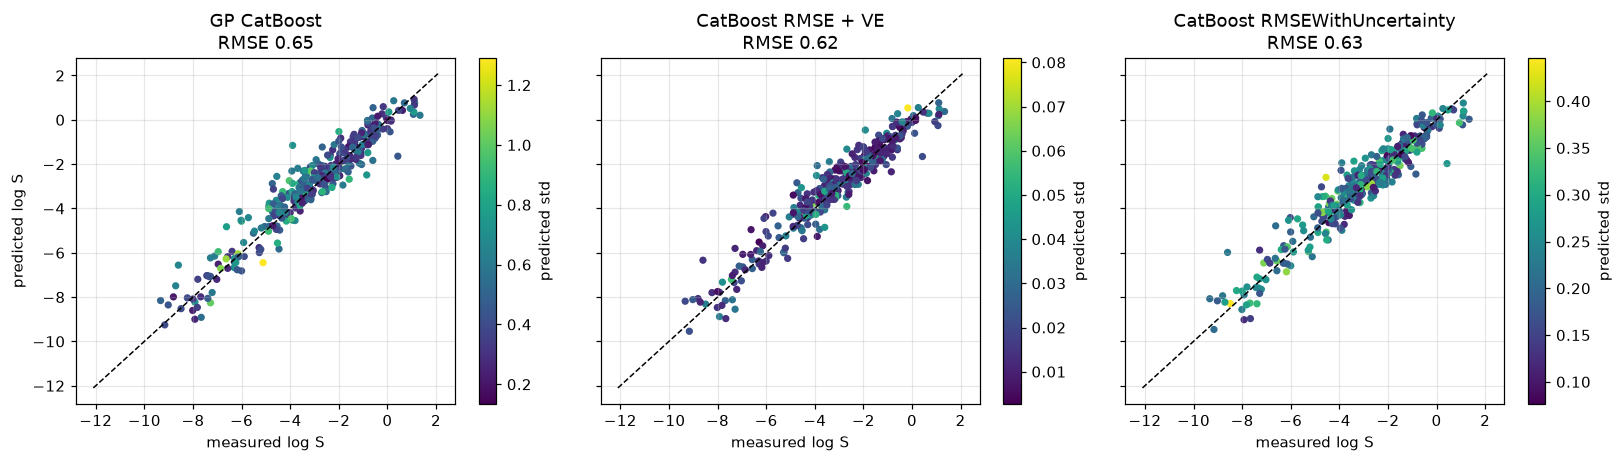

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharex=True, sharey=True)
lims = [y.min() - 0.5, y.max() + 0.5]
for ax, (name, out) in zip(axes, results.items()):
    mean, std = out["test"]
    sc = ax.scatter(y_test, mean, c=std, cmap="viridis", s=14)
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_title(f"{name}\nRMSE {root_mean_squared_error(y_test, mean):.2f}")
    ax.set_xlabel("measured log S")
    plt.colorbar(sc, ax=ax, label="predicted std")
axes[0].set_ylabel("predicted log S")
plt.tight_layout()
plt.show()

**Reading the result:** all three models predict about equally well. GP CatBoost's RMSE of about 0.65 is only slightly worse than about 0.62 for the two CatBoost regressors. That gap is the price of the posterior step, which uses no L2 leaf regularisation and, with the defaults, 900 posterior trees, and the fit takes roughly 9× longer because it trains 10 members. Accuracy is a shared strength. The reason to choose among them is the uncertainty, which the next section evaluates.

## 4. Quality of the uncertainty estimates

A useful uncertainty has three properties, and we test each one.

1. **Ranking.** Larger uncertainty should mean larger error. Tests: the Spearman, Kendall and Pearson correlations between std and |error|, and **error-retention curves**: drop the most uncertain predictions first and see how fast the error falls.
2. **Calibration.** A 95 % interval, mean ± 1.96·std, should contain about 95 % of the true values. Tests: coverage at several levels, the calibration curve, and the Gaussian negative log-likelihood (NLL), which rewards intervals that are both right and narrow.
3. **Out-of-distribution signal.** Uncertainty should rise for molecules that are dissimilar to the training set.

**Three correlations, three questions.**

* **Spearman** correlates the *ranks*: does a higher uncertainty go with a higher error, whatever the shape of the relation? This is the main number in this notebook.
* **Kendall's τ** also uses only the order. It counts pairs of molecules: τ = (concordant pairs − discordant pairs) / all pairs, so (1 + τ) / 2 is the probability that, of two random molecules, the more uncertain one has the larger error. It is usually smaller in size than Spearman for the same data and is less affected by a few extreme values.
* **Pearson** correlates the *values* and measures a linear relation. It reacts to the scale of the std and to a few very large errors, so it can differ from the two rank measures when the relation is monotone but not linear, or when a few outliers dominate.

If the three agree in sign and roughly in size, the relation is robust. If Pearson is much larger than the rank measures, a few extreme molecules drive it.

**How to read the sign.** All three are +1 when two columns rise together and −1 when one rises as the other falls. The useful sign depends on the pairing:

* **Uncertainty against absolute error.** Positive is useful: more uncertain molecules have larger errors. Near zero means the score does not order the errors. A clearly negative value would mean the score is backwards.
* **Similarity against uncertainty, or similarity against absolute error.** Similarity is high for molecules close to the training set, so **negative is useful**: less similar molecules have a higher uncertainty or a larger error. Near zero means no novelty signal. A positive value would mean the score is higher for familiar molecules.

A printed value of −0.00 or −0.10 is "no relationship". It is not a reversed score.

In [11]:
def uncertainty_metrics(y_true, mean, std):
    y_true = np.asarray(y_true, float)
    std = np.maximum(std, 1e-9)
    err = y_true - mean
    z = err / std
    levels = np.linspace(0.01, 0.99, 99)
    observed = np.array([np.mean(np.abs(z) <= stats.norm.ppf(0.5 + p / 2)) for p in levels])
    return {
        "mean std": std.mean(),
        "Spearman(std, |err|)": stats.spearmanr(std, np.abs(err)).statistic,
        "Kendall(std, |err|)": stats.kendalltau(std, np.abs(err)).statistic,
        "Pearson(std, |err|)": stats.pearsonr(std, np.abs(err)).statistic,
        "coverage 68%": np.mean(np.abs(z) <= 1.0),
        "coverage 95%": np.mean(np.abs(z) <= 1.96),
        "miscalibration area": np.mean(np.abs(observed - levels)),
        "NLL": np.mean(0.5 * np.log(2 * np.pi * std**2) + 0.5 * z**2),
        "RMSE of 50% most certain": np.sqrt(np.mean(err[np.argsort(std)][: len(err) // 2] ** 2)),
    }


uq_raw = pd.DataFrame({name: uncertainty_metrics(y_test, *out["test"]) for name, out in results.items()}).T
uq_raw.round(3)

,mean std,"Spearman(std, |err|)","Kendall(std, |err|)","Pearson(std, |err|)",coverage 68%,coverage 95%,miscalibration area,NLL,RMSE of 50% most certain
GP CatBoost,0.487,0.317,0.218,0.327,0.567,0.889,0.082,0.998,0.451
CatBoost RMSE + VE,0.020,0.106,0.072,0.072,0.018,0.035,0.482,1225.822,0.574
CatBoost RMSEWithUncertainty,0.220,0.120,0.082,0.105,0.254,0.553,0.303,4.350,0.574


**Reading the table** (test set, uncertainties as returned):

* **GP CatBoost** is on the scale of the actual errors. Its 95 % intervals cover about 89 % of the test molecules, slightly over-confident, and it has the best NLL. It also ranks errors best here: Spearman ≈ 0.32, and the RMSE of its most certain half drops to about 0.45, compared with 0.65 overall.
* **CatBoost RMSE + virtual ensembles** measures how stable one boosting run is, so its std is about 25× smaller than the errors. Read as a raw Gaussian interval it covers only a few percent. That scale is a property of the method, not a failed prediction: one fitted scale factor (section 4.3) turns it into a usable interval, and the ranking of molecules is unchanged by that factor. The overall correlation with error is modest.
* **CatBoost RMSEWithUncertainty** also predicts the label noise, so its std is much closer to the error scale (about 55 % coverage at 95 %). On ESOL its overall correlation with the error is modest too, because these errors are mostly a knowledge problem. Its strength shows up on FreeSolv (section 6), where a few hard molecules dominate.

**Kendall and Pearson tell the same story.** GP CatBoost leads on all three correlations (Spearman 0.32, Kendall 0.22, Pearson 0.33), and the two CatBoost scores stay modest (Kendall 0.07 and 0.08, Pearson 0.07 and 0.11). Kendall is smaller in size as expected; it means that of two random molecules, the more uncertain one has the larger error about 61 % of the time for GP CatBoost and about 54 % for the CatBoost scores. Pearson is close to Spearman, so no few extreme molecules inflate the ranking.

A modest *overall* correlation does not mean the CatBoost uncertainties carry no information. Section 4.1 looks at the very low and very high ends, which is where a free score is still worth using.

### 4.1 Ranking: does the uncertainty point at the large errors?

The error-retention curve sorts the test molecules by predicted std. It then drops the most uncertain fraction and reports the RMSE of what is left.

* An **oracle** that sorts by the true error gives the lower bound.
* A **random** ordering gives a flat line. That is the grey dotted horizontal line: the RMSE of the whole test set. The solid curve is only beating a random ranking when it falls below that line.
* The black dashed curve is the **oracle**, molecules sorted by their true absolute error. It is the lowest RMSE any ranking of these predictions can reach.

The closer a model's solid curve is to the dashed oracle, and the further it falls below the dotted line, the more useful its uncertainty is for deciding which predictions to trust.

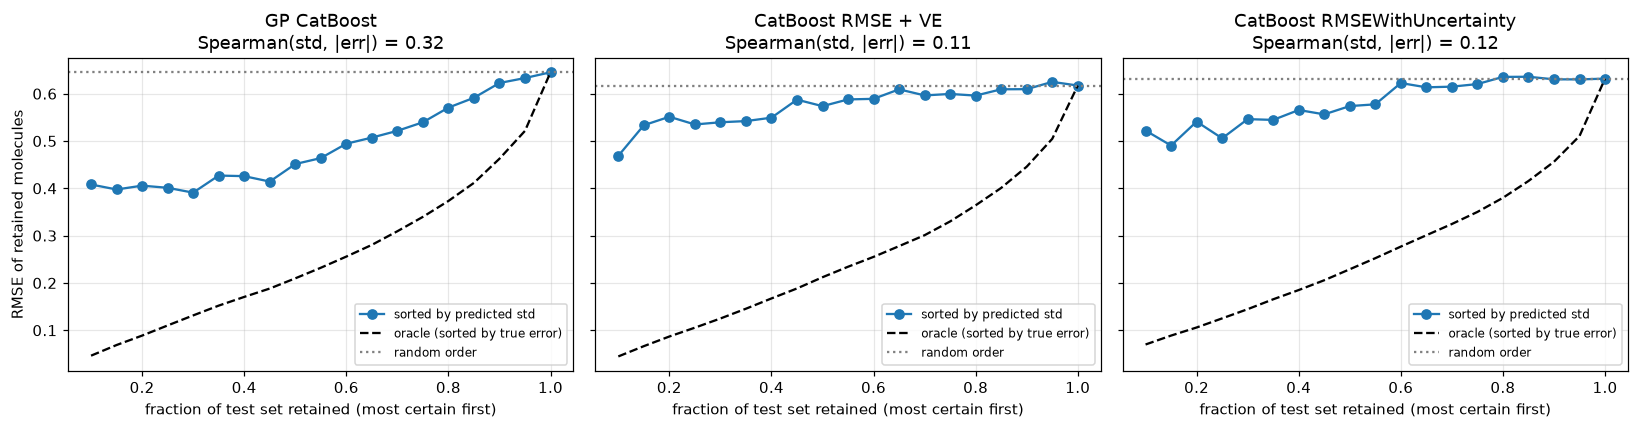

In [12]:
def retention_curve(y_true, mean, order_by):
    err2 = (np.asarray(y_true, float) - mean) ** 2
    sorted_err2 = err2[np.argsort(order_by)]
    fractions = np.linspace(0.1, 1.0, 19)
    return fractions, [np.sqrt(sorted_err2[: max(1, int(f * len(err2)))].mean()) for f in fractions]


fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, out) in zip(axes, results.items()):
    mean, std = out["test"]
    abs_err = np.abs(y_test.values - mean)
    f, curve = retention_curve(y_test, mean, std)
    _, oracle = retention_curve(y_test, mean, abs_err)
    ax.plot(f, curve, "o-", label="sorted by predicted std")
    ax.plot(f, oracle, "k--", label="oracle (sorted by true error)")
    ax.axhline(root_mean_squared_error(y_test, mean), color="grey", ls=":", label="random order")
    ax.set_title(f"{name}\nSpearman(std, |err|) = {stats.spearmanr(std, abs_err).statistic:.2f}")
    ax.set_xlabel("fraction of test set retained (most certain first)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("RMSE of retained molecules")
plt.tight_layout()
plt.show()

The GP curve falls most steadily as uncertain molecules are dropped, which is its advantage: it orders the whole range, not only the tails. Both CatBoost curves fall as well, mainly at the most certain end, and stay closer to the random-order line through the middle. All three stay far from the oracle, because much of the error is label noise or model error that no knowledge score can name in advance.

The retention curve and the Spearman correlation summarise the whole range of uncertainties. An uncertainty can still be useful at its **extremes** even if it hardly orders the molecules in between. The table below splits the test molecules into bands by their predicted std, from the 10 % most certain to the 10 % least certain. It reports each band's mean absolute error **relative to the overall MAE**: 1.0 means average error, below 1 means smaller errors than average.

In [13]:
UNCERTAINTY_BANDS = (0.0, 0.1, 0.25, 0.75, 0.9, 1.0)


def error_by_uncertainty_band(y_true, mean, std, edges=UNCERTAINTY_BANDS):
    abs_err = np.abs(np.asarray(y_true, float) - mean)
    rank = stats.rankdata(std, method="ordinal") / len(std)
    labels = [f"{lo:.0%}–{hi:.0%}" for lo, hi in zip(edges[:-1], edges[1:])]
    band = pd.cut(rank, bins=edges, labels=labels, include_lowest=True)
    return pd.Series(abs_err).groupby(band, observed=True).mean() / abs_err.mean()


bands = pd.DataFrame({name: error_by_uncertainty_band(y_test, *out["test"]) for name, out in results.items()}).T
bands.columns.name = "band of predicted std (most certain → least certain)"
bands.round(2)

band of predicted std (most certain → least certain),0%–10%,10%–25%,25%–75%,75%–90%,90%–100%
GP CatBoost,0.66,0.67,0.95,1.45,1.38
CatBoost RMSE + VE,0.70,0.92,1.03,1.08,1.15
CatBoost RMSEWithUncertainty,0.84,0.79,1.06,1.06,1.06


**Reading the table:**

* **A very low score is meaningful for every model.** The most certain 10 % have about 0.66–0.84 of the average error. For standard CatBoost the figure is 0.70×. The molecules the virtual ensembles agree on really do have smaller errors, and that signal did not require another fit.
* **A very high score is meaningful too, with different strength.** Standard CatBoost's least certain 10 % sit at 1.15× the average error. That rise is smaller than GP CatBoost's upper bands (about 1.4×), and it is still above average: the molecules the boosting run disagrees on are a review list. RMSEWithUncertainty's rise is small on ESOL (about 1.06×), which fits a data-noise score on a knowledge-driven set. GP CatBoost keeps separating through the middle as well.
* **Through the middle** the two CatBoost scores hardly separate small from large errors; their 25–90 % bands sit close to 1. That is what the modest Spearman correlation reflects (0.11 for virtual ensembles). Use the tails. Trust the very low scores, and treat the very high scores as the ones to review.

The virtual-ensemble score is the one you can always compute. A ranking across the whole set is GP CatBoost's result, and a few hard molecules are `RMSEWithUncertainty`'s result. The free score still marks both of its own extremes.

#### Very low vs. very high uncertainty

The box plots compare the absolute errors of the **10 % most certain**, the middle 80 % and the **10 % least certain**
test molecules. The title gives the ratio of the median errors (least / most certain) and the one-sided Mann-Whitney
p-value for "the least certain molecules have larger errors". If an uncertainty is meaningful, the right box sits
clearly above the left one, even if the overall correlation is weak.

GP CatBoost and RMSE + VE return a knowledge uncertainty only. To compare like with like, `RMSEWithUncertainty` is
split into its two components: its **knowledge** part (virtual ensembles) and its **data** part (predicted label
noise). Its `total_uncertainty` is practically the data part (section 4.5).

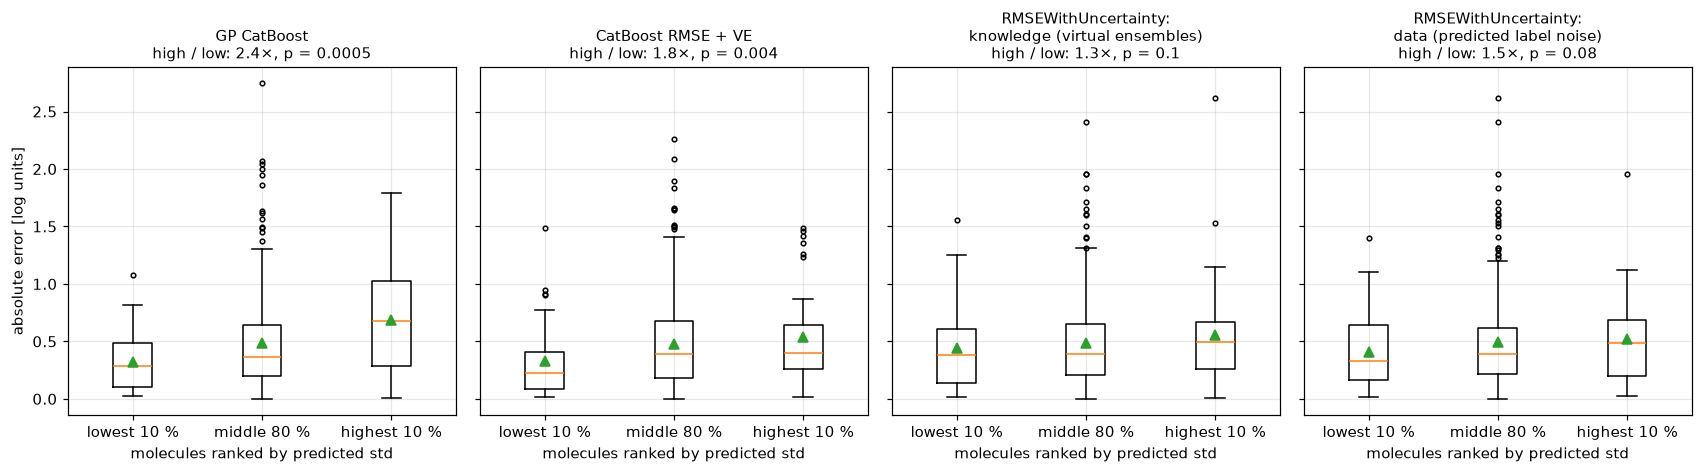

In [14]:
def extreme_groups(y_true, mean, std, frac=0.1):
    abs_err = np.abs(np.asarray(y_true, float) - mean)
    order = np.argsort(std)
    n = max(1, int(round(frac * len(std))))
    return {
        "lowest 10 %": abs_err[order[:n]],
        "middle 80 %": abs_err[order[n:-n]],
        "highest 10 %": abs_err[order[-n:]],
    }


def compare_extremes(groups):
    low, high = groups["lowest 10 %"], groups["highest 10 %"]
    ratio = np.median(high) / np.median(low)
    p_value = stats.mannwhitneyu(high, low, alternative="greater").pvalue
    return ratio, p_value


def uncertainty_panels(results_dict):
    """One (prediction, std) pair per panel; RMSEWithUncertainty is split into its two components."""
    panels = {}
    for name, out in results_dict.items():
        if name == "CatBoost RMSEWithUncertainty":
            frame = out["test_frame"]
            mean = frame["pred"].to_numpy(float)
            panels["RMSEWithUncertainty:\nknowledge (virtual ensembles)"] = (
                mean,
                frame["knowledge_uncertainty"].to_numpy(float),
            )
            panels["RMSEWithUncertainty:\ndata (predicted label noise)"] = (
                mean,
                frame["data_uncertainty"].to_numpy(float),
            )
        else:
            panels[name] = out["test"]
    return panels


def plot_extreme_boxplots(results_dict, y_true, unit):
    panels = uncertainty_panels(results_dict)
    fig, axes = plt.subplots(1, len(panels), figsize=(3.9 * len(panels), 4.4), sharey=True)
    for ax, (name, (mean, std)) in zip(axes, panels.items()):
        groups = extreme_groups(y_true, mean, std)
        ax.boxplot(list(groups.values()), tick_labels=list(groups), showmeans=True, flierprops={"markersize": 3})
        ratio, p_value = compare_extremes(groups)
        ax.set_title(f"{name}\nhigh / low: {ratio:.1f}×, p = {p_value:.1g}", fontsize=9.5)
        ax.set_xlabel("molecules ranked by predicted std")
    axes[0].set_ylabel(f"absolute error [{unit}]")
    plt.tight_layout()
    plt.show()


def plot_extreme_details(results_dict, y_true, unit):
    """One figure per score, on its own error scale, plus the std inside each tail.

    The combined box plot shares one error axis. These figures do not. The right panel
    shows the predicted std in the same three groups, which the combined figure omits.
    """
    panels = uncertainty_panels(results_dict)
    y_true = np.asarray(y_true, float)
    rng = np.random.default_rng(SEED)
    for name, (mean, std) in panels.items():
        mean = np.asarray(mean, float)
        std = np.asarray(std, float)
        groups = extreme_groups(y_true, mean, std)
        order = np.argsort(std)
        n_tail = max(1, int(round(0.1 * len(std))))
        std_groups = {
            "lowest 10 %": std[order[:n_tail]],
            "middle 80 %": std[order[n_tail:-n_tail]],
            "highest 10 %": std[order[-n_tail:]],
        }
        ratio, p_value = compare_extremes(groups)
        overall_median = float(np.median(np.abs(y_true - mean)))
        labels = list(groups)

        fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.4))

        def _draw(ax, series_by_label, color):
            series = [series_by_label[label] for label in labels]
            ax.boxplot(series, tick_labels=labels, showmeans=True, flierprops={"markersize": 3})
            for i, values in enumerate(series, start=1):
                jitter = rng.uniform(-0.16, 0.16, size=len(values))
                ax.scatter(
                    np.full(len(values), i) + jitter,
                    values,
                    s=16,
                    alpha=0.45,
                    color=color,
                    zorder=3,
                    linewidths=0,
                )

        _draw(axes[0], groups, "#1f4e79")
        axes[0].axhline(
            overall_median,
            color="0.35",
            ls="--",
            lw=1,
            label=f"overall median |error| = {overall_median:.2f} {unit}",
        )
        axes[0].set_ylabel(f"absolute error [{unit}]")
        axes[0].set_title("absolute error, this score's own scale")
        axes[0].legend(fontsize=8, loc="upper left")

        _draw(axes[1], std_groups, "#b85c38")
        axes[1].set_ylabel(f"predicted std [{unit}]")
        axes[1].set_title("predicted std in the same three groups")

        fig.suptitle(
            f"{name.replace(chr(10), ' ')}\nhigh / low median |error| = {ratio:.1f}×, p = {p_value:.1g}",
            fontsize=11,
        )
        fig.tight_layout()
        plt.show()

        detail = pd.DataFrame(
            {
                "n": [len(groups[label]) for label in labels],
                "median |error|": [float(np.median(groups[label])) for label in labels],
                "median predicted std": [float(np.median(std_groups[label])) for label in labels],
            },
            index=labels,
        )
        print(name.replace("\n", " "))
        print(detail.round(4).to_string())
        print()


plot_extreme_boxplots(results, y_test.values, "log units")

Each score on its own, for ESOL. The shared figure above uses one error axis, which squeezes a score whose errors sit in a narrow band. These figures do not share that axis. They also add what the shared figure leaves out: every test molecule, the overall median absolute error as a dashed line, and the predicted std inside the same three groups. The right panel shows whether the lowest and highest 10 % are far apart in that score's own units.

The numbers under each figure are the group size, the median absolute error, and the median predicted std.

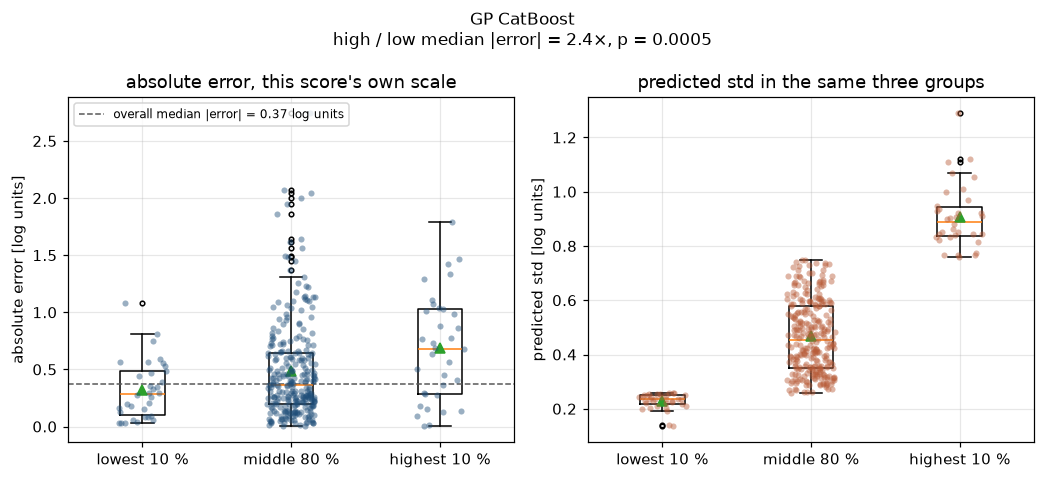

GP CatBoost
                n  median |error|  median predicted std
lowest 10 %    34          0.2829                0.2356
middle 80 %   274          0.3648                0.4548
highest 10 %   34          0.6812                0.8898



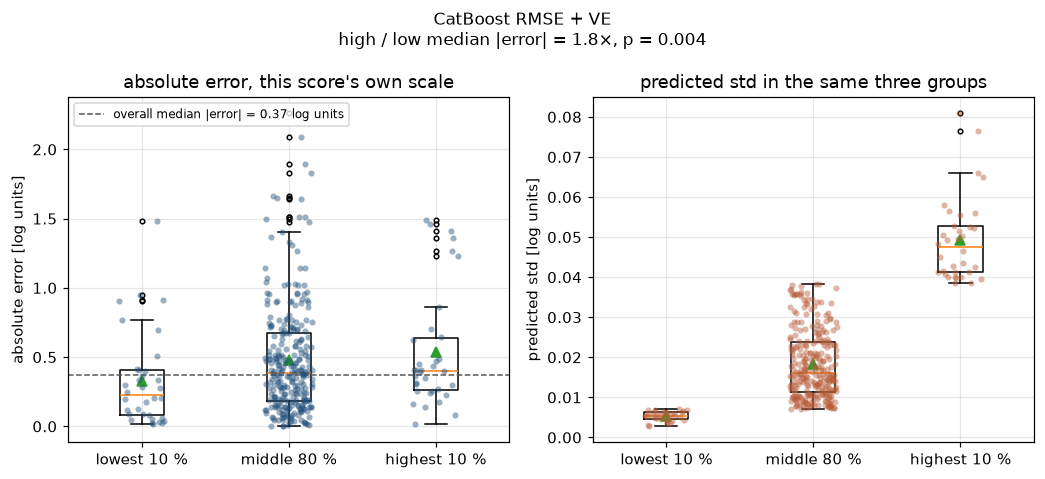

CatBoost RMSE + VE
                n  median |error|  median predicted std
lowest 10 %    34          0.2286                0.0054
middle 80 %   274          0.3862                0.0160
highest 10 %   34          0.4016                0.0475



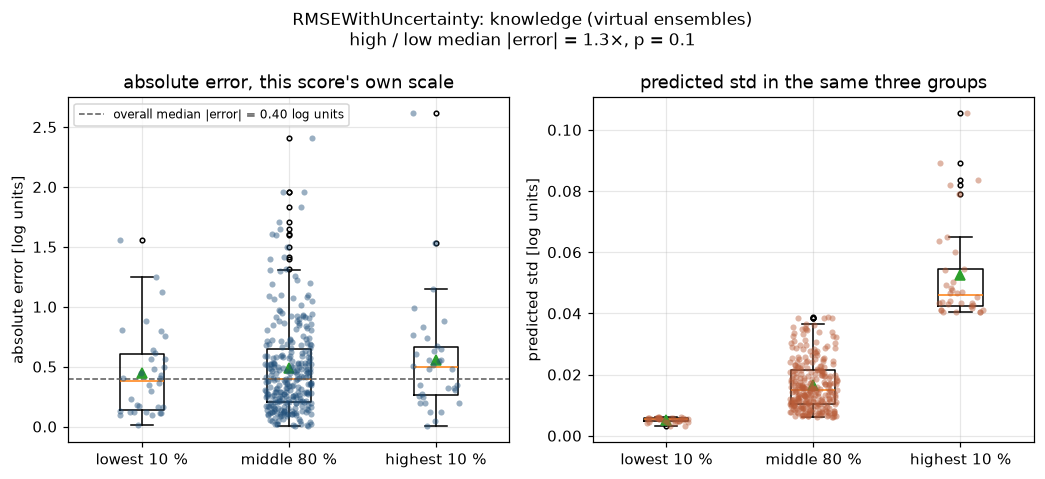

RMSEWithUncertainty: knowledge (virtual ensembles)
                n  median |error|  median predicted std
lowest 10 %    34          0.3826                0.0054
middle 80 %   274          0.3938                0.0149
highest 10 %   34          0.4946                0.0459



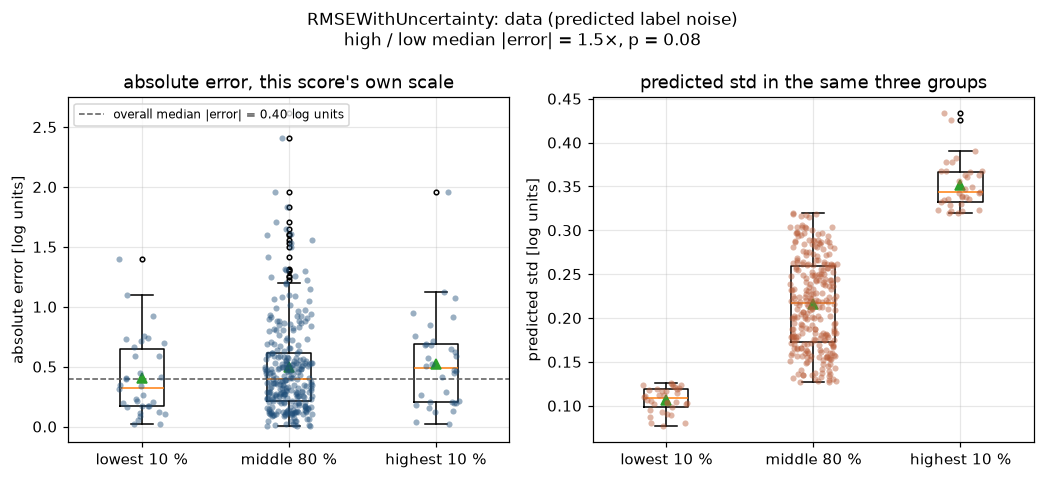

RMSEWithUncertainty: data (predicted label noise)
                n  median |error|  median predicted std
lowest 10 %    34          0.3255                0.1083
middle 80 %   274          0.3938                0.2168
highest 10 %   34          0.4877                0.3433



In [15]:
plot_extreme_details(results, y_test.values, "log units")

**Reading the plot:**

* **GP CatBoost** separates the extremes best on ESOL: the least certain 10 % have a median error 2.4× that of the most certain 10 % (p ≈ 0.0005), and the middle box sits in between, so the ordering holds across the range. This is the knowledge-uncertainty result.
* **Virtual ensembles of plain RMSE CatBoost do a real job.** They give 1.8× (p ≈ 0.004). Their most certain 10 % have the smallest errors of all panels (0.70× the average error in the band table), and their least certain 10 % sit above average (1.15×). The overall Spearman is 0.11, so the middle of the ranking is flat; both tails are the usable part. Their std is too small to read as an interval without rescaling (section 4.2). The score is the virtual ensemble of the model you already fit.
* **The virtual ensembles inside `RMSEWithUncertainty`** separate the extremes less (1.3×, not significant). That loss spends its capacity on the noise head; the ensemble spread is a smaller extra, not the main score.
* **The data part of `RMSEWithUncertainty`** separates the extremes only modestly on ESOL (1.5×, p ≈ 0.08). On this set the errors are mostly unfamiliar chemistry, which is GP CatBoost's job. The same data part is the strong score on FreeSolv.

### 4.2 Calibration: are the intervals the right width?

The calibration curve plots, for every nominal level $p$, the fraction of test molecules inside the central $p$-interval of $\mathcal{N}(\text{pred}, \text{std}^2)$.

* On the diagonal, the model is calibrated.
* Below it, the intervals are too narrow and the model is over-confident.
* Above it, they are too wide and the model is under-confident.

The histogram shows the standardised errors $z = (y - \text{pred}) / \text{std}$. For a calibrated Gaussian model they follow $\mathcal{N}(0, 1)$.

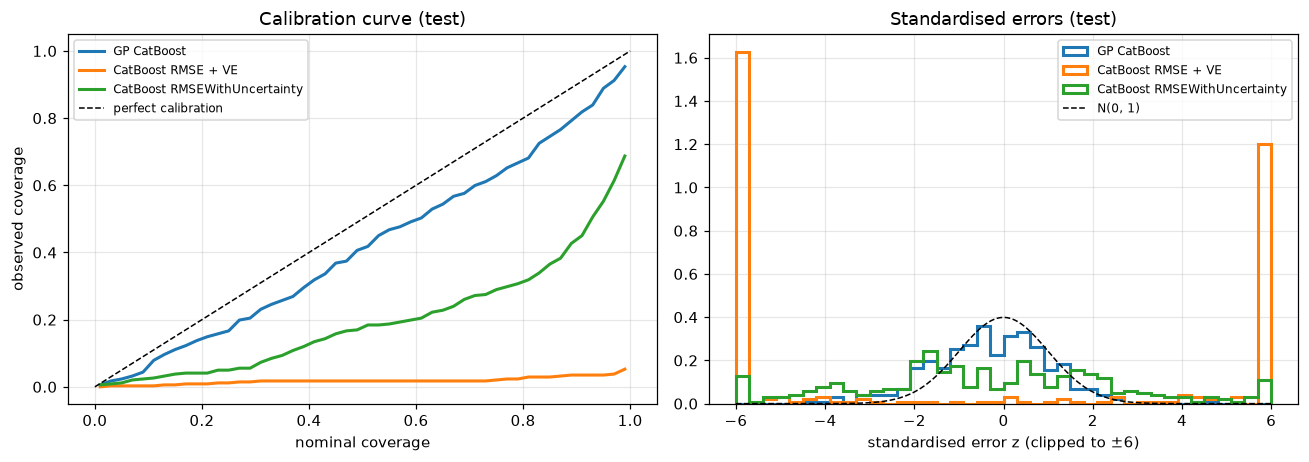

In [16]:
def calibration_curve(y_true, mean, std):
    z = (np.asarray(y_true, float) - mean) / np.maximum(std, 1e-9)
    levels = np.linspace(0.01, 0.99, 50)
    return levels, [np.mean(np.abs(z) <= stats.norm.ppf(0.5 + p / 2)) for p in levels], z


fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
grid = np.linspace(-6, 6, 200)
for name, out in results.items():
    levels, observed, z = calibration_curve(y_test, *out["test"])
    axes[0].plot(levels, observed, lw=2, label=name)
    axes[1].hist(np.clip(z, -6, 6), bins=40, range=(-6, 6), density=True, histtype="step", lw=2, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
axes[0].set_xlabel("nominal coverage")
axes[0].set_ylabel("observed coverage")
axes[0].set_title("Calibration curve (test)")
axes[0].legend(fontsize=8)
axes[1].plot(grid, stats.norm.pdf(grid), "k--", lw=1, label="N(0, 1)")
axes[1].set_xlabel("standardised error z (clipped to ±6)")
axes[1].set_title("Standardised errors (test)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

The GP curve lies close to, and slightly below, the diagonal: the model is mildly over-confident, and it is the only one whose raw std is already near the width of the errors. Both CatBoost curves lie well below the diagonal. For virtual ensembles that is what a stability score looks like before it is rescaled; the standardised errors are mostly clipped at ±6. Section 4.3 shows that a single scale factor, the same for every molecule, brings those intervals in line. The factor does not change which molecules are the low scores and which are the high scores.

### 4.3 Recalibration with the calibration split

Mis-calibration is often a matter of *scale*, and it can be fixed after training with data the model has not seen. Recalibration never changes the ranking; it only changes the interval width. We fit two simple corrections on the **calibration** split and evaluate them on the **test** split.

* **Variance scaling:** $\text{std}' = s \cdot \text{std}$, with $s = \sqrt{\text{mean}(z_\text{cal}^2)}$.
* **Noise floor:** $\text{std}' = \sqrt{\text{std}^2 + \tau^2}$, with $\tau^2 = \max\left(0, \text{mean}(\text{err}_\text{cal}^2) - \text{mean}(\text{std}_\text{cal}^2)\right)$. This adds the label noise that a knowledge-only uncertainty such as the GP's leaves out. It does roughly what `delta` is meant to do inside the model, but without refitting.

In [17]:
def recalibrate(out):
    (mean_cal, std_cal), (_, std_test) = out["cal"], out["test"]
    err_cal = y_cal.values - mean_cal
    scale = np.sqrt(np.mean((err_cal / np.maximum(std_cal, 1e-9)) ** 2))
    tau2 = max(0.0, np.mean(err_cal**2) - np.mean(std_cal**2))
    return {
        "as returned": std_test,
        f"variance scaling (s={scale:.2f})": scale * std_test,
        f"noise floor (tau={np.sqrt(tau2):.2f})": np.sqrt(std_test**2 + tau2),
    }


rows = {}
for name, out in results.items():
    for variant, std in recalibrate(out).items():
        rows[(name, variant)] = uncertainty_metrics(y_test, out["test"][0], std)
uq_recal = pd.DataFrame(rows).T[["mean std", "coverage 68%", "coverage 95%", "miscalibration area", "NLL"]]
uq_recal.round(3)

mean std  \
GP CatBoost                  as returned                    0.487   
                             variance scaling (s=1.48)      0.722   
                             noise floor (tau=0.58)         0.775   
CatBoost RMSE + VE           as returned                    0.020   
                             variance scaling (s=52.69)     1.060   
                             noise floor (tau=0.71)         0.715   
CatBoost RMSEWithUncertainty as returned                    0.220   
                             variance scaling (s=3.57)      0.787   
                             noise floor (tau=0.73)         0.768   

                                                         coverage 68%  \
GP CatBoost                  as returned                        0.567   
                             variance scaling (s=1.48)          0.757   
                             noise floor (tau=0.58)             0.825   
CatBoost RMSE + VE           as returned                        0.018   
                             variance scaling (s=52.69)         0.819   
                             noise floor (tau=0.71)             0.787   
CatBoost RMSEWithUncertainty as returned                        0.254   
                             variance scaling (s=3.57)          0.778   
                             noise floor (tau=0.73)             0.816   

                                                         coverage 95%  \
GP CatBoost                  as returned                        0.889   
                             variance scaling (s=1.48)          0.962   
                             noise floor (tau=0.58)             0.980   
CatBoost RMSE + VE           as returned                        0.035   
                             variance scaling (s=52.69)         0.959   
                             noise floor (tau=0.71)             0.953   
CatBoost RMSEWithUncertainty as returned                        0.553   
                             variance scaling (s=3.57)          0.953   
                             noise floor (tau=0.73)             0.968   

                                                         miscalibration area  \
GP CatBoost                  as returned                               0.082   
                             variance scaling (s=1.48)                 0.046   
                             noise floor (tau=0.58)                    0.088   
CatBoost RMSE + VE           as returned                               0.482   
                             variance scaling (s=52.69)                0.118   
                             noise floor (tau=0.71)                    0.073   
CatBoost RMSEWithUncertainty as returned                               0.303   
                             variance scaling (s=3.57)                 0.070   
                             noise floor (tau=0.73)                    0.082   

                                                              NLL  
GP CatBoost                  as returned                    0.998  
                             variance scaling (s=1.48)      0.913  
                             noise floor (tau=0.58)         0.965  
CatBoost RMSE + VE           as returned                 1225.822  
                             variance scaling (s=52.69)     1.214  
                             noise floor (tau=0.71)         0.956  
CatBoost RMSEWithUncertainty as returned                    4.350  
                             variance scaling (s=3.57)      1.014  
                             noise floor (tau=0.73)         0.991

**Reading the table:**

* **GP CatBoost** needs only a mild correction. The variance scale is about 1.5, and after scaling the test coverage is close to nominal. The fitted noise floor of about 0.6 log units is a plausible measurement error for solubility.
* **The CatBoost set-ups** need larger scale factors: about 50× for virtual ensembles and about 3.6× for RMSEWithUncertainty. After recalibration all models reach similar coverage, so the CatBoost uncertainties become usable intervals with one fitted number. What recalibration cannot change is the *ranking*, because all molecules are scaled by the same factor.

### 4.4 Out-of-distribution signal: uncertainty vs. similarity to the training set

For each test molecule we compute its **maximum Tanimoto similarity** (Morgan radius 2, 2048 bits) to any training molecule. We then bin the test molecules into roughly equal-sized similarity bins. A good knowledge uncertainty should increase as similarity decreases, and should track the actual error.

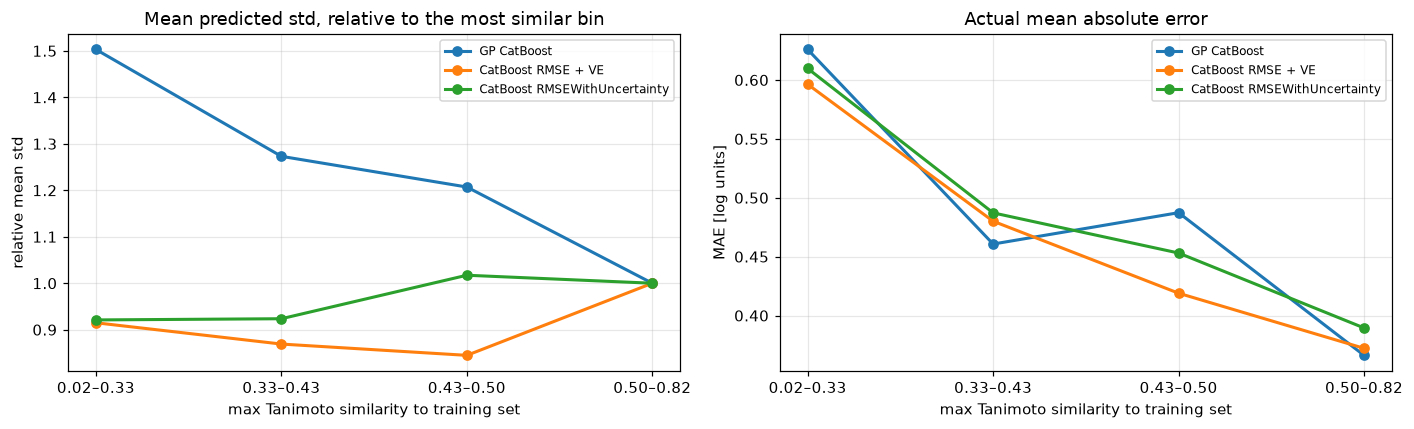

Correlation of max similarity with std on the test set:


,Spearman,Kendall,Pearson
GP CatBoost,-0.41,-0.28,-0.37
CatBoost RMSE + VE,0.05,0.03,0.05
CatBoost RMSEWithUncertainty,0.13,0.08,0.12


In [18]:
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [fp_gen.GetFingerprint(m) for m in mols]
train_fps = [fps[i] for i in train_idx]
max_sim = np.array([max(DataStructs.BulkTanimotoSimilarity(fps[i], train_fps)) for i in test_idx])
sim_bin = pd.qcut(max_sim, q=4)

ood = []
for name, out in results.items():
    mean, std = out["test"]
    frame = pd.DataFrame({"bin": sim_bin, "std": std, "abs_err": np.abs(y_test.values - mean)})
    agg = frame.groupby("bin", observed=True).agg(mean_std=("std", "mean"), mae=("abs_err", "mean"))
    agg["model"] = name
    ood.append(agg)
ood = pd.concat(ood).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
labels = [f"{iv.left:.2f}–{iv.right:.2f}" for iv in sim_bin.categories]
for name, agg in ood.groupby("model", sort=False):
    axes[0].plot(labels, agg["mean_std"] / agg["mean_std"].iloc[-1], "o-", lw=2, label=name)
    axes[1].plot(labels, agg["mae"], "o-", lw=2, label=name)
axes[0].set_title("Mean predicted std, relative to the most similar bin")
axes[0].set_ylabel("relative mean std")
axes[1].set_title("Actual mean absolute error")
axes[1].set_ylabel("MAE [log units]")
for ax in axes:
    ax.set_xlabel("max Tanimoto similarity to training set")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

similarity_correlations = pd.DataFrame(
    {
        name: {
            "Spearman": stats.spearmanr(max_sim, out["test"][1]).statistic,
            "Kendall": stats.kendalltau(max_sim, out["test"][1]).statistic,
            "Pearson": stats.pearsonr(max_sim, out["test"][1]).statistic,
        }
        for name, out in results.items()
    }
).T
print("Correlation of max similarity with std on the test set:")
similarity_correlations.round(2)

For all three models, the actual error rises as test molecules become less similar to the training set. **GP CatBoost is the one whose uncertainty rises with that novelty.** The Spearman correlation between max Tanimoto similarity and std is −0.41. That negative sign is the useful direction for this pairing: similarity is high for familiar molecules, so −0.41 means the std grows as molecules become less like the training set. The two CatBoost uncertainties have no such novelty signal on ESOL (Spearman +0.05 for virtual ensembles and +0.13 for `RMSEWithUncertainty`). They still mark large and small errors at their own extremes (section 4.1). Kendall (−0.28) and Pearson (−0.37) confirm the GP novelty signal; for the two CatBoost scores all three correlations stay close to zero. The novelty signal is the reason to pay for the GP posterior when the question is the applicability domain or which new series to label next.

### 4.5 Inside `RMSEWithUncertainty`: virtual ensembles vs. data uncertainty

`RMSEWithUncertainty` returns two components, and its `total_uncertainty` is $\sqrt{\text{knowledge}^2 + \text{data}^2}$:

* `knowledge_uncertainty`: the spread of the predicted mean over 10 **virtual ensembles**;
* `data_uncertainty`: the **predicted label noise**, i.e. the second output of the loss.

The scatter plot shows how the two components relate for each test molecule; the colour is the absolute error. The
table summarises their size, how each relates to the error (Spearman correlation and the high / low ratio from the
box plots above) and to the similarity to the training set. Section 6.2 adds FreeSolv to the same table.

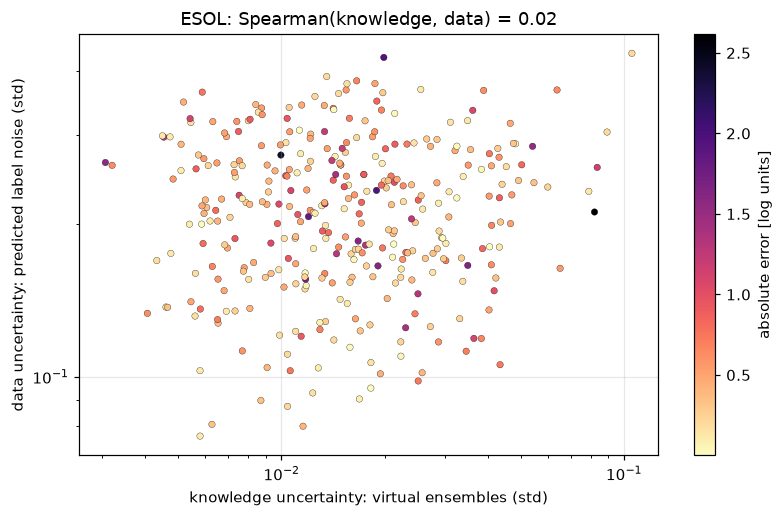

,ESOL
mean knowledge std,0.019
mean data std,0.219
data share of total variance,0.986
"Spearman(knowledge, data)",0.023
"Spearman(knowledge, |err|)",-0.002
"Spearman(data, |err|)",0.119
knowledge: median error high / low 10 %,1.293
knowledge: p-value high > low,0.107
data: median error high / low 10 %,1.498
data: p-value high > low,0.084


In [19]:
def rmse_with_uncertainty_components(frame, y_true, max_similarity, unit, title):
    mean = frame["pred"].to_numpy(float)
    knowledge = frame["knowledge_uncertainty"].to_numpy(float)
    data_unc = frame["data_uncertainty"].to_numpy(float)
    abs_err = np.abs(np.asarray(y_true, float) - mean)

    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    sc = ax.scatter(knowledge, data_unc, c=abs_err, cmap="magma_r", s=18, edgecolor="k", linewidth=0.2)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    plt.colorbar(sc, ax=ax, label=f"absolute error [{unit}]")
    ax.set_xlabel("knowledge uncertainty: virtual ensembles (std)")
    ax.set_ylabel("data uncertainty: predicted label noise (std)")
    ax.set_title(f"{title}: Spearman(knowledge, data) = {stats.spearmanr(knowledge, data_unc).statistic:.2f}")
    plt.tight_layout()
    plt.show()

    knowledge_ratio, knowledge_p = compare_extremes(extreme_groups(y_true, mean, knowledge))
    data_ratio, data_p = compare_extremes(extreme_groups(y_true, mean, data_unc))
    return pd.Series(
        {
            "mean knowledge std": knowledge.mean(),
            "mean data std": data_unc.mean(),
            "data share of total variance": np.mean(data_unc**2 / (knowledge**2 + data_unc**2)),
            "Spearman(knowledge, data)": stats.spearmanr(knowledge, data_unc).statistic,
            "Spearman(knowledge, |err|)": stats.spearmanr(knowledge, abs_err).statistic,
            "Spearman(data, |err|)": stats.spearmanr(data_unc, abs_err).statistic,
            "knowledge: median error high / low 10 %": knowledge_ratio,
            "knowledge: p-value high > low": knowledge_p,
            "data: median error high / low 10 %": data_ratio,
            "data: p-value high > low": data_p,
            "Spearman(knowledge, max similarity)": stats.spearmanr(knowledge, max_similarity).statistic,
            "Spearman(data, max similarity)": stats.spearmanr(data_unc, max_similarity).statistic,
        },
        name=title,
    )


esol_components = rmse_with_uncertainty_components(
    results["CatBoost RMSEWithUncertainty"]["test_frame"], y_test.values, max_sim, "log units", "ESOL"
)
esol_components.round(3).to_frame()

**Reading the result:**

* **The data uncertainty is the total, and that is a feature.** The predicted label noise (mean std about 0.22 log units) is about ten times the virtual-ensemble spread (about 0.02), so it makes up about 99 % of the total variance. `total_uncertainty` is the noise head. Use it when you want that noise, and do not expect the small ensemble term to carry the ranking.
* **The two components measure different things** (Spearman +0.02). A large predicted noise does not mean the virtual ensembles disagree, and the reverse is also true. Keeping both columns is useful even when one of them dominates.
* **On ESOL neither component is the knowledge score.** The data part gives 1.5× between the extremes, the knowledge part 1.3×, neither significant. Their Spearman with max similarity is +0.10 (knowledge) and +0.13 (data). For similarity against uncertainty the useful sign is negative, so these positive values are not a novelty signal: the std is not higher for unfamiliar molecules. ESOL's errors come mostly from chemistry the model has not seen. The virtual ensembles of one boosting run stay close to each other, and the noise head only sees residuals of molecules that were in the training fit. The GP posterior is the score that moves for those unfamiliar molecules (section 4.4).
* The predicted noise of about 0.22 log units is also below the noise floor of about 0.6 fitted in section 4.3, because the noise head is fitted on training residuals, which are smaller than the test errors. Recalibration (section 4.3) is how that width is corrected. The ranking stays as it is.

## 5. Effect of the hyperparameters

* **`samples`.** This needs no refit: `predict_posterior_samples` returns every member's prediction, so we can recompute the mean and std from the first $k$ members. Too few samples give a noisy std estimate.
* **`sigma` and `delta`.** These require refits; each takes as long as the main GP fit above. We try a smaller and a larger `sigma`, and `delta` set to a typical solubility measurement error of about 0.3–0.5 log units.

In [20]:
member_preds = gp_model.predict_posterior_samples(X_test)
rows = {}
for k in [2, 3, 5, 10]:
    mean_k, std_k = member_preds[:k].mean(axis=0), member_preds[:k].std(axis=0)
    rows[k] = {"RMSE": root_mean_squared_error(y_test, mean_k), **uncertainty_metrics(y_test, mean_k, std_k)}
samples_table = pd.DataFrame(rows).T.rename_axis("samples")
samples_table[["RMSE", "mean std", "Spearman(std, |err|)", "coverage 95%", "NLL"]].round(3)

,RMSE,mean std,"Spearman(std, |err|)",coverage 95%,NLL
samples,,,,,
2,0.749,0.302,0.089,0.535,464.595
3,0.698,0.375,0.203,0.681,6.117
5,0.652,0.447,0.226,0.827,1.345
10,0.645,0.487,0.317,0.889,0.998


With 2–3 samples the std estimate is too noisy to be useful. Its ranking quality and coverage are poor, and the NLL explodes because some stds come out close to zero. Quality keeps improving up to 10 samples, so the default of 10 is a sensible minimum. More samples cost proportionally more fit time.

In [21]:
settings = {
    "defaults (sigma=0.1, delta=0)": {},
    "sigma=0.03": {"sigma": 0.03},
    "sigma=0.3": {"sigma": 0.3},
    "delta=0.4": {"delta": 0.4},
}
rows = {}
for label, params in settings.items():
    if params:
        _, out = fit_and_predict(
            ml.CatboostGaussianProcessRegressorMother(**params, random_seed=SEED), "knowledge_uncertainty"
        )
    else:
        out = gp_out
    rows[label] = {
        "RMSE": root_mean_squared_error(y_test, out["test"][0]),
        **uncertainty_metrics(y_test, *out["test"]),
        "fit time [s]": out["fit_seconds"],
    }
sensitivity = pd.DataFrame(rows).T[
    ["RMSE", "mean std", "Spearman(std, |err|)", "coverage 68%", "coverage 95%", "NLL", "fit time [s]"]
]
sensitivity.round(3)

,RMSE,mean std,"Spearman(std, |err|)",coverage 68%,coverage 95%,NLL,fit time [s]
"defaults (sigma=0.1, delta=0)",0.645,0.487,0.317,0.567,0.889,0.998,94.339
sigma=0.03,0.640,0.156,0.316,0.208,0.383,7.794,95.697
sigma=0.3,0.819,1.388,0.334,0.909,0.991,1.342,93.921
delta=0.4,0.641,0.521,0.327,0.602,0.898,0.959,95.206


**Reading the table:**

* **`sigma` sets the width of the uncertainty almost proportionally.** Going from 0.03 to 0.1 to 0.3, the mean std goes from about 0.16 to 0.49 to 1.39, while the *ranking* (Spearman) hardly changes. So `sigma` works like a calibration setting, and it is in target units: here the target std is about 2.1, and the default 0.1 happens to give nearly calibrated intervals. A too-large `sigma` also hurts accuracy (RMSE 0.82 at `sigma=0.3`), because the random prior function is then too large to be fully corrected by the posterior step.
* **`delta`** adds label noise to the posterior fits. At 0.4 it slightly improves RMSE, ranking and NLL, but the std still mainly reflects knowledge uncertainty and widens only a little.

Because `sigma` and `delta` act on the target scale, they can be tuned like other hyperparameters; the model defines a search space via `get_hyperparameter_space`. It tunes `learning_rate`, `prior_iterations`, `sigma`, `delta` and `random_score_type`, and keeps `samples`, `max_depth`, `random_strength`, `eps` and `iterations` as you set them. Alternatively, keep the defaults and recalibrate on held-out data as in section 4.3.

## 6. Second real data set: FreeSolv hydration free energies

[FreeSolv](https://github.com/MobleyLab/FreeSolv) contains 642 small molecules with **experimental hydration free energies** in kcal/mol. It is the full version of the 50-molecule `freesolv_train.csv` used in the other notebooks. Two properties make it a useful second test:

* **A different target scale.** The target std is about 3.9 kcal/mol, compared with about 2.1 for ESOL. Because `sigma` is in target units, we add a fourth model: GP CatBoost fitted on the **standardised target**, with predictions and std transformed back. That is equivalent to choosing `sigma` relative to the target spread.
* **Reported measurement uncertainties.** The database lists an experimental uncertainty for every molecule (0.6 kcal/mol where none was available). That is a real data uncertainty, i.e. the part that knowledge uncertainty leaves out. So we also evaluate $\text{std}_\text{total} = \sqrt{\text{std}^2 + \text{measurement uncertainty}^2}$.

The features, the cluster-based train / calibration / test split and the metrics are the same as for ESOL. With 370 training molecules this data set is smaller and noisier, so the numbers below are less stable than for ESOL.

In [22]:
FREESOLV_URL = "https://raw.githubusercontent.com/MobleyLab/FreeSolv/master/database.txt"
freesolv_columns = [
    "compound_id",
    "smiles",
    "iupac",
    "expt",
    "expt_uncertainty",
    "calc",
    "calc_uncertainty",
    "expt_reference",
    "calc_reference",
    "notes",
]
# '#' is the SMILES triple-bond symbol, so the header lines are skipped instead of parsed as comments
fs_data = pd.read_csv(FREESOLV_URL, sep=";", skiprows=3, header=None, names=freesolv_columns, skipinitialspace=True)
fs_mols = preprocessing.fit_transform(fs_data["smiles"])["Molecule"]
fs_features = (
    sklearn_pipeline.FeatureUnion([("morgan", fg.MorganFingerprints()), ("descriptors", fg.ChemicalDescriptors())])
    .set_output(transform="pandas")
    .fit_transform(fs_mols)
)
fs_features = fs_features.loc[:, fs_features.std() > 0]
fs_y = fs_data["expt"]
fs_measurement_std = fs_data["expt_uncertainty"].to_numpy(float)
fs_groups = (
    cv_module.TanimotoGroupingFromMols(similarity_threshold=0.4).set_output(transform="pandas").fit_transform(fs_mols)
)["tanimoto-group"]

fs_trainval_idx, fs_test_idx = next(outer.split(fs_features, fs_y, fs_groups))
fs_fit_pos, fs_cal_pos = next(inner.split(fs_trainval_idx, groups=fs_groups.iloc[fs_trainval_idx]))
fs_train_idx, fs_cal_idx = fs_trainval_idx[fs_fit_pos], fs_trainval_idx[fs_cal_pos]
print(
    f"molecules: {len(fs_data)}, features: {fs_features.shape[1]}, target std: {fs_y.std():.2f} kcal/mol, "
    f"median measurement uncertainty: {np.median(fs_measurement_std):.2f} kcal/mol"
)
print(f"train {len(fs_train_idx)}, calibration {len(fs_cal_idx)}, test {len(fs_test_idx)}")

[11:28:32] Initializing Normalizer


[11:28:32] Initializing MetalDisconnector


[11:28:32] Initializing Normalizer


molecules: 642, features: 1405, target std: 3.85 kcal/mol, median measurement uncertainty: 0.60 kcal/mol
train 370, calibration 112, test 160


In [23]:
def fit_and_predict_freesolv(model, uncertainty_col, standardise_target=False, **predict_kwargs):
    y_fit = fs_y.iloc[fs_train_idx]
    center, scale = (y_fit.mean(), y_fit.std()) if standardise_target else (0.0, 1.0)
    start = time.time()
    model.fit(fs_features.iloc[fs_train_idx], (y_fit - center) / scale)
    out = {"fit_seconds": time.time() - start}
    for split, idx in [("cal", fs_cal_idx), ("test", fs_test_idx)]:
        unc = model.predict_uncertainty(fs_features.iloc[idx], **predict_kwargs)
        out[split] = (unc["pred"].to_numpy(float) * scale + center, unc[uncertainty_col].to_numpy(float) * scale)
        out[f"{split}_frame"] = unc
    return out


fs_results = {
    "GP CatBoost": fit_and_predict_freesolv(
        ml.CatboostGaussianProcessRegressorMother(random_seed=SEED), "knowledge_uncertainty"
    ),
    "GP CatBoost, standardised target": fit_and_predict_freesolv(
        ml.CatboostGaussianProcessRegressorMother(random_seed=SEED), "knowledge_uncertainty", standardise_target=True
    ),
    "CatBoost RMSE + VE": fit_and_predict_freesolv(
        ml.CatboostRegressorMother(loss_function="RMSE", logging_level="Silent", random_seed=SEED),
        "knowledge_uncertainty",
        n_ensembles=10,
    ),
    "CatBoost RMSEWithUncertainty": fit_and_predict_freesolv(
        ml.CatboostRegressorMother(loss_function="RMSEWithUncertainty", logging_level="Silent", random_seed=SEED),
        "total_uncertainty",
        n_ensembles=10,
    ),
}

In [24]:
fs_y_cal, fs_y_test = fs_y.iloc[fs_cal_idx].to_numpy(float), fs_y.iloc[fs_test_idx].to_numpy(float)
rows = {}
for name, out in fs_results.items():
    (mean_cal, std_cal), (mean, std) = out["cal"], out["test"]
    scale = np.sqrt(np.mean(((fs_y_cal - mean_cal) / np.maximum(std_cal, 1e-9)) ** 2))
    with_noise = uncertainty_metrics(fs_y_test, mean, np.sqrt(std**2 + fs_measurement_std[fs_test_idx] ** 2))
    rows[name] = {
        "RMSE": root_mean_squared_error(fs_y_test, mean),
        "R²": r2_score(fs_y_test, mean),
        "fit time [s]": out["fit_seconds"],
        **uncertainty_metrics(fs_y_test, mean, std),
        "coverage 95% after variance scaling": uncertainty_metrics(fs_y_test, mean, scale * std)["coverage 95%"],
        "coverage 95% with measurement noise": with_noise["coverage 95%"],
        "NLL with measurement noise": with_noise["NLL"],
    }
fs_table = pd.DataFrame(rows).T
fs_table.round(3)

,RMSE,R²,fit time [s],mean std,"Spearman(std, |err|)","Kendall(std, |err|)","Pearson(std, |err|)",coverage 68%,coverage 95%,miscalibration area,NLL,RMSE of 50% most certain,coverage 95% after variance scaling,coverage 95% with measurement noise,NLL with measurement noise
GP CatBoost,1.181,0.864,67.942,0.508,0.267,0.182,0.367,0.538,0.719,0.100,2.324,0.647,0.956,0.850,1.740
"GP CatBoost, standardised target",1.270,0.843,67.939,1.723,0.282,0.188,0.317,0.875,0.969,0.146,1.671,0.993,0.962,0.975,1.707
CatBoost RMSE + VE,1.212,0.857,7.259,0.029,0.174,0.123,0.170,0.025,0.062,0.477,1798.452,0.934,0.975,0.744,15.024
CatBoost RMSEWithUncertainty,1.179,0.864,11.667,0.198,0.519,0.361,0.517,0.219,0.369,0.338,12.007,0.496,0.962,0.775,3.177


**Reading the table:**

* **Accuracy.** All four models are close (RMSE 1.18–1.27 kcal/mol). Fitting GP CatBoost on the standardised target costs a little accuracy (1.27 vs 1.18) and is how `sigma` is put on the right scale.
* **Calibration.** With the default `sigma=0.1` on this larger target, GP CatBoost is over-confident: its 95 % intervals cover 72 %. On the standardised target, coverage is 97 % and the NLL is the best of the four. `sigma` has to match the target scale; once it does, GP CatBoost is a well-scaled knowledge interval.
* **Ranking.** **`RMSEWithUncertainty` is the FreeSolv uncertainty.** Spearman ≈ 0.52, and its most certain half has an RMSE of 0.50 kcal/mol. A few molecules have very large errors, and the noise head picks many of them up. The GP models are the next best knowledge scores (Spearman ≈ 0.27–0.28). Virtual ensembles rank third (Spearman 0.17). Their most certain half still drops from 1.21 to 0.93 kcal/mol RMSE, and section 6.1 shows a clear low tail plus a partial high tail.
* **Recalibration and measurement noise.** After one variance scale on the calibration split, all models reach about 96 % coverage. Adding the reported measurement uncertainty improves every model, most clearly GP CatBoost (72 % → 85 %), which on its own estimates knowledge uncertainty and not assay noise.

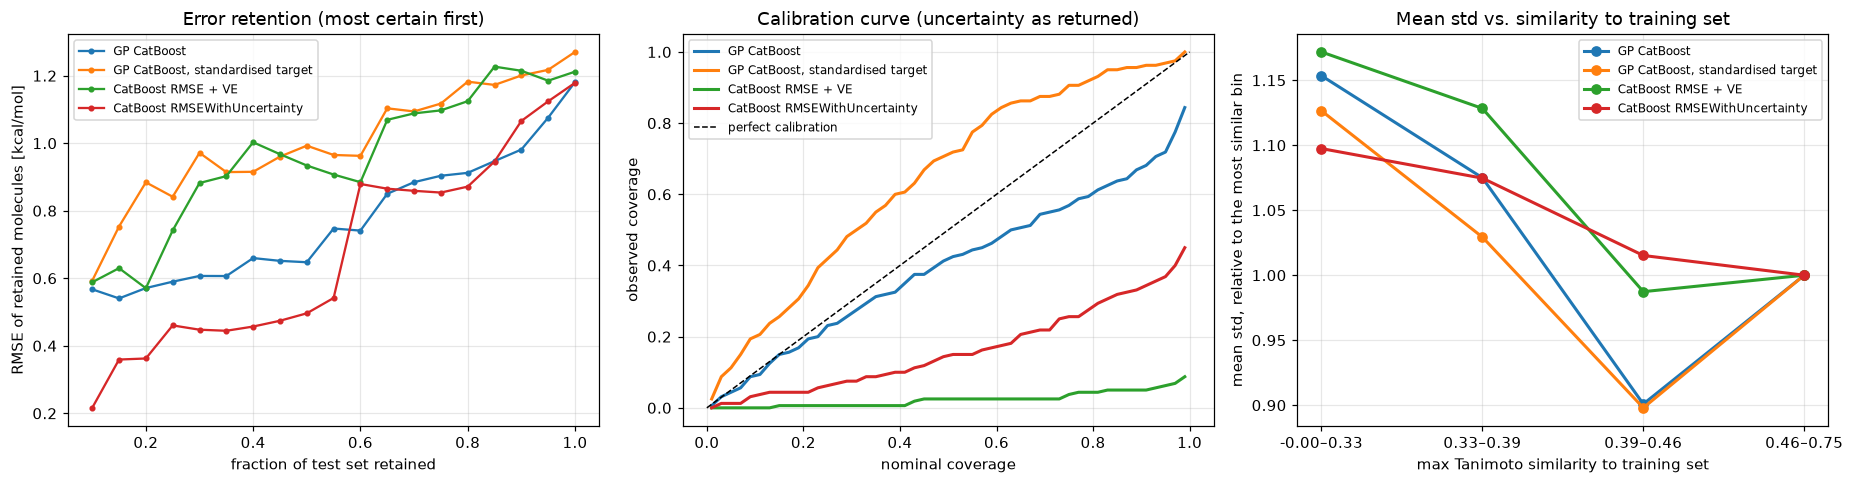

Correlation of max similarity with std on the FreeSolv test set:


,Spearman,Kendall,Pearson
GP CatBoost,-0.18,-0.12,-0.19
"GP CatBoost, standardised target",-0.20,-0.14,-0.19
CatBoost RMSE + VE,-0.17,-0.11,-0.11
CatBoost RMSEWithUncertainty,-0.16,-0.11,-0.04


In [25]:
fs_fps = [fp_gen.GetFingerprint(m) for m in fs_mols]
fs_train_fps = [fs_fps[i] for i in fs_train_idx]
fs_max_sim = np.array([max(DataStructs.BulkTanimotoSimilarity(fs_fps[i], fs_train_fps)) for i in fs_test_idx])
fs_sim_bin = pd.qcut(fs_max_sim, q=4)
bin_labels = [f"{iv.left:.2f}–{iv.right:.2f}" for iv in fs_sim_bin.categories]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, out in fs_results.items():
    mean, std = out["test"]
    abs_err = np.abs(fs_y_test - mean)
    fractions, curve = retention_curve(fs_y_test, mean, std)
    axes[0].plot(fractions, curve, "o-", ms=3, label=name)
    levels, observed, _ = calibration_curve(fs_y_test, mean, std)
    axes[1].plot(levels, observed, lw=2, label=name)
    binned_std = pd.Series(std).groupby(fs_sim_bin, observed=True).mean().to_numpy()
    axes[2].plot(bin_labels, binned_std / binned_std[-1], "o-", lw=2, label=name)
axes[0].set_title("Error retention (most certain first)")
axes[0].set_xlabel("fraction of test set retained")
axes[0].set_ylabel("RMSE of retained molecules [kcal/mol]")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
axes[1].set_title("Calibration curve (uncertainty as returned)")
axes[1].set_xlabel("nominal coverage")
axes[1].set_ylabel("observed coverage")
axes[2].set_title("Mean std vs. similarity to training set")
axes[2].set_xlabel("max Tanimoto similarity to training set")
axes[2].set_ylabel("mean std, relative to the most similar bin")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fs_similarity_correlations = pd.DataFrame(
    {
        name: {
            "Spearman": stats.spearmanr(fs_max_sim, out["test"][1]).statistic,
            "Kendall": stats.kendalltau(fs_max_sim, out["test"][1]).statistic,
            "Pearson": stats.pearsonr(fs_max_sim, out["test"][1]).statistic,
        }
        for name, out in fs_results.items()
    }
).T
print("Correlation of max similarity with std on the FreeSolv test set:")
fs_similarity_correlations.round(2)

The calibration curves show the scale effect directly: the default GP model lies below the diagonal, and the standardised-target GP model lies slightly above it. In the similarity plot all four models give a similar, moderate signal. Spearman between max similarity and std is about −0.16 to −0.20. Negative is again the useful direction: the std is somewhat higher for less similar molecules. The value is only moderate, and it is about the same for all four models, so on FreeSolv the GP has no extra novelty advantage. Kendall gives the same picture (−0.11 to −0.14). Pearson agrees for the GP models (−0.19) but is weaker for the two CatBoost scores (−0.11 and −0.04): their std rises for less similar molecules in rank order, but not in a linear way.

In [26]:
fs_bands = pd.DataFrame(
    {name: error_by_uncertainty_band(fs_y_test, *out["test"]) for name, out in fs_results.items()}
).T
fs_bands.columns.name = "band of predicted std (most certain → least certain)"
fs_bands.round(2)

band of predicted std (most certain → least certain),0%–10%,10%–25%,25%–75%,75%–90%,90%–100%
GP CatBoost,0.51,0.56,0.89,1.36,2.16
"GP CatBoost, standardised target",0.51,0.75,1.00,1.24,1.50
CatBoost RMSE + VE,0.53,0.71,1.05,1.49,0.93
CatBoost RMSEWithUncertainty,0.22,0.57,0.82,1.86,2.05


The bands confirm the ranking, and they also show what the free score is good for.

* **Very low scores:** every model's most certain 10 % have about half the average error or less. For `RMSEWithUncertainty` it is about 0.2×. A low virtual-ensemble score is in that same group: those predictions are the ones to trust.
* **Very high scores:** the least certain 10 % of `RMSEWithUncertainty` and of GP CatBoost have about twice the average error. That is their strength on this set, data noise for one and knowledge disagreement for the other.
* **Virtual ensembles on FreeSolv keep a useful low end, and a softer high end.** The most certain 10 % have 0.53× the average error, next to GP CatBoost's 0.51×, and the 10–25 % band is still 0.71×. The 75–90 % band rises to 1.49×, so a high score still points at larger errors. The single highest 10 % falls back to 0.93×, so that tip is a milder large-error flag than the specialists' top band (about 2×). On ESOL the top band itself was above average (1.15×, section 4.1). The score comes from the RMSE model at no extra fit: trust a very low score on both sets, and on FreeSolv read a high score as a hint rather than as the specialist's high-end list.

### 6.1 Very low vs. very high uncertainty on FreeSolv

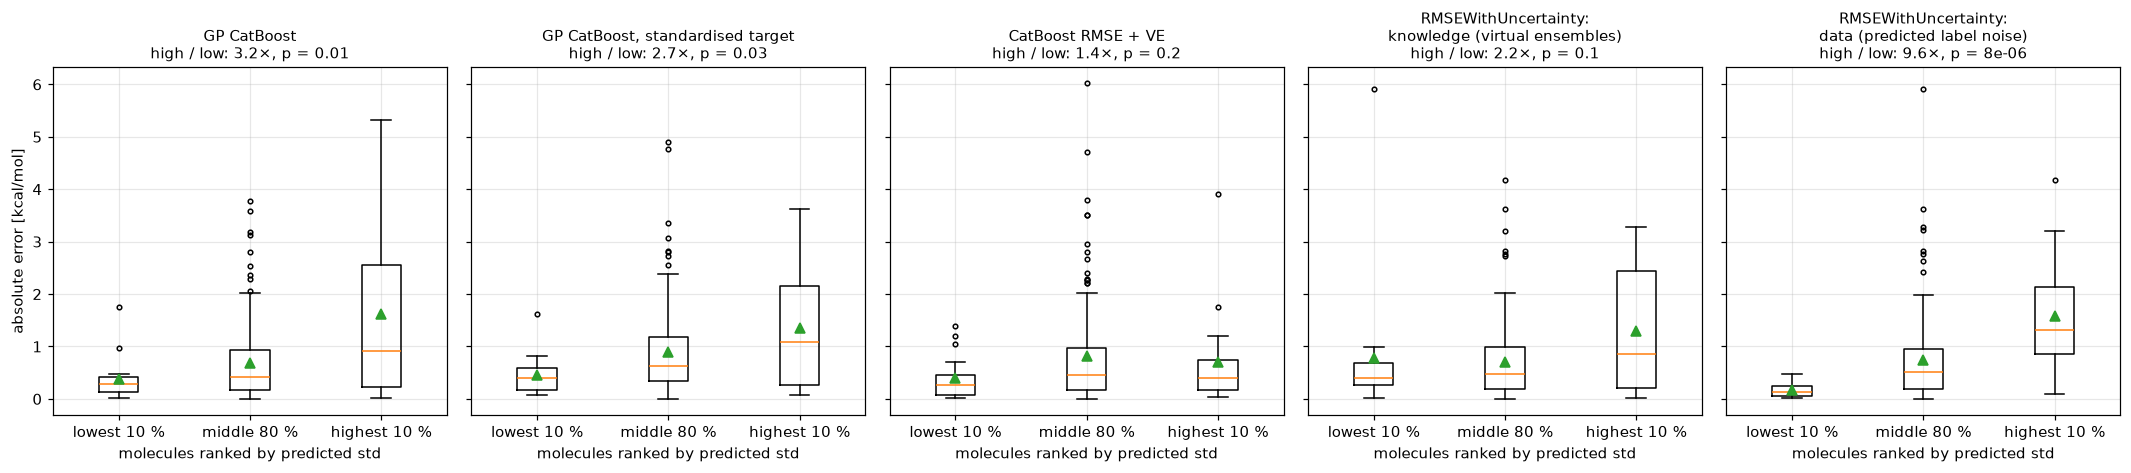

In [27]:
plot_extreme_boxplots(fs_results, fs_y_test, "kcal/mol")

Each score on its own, for FreeSolv. Same reading as on ESOL: the shared figure uses one error axis, and the figures below give each score its own scale. The right panel and the printed medians are the extra information. They show the predicted std inside the lowest 10 %, the middle, and the highest 10 %, so a small virtual-ensemble spread can be read in its own units instead of next to a much wider noise score.

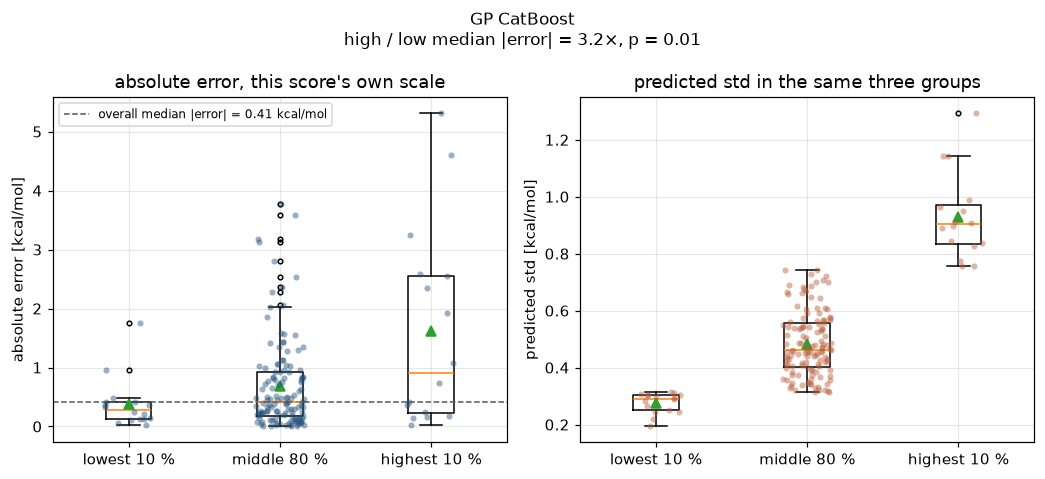

GP CatBoost
                n  median |error|  median predicted std
lowest 10 %    16          0.2832                0.2908
middle 80 %   128          0.4196                0.4615
highest 10 %   16          0.9105                0.9034



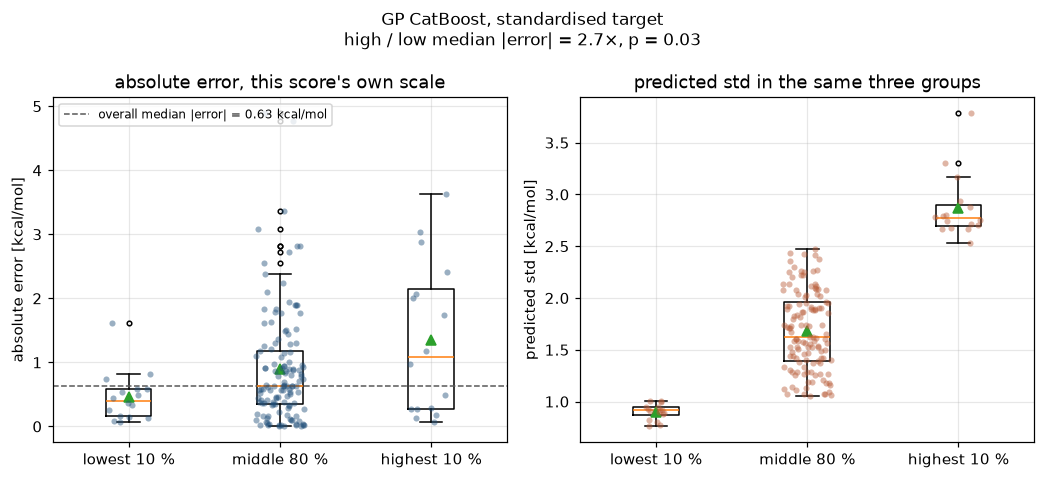

GP CatBoost, standardised target
                n  median |error|  median predicted std
lowest 10 %    16          0.4029                0.9145
middle 80 %   128          0.6304                1.6210
highest 10 %   16          1.0766                2.7681



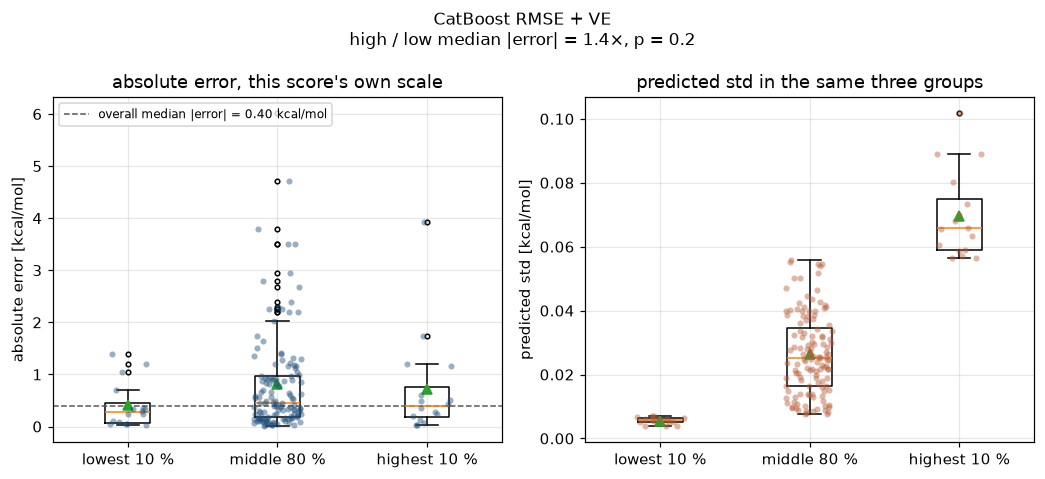

CatBoost RMSE + VE
                n  median |error|  median predicted std
lowest 10 %    16          0.2712                0.0057
middle 80 %   128          0.4568                0.0251
highest 10 %   16          0.3917                0.0657



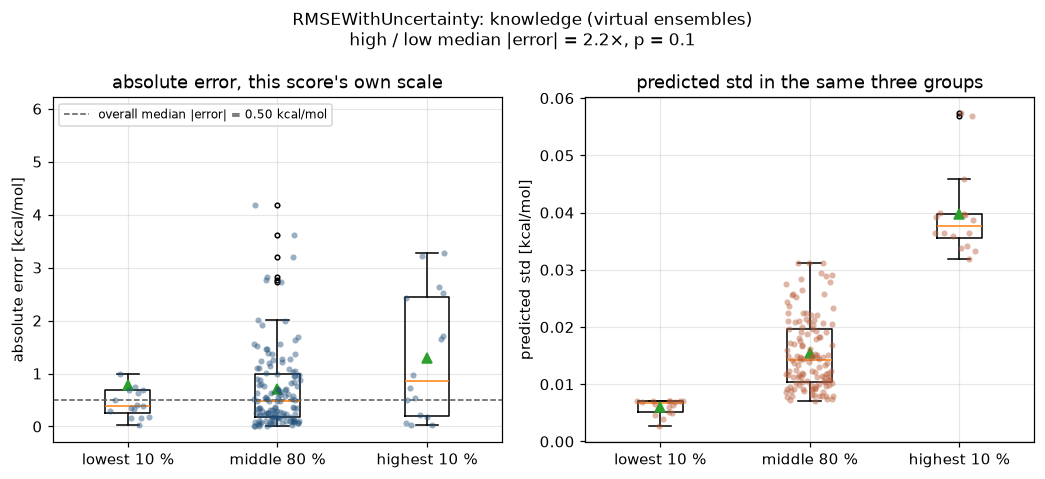

RMSEWithUncertainty: knowledge (virtual ensembles)
                n  median |error|  median predicted std
lowest 10 %    16          0.3925                0.0068
middle 80 %   128          0.4771                0.0143
highest 10 %   16          0.8517                0.0376



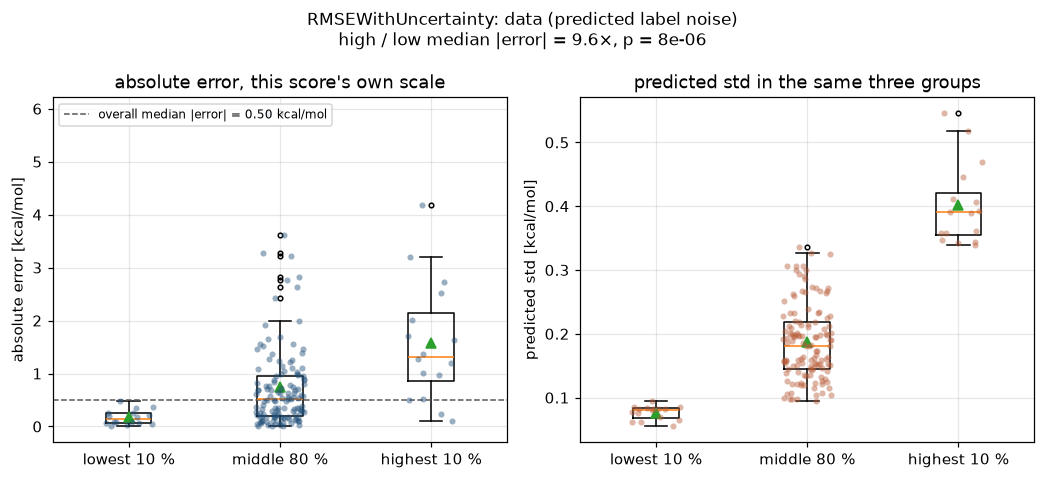

RMSEWithUncertainty: data (predicted label noise)
                n  median |error|  median predicted std
lowest 10 %    16          0.1375                0.0807
middle 80 %   128          0.5147                0.1816
highest 10 %   16          1.3199                0.3902



In [28]:
plot_extreme_details(fs_results, fs_y_test, "kcal/mol")

**Reading the plot:** on FreeSolv each score has a clear job.

* **The data part of `RMSEWithUncertainty`** is the one that separates the extremes: the least certain 10 % have a median error 9.6× that of the most certain 10 % (p ≈ 8·10⁻⁶), and the most certain 10 % are almost all within 0.5 kcal/mol. This is the FreeSolv result.
* **GP CatBoost is the best knowledge uncertainty** (3.2×, p ≈ 0.01; 2.7× on the standardised target). Its least certain box is wide, so a high score mixes large and small errors, but the ordering of the extremes is real and it is the knowledge score to use when the question is unfamiliar chemistry rather than a hard-but-familiar molecule.
* **Virtual ensembles of plain RMSE CatBoost are the free score, and both tails still say something.** The high/low median ratio is 1.4× and is not significant, so the separation is milder than GP CatBoost (3.2×) or the noise head (9.6×). The most certain 10 % still have small errors (0.53× the average error in the band table). On the high side the 75–90 % band is 1.49× the average, while the top 10 % itself is 0.93×, so a high score is a softer hint than a specialist's high score. On ESOL both tails were clearer (1.8×, top band 1.15×). The virtual ensembles inside `RMSEWithUncertainty` are the smaller extra of that loss (2.2×, not significant). The plain RMSE version remains worth computing because it is the virtual ensemble of the fit you already have.

### 6.2 Inside `RMSEWithUncertainty` on FreeSolv

The same decomposition as in section 4.5, with both data sets side by side in the table. FreeSolv also reports an
**experimental uncertainty** for every molecule, so we can check whether the predicted label noise follows it.

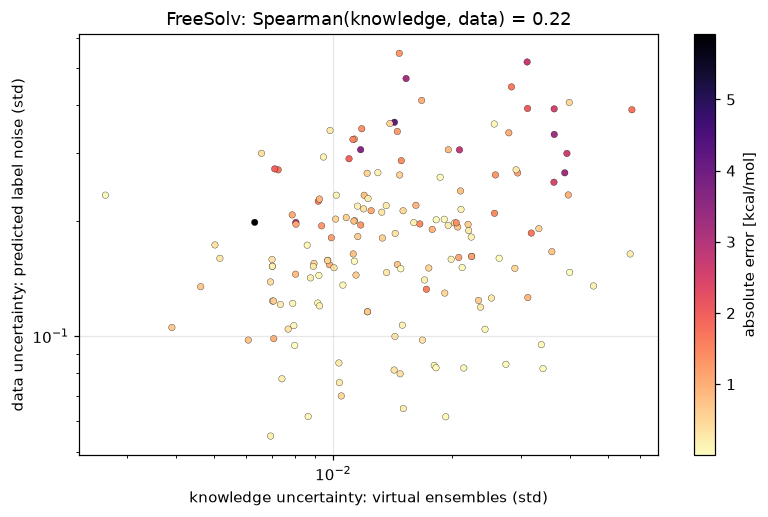

,ESOL,FreeSolv
mean knowledge std,0.019,0.017
mean data std,0.219,0.197
data share of total variance,0.986,0.985
"Spearman(knowledge, data)",0.023,0.222
"Spearman(knowledge, |err|)",-0.002,0.072
"Spearman(data, |err|)",0.119,0.522
knowledge: median error high / low 10 %,1.293,2.170
knowledge: p-value high > low,0.107,0.110
data: median error high / low 10 %,1.498,9.597
data: p-value high > low,0.084,0.000


In [29]:
fs_components = rmse_with_uncertainty_components(
    fs_results["CatBoost RMSEWithUncertainty"]["test_frame"], fs_y_test, fs_max_sim, "kcal/mol", "FreeSolv"
)
fs_predicted_noise = fs_results["CatBoost RMSEWithUncertainty"]["test_frame"]["data_uncertainty"].to_numpy(float)
fs_components["Spearman(data, reported experimental uncertainty)"] = stats.spearmanr(
    fs_predicted_noise, fs_measurement_std[fs_test_idx]
).statistic
pd.concat([esol_components, fs_components], axis=1).round(3)

**Reading the result (data vs. knowledge part of `RMSEWithUncertainty` on both data sets):**

* **The data part dominates the total on both data sets** (about 99 % of the variance; mean std about 0.2 vs.
  about 0.02 for the virtual ensembles).
* **The knowledge part inside this loss is the small term on both data sets:** Spearman with the error is −0.00 on ESOL and +0.07 on FreeSolv; between the extremes 1.3× and 2.2×, neither significant. The plain RMSE virtual ensemble, which is not sharing the fit with a noise head, is the one whose tails are informative on ESOL.
* **The data part depends on the data set:** weak on ESOL (Spearman 0.12; 1.5×) but strong on FreeSolv (Spearman
  0.52; 9.6×).
* **The two parts are unrelated on ESOL and mildly related on FreeSolv** (Spearman 0.02 and 0.22). In the FreeSolv
  scatter the large errors (dark points) sit at high data uncertainty across the whole range of the
  virtual-ensemble spread.
* **The predicted noise is not the measurement noise.** A positive Spearman between predicted noise and the reported experimental uncertainty would mean the noise head tracks the assay error. The value is about −0.10. That is too close to zero to be an inverse relationship: the head does not follow the reported uncertainty. Many FreeSolv rows also carry the default 0.6 kcal/mol, which limits this check. What the noise head learns is which kinds of molecules have large residuals, i.e. compound classes that the features describe poorly. Such molecules also occur in the training set, so their residual size can be learnt. A knowledge uncertainty cannot flag them, because they are not necessarily unfamiliar.

## 7. Discussion: knowledge or data uncertainty?

The two data sets favour different uncertainties. The next cell prints that as two short tables.

* **What the errors look like.** One row is the Spearman correlation between the maximum Tanimoto similarity to the training set and the absolute error of plain CatBoost. Similarity is high for familiar molecules, so a **negative** value means less similar molecules have larger errors. The other row is the share of the squared error that comes from the worst-predicted 10 % of molecules. A share near 1 means a few molecules dominate.
* **What each score does.** Spearman(std, |error|) is **positive** when a higher uncertainty goes with a larger error. High / low is the median absolute error of the least certain 10 % divided by the most certain 10 %. The virtual-ensemble row is the knowledge part inside `RMSEWithUncertainty`, not the plain RMSE virtual ensembles in sections 4.1 and 6.1. GP CatBoost + label noise is $\sqrt{\text{GP std}^2 + \text{label-noise std}^2}$, using the GP uncertainty and the predicted noise of `RMSEWithUncertainty`, around that model's prediction.

In [30]:
def dataset_error_facts(y_true, results_dict, max_similarity):
    """How the errors are spread, using the plain RMSE CatBoost predictions."""
    y_true = np.asarray(y_true, float)
    baseline_err = np.abs(y_true - results_dict["CatBoost RMSE + VE"]["test"][0])
    worst = np.sort(baseline_err**2)[::-1]
    return pd.Series(
        {
            "Spearman(max similarity, |error|)": stats.spearmanr(max_similarity, baseline_err).statistic,
            "Share of squared error from the worst 10 %": worst[: len(worst) // 10].sum() / worst.sum(),
        }
    )


def score_comparison(y_true, results_dict):
    """Spearman and the high/low median-error ratio for each uncertainty score."""
    y_true = np.asarray(y_true, float)
    panels = uncertainty_panels({name: results_dict[name] for name in ["GP CatBoost", "CatBoost RMSEWithUncertainty"]})
    rwu_mean, rwu_data = panels["RMSEWithUncertainty:\ndata (predicted label noise)"]
    panels["GP + label noise"] = (
        rwu_mean,
        np.sqrt(results_dict["GP CatBoost"]["test"][1] ** 2 + rwu_data**2),
    )
    order = [
        ("GP CatBoost", "GP CatBoost"),
        ("RMSEWithUncertainty:\ndata (predicted label noise)", "RMSEWithUncertainty, label noise"),
        ("GP + label noise", "GP CatBoost + label noise"),
        (
            "RMSEWithUncertainty:\nknowledge (virtual ensembles)",
            "RMSEWithUncertainty, virtual ensembles",
        ),
    ]
    rows = {}
    for key, label in order:
        mean, std = panels[key]
        ratio, _ = compare_extremes(extreme_groups(y_true, mean, std))
        rows[label] = {
            "Spearman(std, |error|)": stats.spearmanr(std, np.abs(y_true - mean)).statistic,
            "High / low median |error|": ratio,
        }
    return pd.DataFrame.from_dict(rows, orient="index")


def _show_facts(facts):
    shown = facts.copy()
    for column in ["ESOL", "FreeSolv"]:
        shown.loc["Spearman(max similarity, |error|)", column] = (
            f"{facts.loc['Spearman(max similarity, |error|)', column]:+.2f}"
        )
        shown.loc["Share of squared error from the worst 10 %", column] = (
            f"{facts.loc['Share of squared error from the worst 10 %', column]:.2f}"
        )
    shown.index.name = None
    return shown


def _show_scores(scores):
    shown = scores.copy()
    for dataset in ["ESOL", "FreeSolv"]:
        shown[(dataset, "Spearman(std, |error|)")] = scores[(dataset, "Spearman(std, |error|)")].map(
            lambda value: f"{value:+.2f}"
        )
        shown[(dataset, "High / low median |error|")] = scores[(dataset, "High / low median |error|")].map(
            lambda value: f"{value:.2f}×"
        )
    shown.index.name = "Score"
    return shown


facts = pd.DataFrame(
    {
        "ESOL": dataset_error_facts(y_test, results, max_sim),
        "FreeSolv": dataset_error_facts(fs_y_test, fs_results, fs_max_sim),
    }
)
facts["How to read it"] = [
    "Negative: less similar molecules have larger errors",
    "Closer to 1: a few molecules cause most of the error",
]
scores = pd.concat(
    {
        "ESOL": score_comparison(y_test, results),
        "FreeSolv": score_comparison(fs_y_test, fs_results),
    },
    axis=1,
)

display(Markdown("**What the errors look like** on the plain RMSE CatBoost predictions."))
display(_show_facts(facts))
display(
    Markdown(
        "**What each score does.** Spearman is positive when a higher uncertainty goes with a larger error. "
        "High / low is the median absolute error of the least certain 10 % divided by the most certain 10 %."
    )
)
display(_show_scores(scores))

**What the errors look like** on the plain RMSE CatBoost predictions.

,ESOL,FreeSolv,How to read it
"Spearman(max similarity, |error|)",-0.20,-0.25,Negative: less similar molecules have larger e...
Share of squared error from the worst 10 %,0.52,0.73,Closer to 1: a few molecules cause most of the...


**What each score does.** Spearman is positive when a higher uncertainty goes with a larger error. High / low is the median absolute error of the least certain 10 % divided by the most certain 10 %.

ESOL  \
                                       Spearman(std, |error|)   
Score                                                           
GP CatBoost                                             +0.32   
RMSEWithUncertainty, label noise                        +0.12   
GP CatBoost + label noise                               +0.30   
RMSEWithUncertainty, virtual ensembles                  -0.00   

                                                                  \
                                       High / low median |error|   
Score                                                              
GP CatBoost                                                2.41×   
RMSEWithUncertainty, label noise                           1.50×   
GP CatBoost + label noise                                  2.30×   
RMSEWithUncertainty, virtual ensembles                     1.29×   

                                                     FreeSolv  \
                                       Spearman(std, |error|)   
Score                                                           
GP CatBoost                                             +0.27   
RMSEWithUncertainty, label noise                        +0.52   
GP CatBoost + label noise                               +0.43   
RMSEWithUncertainty, virtual ensembles                  +0.07   

                                                                  
                                       High / low median |error|  
Score                                                             
GP CatBoost                                                3.21×  
RMSEWithUncertainty, label noise                           9.60×  
GP CatBoost + label noise                                  5.59×  
RMSEWithUncertainty, virtual ensembles                     2.17×

**What drives the errors:**

* **Novelty plays a similar role on both data sets.** Spearman between max similarity and absolute error is −0.20 on ESOL and −0.25 on FreeSolv. The negative sign means less similar molecules have larger errors; it is not a bad score. The size is only moderate on both sets, so unfamiliar chemistry alone does not explain why the models rank differently.
* **The difference is how concentrated the errors are.** On FreeSolv the worst 10 % of molecules cause 73 % of the
  squared error (ESOL: 52 %). These hard molecules have relatives in the training set with large residuals, so a model
  that learns the size of the residual, the data part of `RMSEWithUncertainty`, learns to flag them (Spearman 0.52,
  9.6×). On ESOL the error is spread over many molecules and the noise head has little to learn (0.12, 1.5×).
* **Among the knowledge uncertainties, GP CatBoost is the best on both data sets** (Spearman 0.32 and 0.27; 2.4× and
  3.2×). It grows for unfamiliar feature combinations. It does not point at hard molecules that look familiar; that is what the data part is for.
* **Virtual ensembles** are the coarser knowledge score from one boosting run, and the tails are where they earn their keep. On plain RMSE CatBoost the most certain 10 % have 0.70× the average error on ESOL and 0.53× on FreeSolv. The least certain 10 % are above average on ESOL (1.15×; high/low median 1.8×). On FreeSolv the 75–90 % band is 1.49× and the top 10 % is 0.93×, so a high score is a softer hint there. Inside `RMSEWithUncertainty` the same virtual-ensemble term is small (Spearman −0.00 on ESOL and +0.07 on FreeSolv). The plain RMSE version is the score you get without another fit.
* **Combining both** (GP + data) is a robust compromise: Spearman 0.30 on ESOL and 0.43 on FreeSolv (2.3× and 5.6×
  between the extremes). It stays close to the GP on ESOL and between the two specialists on FreeSolv.

**Practical guidance:**

* **GP CatBoost** answers "is this molecule outside what the model knows?": applicability-domain checks, active
  learning, Bayesian optimisation and new chemical series.
* **The data part of `RMSEWithUncertainty`** answers "is this the kind of molecule the model gets badly wrong?". It
  pays off when a few hard or noisy compounds dominate the error, e.g. assays with outliers or mixed measurement
  quality. A quick check in cross-validation: if a small share of molecules causes most of the squared error, the data
  part is likely to help.
* **Virtual ensembles** on a plain RMSE CatBoost when that model is the one you already have. Trust the very low scores on both data sets (0.70× and 0.53× the average error). Treat the very high scores as a review list on ESOL (top band 1.15×, high/low median 1.8×). On FreeSolv read the upper bands as a softer hint (75–90 % at 1.49×); the single highest 10 % is 0.93×, so `RMSEWithUncertainty` or GP CatBoost is the stronger high-end list there. One fitted scale factor turns the std into an interval (section 4.3) and leaves the ranking of molecules unchanged.
* **Both kinds can be combined** by adding the variances, as in the GP CatBoost + label noise row. This needs two fitted
  models, and is the safe choice when you don't know in advance which cause of error dominates.

## 8. Summary

In [31]:
summary = pd.concat([performance[["RMSE", "R²", "fit time [s]"]], uq_raw], axis=1)
summary.round(3)

,RMSE,R²,fit time [s],mean std,"Spearman(std, |err|)","Kendall(std, |err|)","Pearson(std, |err|)",coverage 68%,coverage 95%,miscalibration area,NLL,RMSE of 50% most certain
GP CatBoost,0.645,0.913,94.339,0.487,0.317,0.218,0.327,0.567,0.889,0.082,0.998,0.451
CatBoost RMSE + VE,0.617,0.920,10.106,0.020,0.106,0.072,0.072,0.018,0.035,0.482,1225.822,0.574
CatBoost RMSEWithUncertainty,0.632,0.916,15.985,0.220,0.120,0.082,0.105,0.254,0.553,0.303,4.350,0.574


**The two models:**

* **GP CatBoost** (`CatboostGaussianProcessRegressorMother`) draws `samples` functions from a Gaussian-process
  posterior whose kernel is defined by random oblivious trees, and merges them into **one CatBoost model**. Its std
  is a pure **knowledge** uncertainty: it grows for unfamiliar combinations of features.
* **`RMSEWithUncertainty`** (`CatboostRegressorMother(loss_function="RMSEWithUncertainty")`) predicts the label noise
  of every molecule (**data** uncertainty) plus a knowledge part from virtual ensembles. The data part makes up about
  99 % of its total uncertainty on both data sets.

**How they compare:**

* **Accuracy is close for all of them** (ESOL RMSE 0.62–0.65, FreeSolv 1.18–1.27). GP CatBoost takes about 9× longer to fit because it trains 10 posterior members. The choice is about the uncertainty, not about squeezing RMSE.
* **ESOL, where knowledge uncertainty matters.** Errors are spread over many molecules and grow for unfamiliar chemistry. GP CatBoost is the uncertainty to use: nearly calibrated (89 % coverage of the 95 % interval), the best ranking (Spearman 0.32; 2.4× median error between the least and most certain 10 %), and the uncertainty that rises for molecules unlike the training set. `RMSEWithUncertainty` is honest about a different question and is only modest here (data part 1.5×, its virtual ensembles 1.3×). Plain virtual ensembles still separate the extremes (1.8×) and their most certain molecules have the smallest errors in that panel.
* **FreeSolv, where data uncertainty matters.** The worst 10 % of molecules cause 73 % of the squared error. `RMSEWithUncertainty`'s noise head learns to flag them (Spearman 0.52; 9.6× between the extremes; the most certain 10 % at about 0.2× the average error). GP CatBoost remains the best knowledge score (0.27; 3.2×). Virtual ensembles keep a useful low end (0.53× the average error; most certain half at RMSE 0.93 against 1.21 overall) and a partial high end (75–90 % band 1.49×, top 10 % 0.93×).
* **The learnt noise is hard compound classes, not the reported measurement error.** That is still the right tool when those classes dominate the loss.

**When to use which:**

* **GP CatBoost** for applicability-domain checks, active learning and Bayesian optimisation: whether a molecule lies outside what the model knows.
* **`RMSEWithUncertainty`** when a few hard or noisy compounds dominate the errors, and when you want the prediction and a noise estimate from one model.
* **Virtual ensembles on plain RMSE CatBoost** whenever that model is the one you ship. Very low scores mark smaller errors on both data sets (0.70× and 0.53× the average). Very high scores mark larger errors on ESOL (top band 1.15×, high/low median 1.8×). On FreeSolv a high score is a softer hint (75–90 % band 1.49×; the top 10 % itself is 0.93×). The std needs one scale factor before it is an interval, and that factor needs no extra training. The ranking of the tails comes with the fit.
* **GP and `RMSEWithUncertainty` together** (variances added) when you do not yet know which cause of error dominates (section 7).

**What to watch out for with GP CatBoost:**

* **It detects new feature combinations, not distance.** Extrapolating along a single feature beyond the training range is *not* flagged (section 2.1).
* **It ignores label noise by default.** It returns only knowledge uncertainty, and `delta=0` assumes noise-free labels. Add a noise term (sections 4.3 and 7) or recalibrate on held-out data when calibrated intervals matter.
* **`sigma` sets the interval width and is in target units.** Choose it relative to the target spread or fit on a standardised target; the default 0.1 suited ESOL (target std about 2) and was small for FreeSolv (target std about 4) until the target was standardised, where coverage reached 97 %.
* **Use at least the default 10 samples.** Fit and prediction time grow linearly with `samples`.

**What to watch out for with `RMSEWithUncertainty`:**

* **Its predicted noise is tight as a raw interval** (95 % coverage 37–55 %), because it is fitted on training residuals. Recalibrate on held-out data before reading the width as an interval. The ranking, which is the FreeSolv result, does not depend on that rescaling.
* **It does not replace a knowledge score for unfamiliar chemistry.** On ESOL neither component rose for molecules unlike the training set. Use GP CatBoost for that question.

**What to watch out for with virtual ensembles:**

* **The raw std is a stability, not a full error bar** (about 25× smaller than the errors on ESOL). Rescale once if you need coverage. Do not rescale if you only need to sort molecules.
* **The middle of the ranking is flatter than the tails.** The overall Spearman is 0.11 on ESOL and 0.17 on FreeSolv. Act on the very low scores on both sets, and on the high scores with the strength the set supports: a review list on ESOL, a softer hint on FreeSolv.

## 9. Further estimates: MultiQuantile, bootstrap, and the per-molecule plots

Sections 1 to 8 compare GP CatBoost, plain RMSE virtual ensembles and `RMSEWithUncertainty`. This section keeps the other two estimates from this tutorial, and the plots that show one score molecule by molecule.

Everything is computed on the FreeSolv split from section 6, so the new scores sit next to `fs_results` rather than on a second, smaller cut of the data. Feature selection is fit on the training fold and reported. The uncertainty numbers use the same full feature matrix as section 6, so a difference between methods is a difference of estimator.

Two views are coarser than the 10 % tails in sections 4.1 and 6.1, and they are still worth keeping:

* The **scatter** marks molecules whose absolute error, or whose uncertainty, sits above the 95 % z-score line, and it prints Pearson and Spearman to two decimal places.
* The **quartile boxes** and an **ANOVA** ask whether the four uncertainty bins have different errors. A flat middle can hide a useful tail, so read these next to the 10 % bands rather than instead of them.


### 9.1 The columns, and the two tutorial plots

For a single target the columns are:

| Column | What it is |
|---|---|
| `pred` | The prediction to use. For MultiQuantile this is the median. For GP CatBoost it is the mean of the posterior samples. |
| `mean_predictions` | The virtual-ensemble mean, when the model has one. Empty for GP CatBoost and for MultiQuantile. |
| `knowledge_uncertainty` | Disagreement: virtual ensembles, bootstrap spread, or the GP posterior std. |
| `data_uncertainty` | Predicted label noise. Filled by `RMSEWithUncertainty`. |
| `total_uncertainty` | For `RMSEWithUncertainty`, √(knowledge² + data²). For MultiQuantile, the interquartile range. |

A column is empty when that loss does not estimate it. Virtual ensembles are CatBoost's [virtual ensemble prediction](https://catboost.ai/docs/en/concepts/python-reference_virtual_ensembles_predict): sub-models taken from the later stages of one boosting run.


In [32]:
def plot_uncertainty_vs_error(
    data, uncertainty_col, prediction_error_col, mae, rmse, r2, z_threshold=1.96, title="Dataset"
):
    """Scatter of one uncertainty against absolute error, with the 95% z-score lines."""
    data = data.copy()
    prediction_error = data[prediction_error_col]
    uncertainty = data[uncertainty_col]
    error_cut = prediction_error.mean() + z_threshold * prediction_error.std(ddof=1)
    uncertainty_cut = uncertainty.mean() + z_threshold * uncertainty.std(ddof=1)
    error_tail = prediction_error > error_cut
    uncertainty_tail = uncertainty > uncertainty_cut

    pearson, pearson_p = stats.pearsonr(uncertainty, prediction_error)
    spearman, spearman_p = stats.spearmanr(uncertainty, prediction_error)

    error_group = "error group"
    uncertainty_group = "uncertainty group"
    data[error_group] = ["above 95% z" if flag else "within 95% z" for flag in error_tail]
    data[uncertainty_group] = ["above 95% z" if flag else "within 95% z" for flag in uncertainty_tail]

    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        x=uncertainty_col,
        y=prediction_error_col,
        data=data,
        hue=error_group,
        style=uncertainty_group,
        palette={"within 95% z": "#4c78a8", "above 95% z": "#e45756"},
        s=70,
    )
    x_line = np.asarray(uncertainty, float)
    y_line = np.asarray(prediction_error, float)
    if np.unique(x_line).size > 1:
        slope, intercept = np.polyfit(x_line, y_line, 1)
        order = np.argsort(x_line)
        plt.plot(x_line[order], slope * x_line[order] + intercept, color="0.4", lw=1.2, label="linear trend")
    plt.axhline(error_cut, color="#e45756", linestyle="--", linewidth=0.9, label="error z = 1.96")
    plt.axvline(uncertainty_cut, color="#4c78a8", linestyle="--", linewidth=0.9, label="uncertainty z = 1.96")
    plt.text(
        1.02,
        0.02,
        f"MAE {mae:.2f}\nRMSE {rmse:.2f}\nR² {r2:.2f}",
        transform=plt.gca().transAxes,
        fontsize=11,
        ha="left",
        va="bottom",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "0.7", "boxstyle": "round"},
    )
    plt.title(f"{title}\nPearson {pearson:+.2f} (p = {pearson_p:.2g}), Spearman {spearman:+.2f} (p = {spearman_p:.2g})")
    plt.xlabel(uncertainty_col)
    plt.ylabel("absolute error [kcal/mol]")
    plt.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_boxplot_and_coverage(data, uncertainty_col, prediction_error_col, z_threshold=1.96, title="Dataset"):
    """Quartile boxes of absolute error, plus the share of errors above the 95% z-score line."""
    data = data.copy()
    data["uncertainty_bin"] = pd.qcut(
        data[uncertainty_col], q=4, labels=["Low", "Medium", "High", "Very High"], duplicates="drop"
    )
    error_cut = data[prediction_error_col].mean() + z_threshold * data[prediction_error_col].std(ddof=1)
    coverage = (
        data.groupby("uncertainty_bin", observed=True)[prediction_error_col]
        .apply(lambda values: 100.0 * (values > error_cut).mean())
        .reset_index()
    )

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), gridspec_kw={"height_ratios": [3, 1], "hspace": 0.45})
    sns.boxplot(
        x="uncertainty_bin",
        y=prediction_error_col,
        data=data,
        hue="uncertainty_bin",
        palette="Blues",
        showfliers=False,
        width=0.6,
        legend=False,
        ax=ax1,
    )
    sns.stripplot(
        x="uncertainty_bin",
        y=prediction_error_col,
        data=data,
        color="black",
        alpha=0.35,
        jitter=0.2,
        size=3.5,
        ax=ax1,
    )
    ax1.axhline(error_cut, color="#e45756", linestyle="--", label="error z = 1.96")
    ax1.set_title(title)
    ax1.set_xlabel("uncertainty quartile")
    ax1.set_ylabel("absolute error [kcal/mol]")
    ax1.legend(fontsize=8)

    sns.barplot(
        x="uncertainty_bin",
        y=prediction_error_col,
        data=coverage,
        hue="uncertainty_bin",
        palette="Oranges",
        dodge=False,
        legend=False,
        ax=ax2,
    )
    ax2.set_title("Share of molecules with absolute error above the z = 1.96 line")
    ax2.set_xlabel("uncertainty quartile")
    ax2.set_ylabel("% above the line")
    ax2.set_ylim(0, 100)
    for patch in ax2.patches:
        height = patch.get_height()
        ax2.annotate(
            f"{height:.1f}%",
            (patch.get_x() + patch.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 2),
            textcoords="offset points",
        )
    plt.tight_layout()
    plt.show()


def describe_score(name, frame, y_true):
    """Print two-decimal rank correlation and accuracy for one uncertainty column."""
    err = frame["prediction_error"].to_numpy(float)
    unc = frame["uncertainty"].to_numpy(float)
    spearman, spearman_p = stats.spearmanr(unc, err)
    mae = mean_absolute_error(y_true, frame["target_pred"])
    rmse = root_mean_squared_error(y_true, frame["target_pred"])
    r2 = r2_score(y_true, frame["target_pred"])
    print(f"{name}: Spearman {spearman:+.2f} (p = {spearman_p:.2g}), MAE {mae:.2f}, RMSE {rmse:.2f}, R² {r2:.2f}")
    return mae, rmse, r2


def anova_by_quartile(name, frame):
    """One-way ANOVA of absolute error across the four uncertainty quartiles."""
    binned = frame.copy()
    binned["uncertainty_bin"] = pd.qcut(
        binned["uncertainty"], q=4, labels=["Low", "Medium", "High", "Very High"], duplicates="drop"
    )
    samples = [
        group["prediction_error"].to_numpy(float) for _, group in binned.groupby("uncertainty_bin", observed=True)
    ]
    f_stat, p_value = stats.f_oneway(*samples)
    print(f"{name}: ANOVA F = {f_stat:.2f}, p = {p_value:.2g}")


y_fs = fs_y.iloc[fs_test_idx].to_numpy(float)
score_frames = {}


def add_score(name, pred, uncertainty):
    pred = np.asarray(pred, float)
    score_frames[name] = pd.DataFrame(
        {
            "target_pred": pred,
            "prediction_error": np.abs(y_fs - pred),
            "uncertainty": np.asarray(uncertainty, float),
        }
    )


for name in ["GP CatBoost", "CatBoost RMSE + VE", "CatBoost RMSEWithUncertainty"]:
    pred, std = fs_results[name]["test"]
    add_score(name, pred, std)

rwu_test = fs_results["CatBoost RMSEWithUncertainty"]["test_frame"]
add_score("RMSEWithUncertainty knowledge", rwu_test["pred"], rwu_test["knowledge_uncertainty"])
add_score("RMSEWithUncertainty data", rwu_test["pred"], rwu_test["data_uncertainty"])

print("Scores already fit in section 6, read here one molecule at a time:")
for name, frame in score_frames.items():
    describe_score(name, frame, y_fs)

Scores already fit in section 6, read here one molecule at a time:
GP CatBoost: Spearman +0.27 (p = 0.00065), MAE 0.75, RMSE 1.18, R² 0.86
CatBoost RMSE + VE: Spearman +0.17 (p = 0.028), MAE 0.76, RMSE 1.21, R² 0.86
CatBoost RMSEWithUncertainty: Spearman +0.52 (p = 2.1e-12), MAE 0.77, RMSE 1.18, R² 0.86
RMSEWithUncertainty knowledge: Spearman +0.07 (p = 0.37), MAE 0.77, RMSE 1.18, R² 0.86
RMSEWithUncertainty data: Spearman +0.52 (p = 1.4e-12), MAE 0.77, RMSE 1.18, R² 0.86


### 9.2 How to read the quartiles

The Spearman values just printed are the same ranking as section 6, now to two decimal places, with the knowledge part and the data part of `RMSEWithUncertainty` shown on their own.

* A **very low** virtual-ensemble score is the part to trust on this set (0.53× the average error in the lowest 10 %). The quartile plot is coarser: the lowest quarter mixes that tail with molecules that are only moderately certain.
* A **very high** virtual-ensemble score is a softer hint here. The 75–90 % band is 1.49× the average error and the top 10 % is 0.93×, so the top quartile is a mixture. On ESOL the top 10 % itself was above average (1.15×).
* The **data part** is the FreeSolv score (Spearman 0.52 in section 6). The knowledge part inside that same loss is the small term (Spearman +0.07).
* GP CatBoost remains the knowledge score (Spearman 0.27; 3.2× between the extreme 10 % tails).

The figures in section 9.5 draw every score with the same two plots, after MultiQuantile and the bootstrap have been added.


### 9.3 Feature selection in the training pipeline

The original form of this tutorial wrapped every model in Mother's feature-selection pipeline: drop constant and duplicate columns, drop correlated columns, then drop columns with negligible CatBoost importance. That pipeline is still the right tool when you want it. It is fit here on the FreeSolv **training** fold only, and the count of remaining columns is printed.

The scores above and below keep the full non-constant matrix from section 6. Mixing a selected matrix into only some of the methods would make the comparison about the features as well as about the uncertainty.


In [33]:
model_settings = {
    "feature_selection_flags": ["DROP_CORRELATED", "DROP_CONSTANT", "DROP_DUPLICATES", "DROP_UNIMPORTANT"],
    "feature_selection_threshold": 1e-4,
    "correlation_threshold": 0.8,
    "algorithm": "catboost",
    "feature_selection_type": "catboost",
    "cv": GroupKFold(n_splits=5),
    "target_type": "single_target",
    "model_type": "regression",
}
pipeline_settings = {"remainder": "passthrough", "verbose_feature_names_out": False}

feature_selector = mother_takes_care.get_feature_selection_pipeline(
    settings=model_settings, pipeline_settings=pipeline_settings
).set_output(transform="pandas")
X_train_selected = feature_selector.fit_transform(fs_features.iloc[fs_train_idx], fs_y.iloc[fs_train_idx])
print(f"training features before selection: {fs_features.shape[1]}, after selection: {X_train_selected.shape[1]}")

training features before selection: 1405, after selection: 304


### 9.4 MultiQuantile

Quantile regression predicts chosen levels of the conditional distribution. Passing `quantiles` to `CatboostRegressorMother` selects the MultiQuantile loss; there is no separate `loss_function` to set. Mother always adds the quartiles 0.25, 0.5 and 0.75 to the list you give. With `return_quantiles=True`, `predict_uncertainty` returns the usual table plus one column per quantile.

In that table, `pred` is the median and `total_uncertainty` is the interquartile range, Q3 − Q1. The spread of the five requested quantiles, their standard deviation, is the extra uncertainty this tutorial originally plotted. Both are kept. Neither one is a split into knowledge and data uncertainty: the quantile model does not estimate those two parts.

A rise in absolute error toward high uncertainty is the useful direction for this score. Section 9.7 draws the predicted quantiles themselves as a box for each molecule: a narrow box is a tight prediction, a wide box is an uncertain one, and the measured value is a point on that box.

In [34]:
quantiles = [0.1, 0.3, 0.5, 0.7, 0.9]
model_quantiles = ml.CatboostRegressorMother(quantiles=quantiles, logging_level="Silent", random_seed=SEED)
model_quantiles.fit(fs_features.iloc[fs_train_idx], fs_y.iloc[fs_train_idx])

quantile_table, quantile_array = model_quantiles.predict_uncertainty(
    fs_features.iloc[fs_test_idx], return_quantiles=True
)
quantile_levels = sorted({*quantiles, 0.25, 0.5, 0.75})
df_res_quant = pd.DataFrame(
    quantile_array,
    columns=[f"quantile_{level:g}" for level in quantile_levels],
    index=fs_features.iloc[fs_test_idx].index,
)
requested = df_res_quant[[f"quantile_{level:g}" for level in quantiles]]

add_score("MultiQuantile IQR", quantile_table["pred"], quantile_table["total_uncertainty"])
add_score("MultiQuantile std of quantiles", quantile_table["pred"], requested.std(axis=1, ddof=1))
for name in ["MultiQuantile IQR", "MultiQuantile std of quantiles"]:
    describe_score(name, score_frames[name], y_fs)
requested.head()

MultiQuantile IQR: Spearman +0.36 (p = 2.3e-06), MAE 0.79, RMSE 1.18, R² 0.86
MultiQuantile std of quantiles: Spearman +0.44 (p = 3.9e-09), MAE 0.79, RMSE 1.18, R² 0.86


,quantile_0.1,quantile_0.3,quantile_0.5,quantile_0.7,quantile_0.9
6,-2.158238,-1.952154,-1.993709,-2.015166,-1.904479
8,2.343699,2.467756,2.378796,2.449839,2.562336
9,-2.367813,-2.161828,-2.155788,-1.958774,-1.798808
14,-0.716303,-0.687648,-0.655459,-0.693650,-0.598202
17,1.971580,2.079771,2.086927,2.065781,2.188864


### 9.5 Bootstrap

A bootstrap refits the plain RMSE model on resampled training rows and takes the standard deviation of the test predictions. That spread is a knowledge uncertainty. It answers a similar question to virtual ensembles, at a different price: virtual ensembles reuse the trees of one fit, while each bootstrap draw is a new fit. The GP posterior is a third knowledge score, drawn from the boosting-as-GP sampler rather than from resampled rows.

`n_bootstrap` is the number of refits. The call below uses 10, the same count as the virtual ensembles in section 6. The function itself takes any count; a longer run, such as 50 resamples, tightens the estimate of the spread and multiplies the training time.


In [35]:
def bootstrap_model_uncertainty(X_train, y_train, X_test, y_test, n_bootstrap=10, random_state=SEED):
    """Refit RMSE CatBoost on bootstrap samples and return the mean and the std of the predictions."""
    predictions = []
    for draw in range(n_bootstrap):
        X_resampled, y_resampled = resample(X_train, y_train, random_state=random_state + draw)
        model = ml.CatboostRegressorMother(
            loss_function="RMSE", logging_level="Silent", random_seed=random_state + draw
        )
        model.fit(X_resampled, y_resampled)
        predictions.append(np.asarray(model.predict(X_test), dtype=float))
    stacked = np.vstack(predictions)
    mean_predictions = stacked.mean(axis=0)
    return pd.DataFrame(
        {
            "target_pred": mean_predictions,
            "mean_predictions": mean_predictions,
            "knowledge_uncertainty": stacked.std(axis=0, ddof=1),
            "prediction_error": np.abs(np.asarray(y_test, dtype=float) - mean_predictions),
        },
        index=X_test.index,
    )


bootstrap_results = bootstrap_model_uncertainty(
    X_train=fs_features.iloc[fs_train_idx],
    y_train=fs_y.iloc[fs_train_idx],
    X_test=fs_features.iloc[fs_test_idx],
    y_test=y_fs,
    n_bootstrap=10,
)
add_score("Bootstrap", bootstrap_results["target_pred"], bootstrap_results["knowledge_uncertainty"])
describe_score("Bootstrap", score_frames["Bootstrap"], y_fs)
bootstrap_results.head()

Bootstrap: Spearman +0.45 (p = 2.1e-09), MAE 0.83, RMSE 1.29, R² 0.84


,target_pred,mean_predictions,knowledge_uncertainty,prediction_error
6,-2.047284,-2.047284,0.194798,1.067284
8,2.326939,2.326939,0.187111,0.563061
9,-1.997994,-1.997994,0.168553,0.407994
14,-0.785348,-0.785348,0.118797,0.535348
17,2.015458,2.015458,0.164543,0.494542


### 9.6 Ranking, bands, and tails for MultiQuantile and bootstrap

These are the same views as in sections 4.1 and 6.1, restricted to the two scores that sections 1–8 do not already plot: the MultiQuantile interquartile range, the standard deviation of the five requested quantiles, and the bootstrap. Both MultiQuantile rows share one prediction, the median. They differ only in which width is used to rank the molecules.

The grey dotted line on the retention plot is the RMSE of the whole test set, the result of keeping molecules in a random order. The black dashed line is the oracle, molecules ordered by their true error. A useful score is a solid curve that drops below the dotted line as uncertain molecules are left out.


,mean std,"Spearman(std, |err|)","Kendall(std, |err|)","Pearson(std, |err|)",coverage 68%,coverage 95%,miscalibration area,NLL,RMSE of 50% most certain
MultiQuantile IQR,0.24,0.38,0.26,0.37,0.21,0.31,0.37,1.005211e+17,0.72
MultiQuantile std,0.23,0.44,0.30,0.51,0.21,0.39,0.34,1.844000e+01,0.57
Bootstrap,0.32,0.45,0.32,0.54,0.30,0.46,0.28,5.060000e+00,0.52


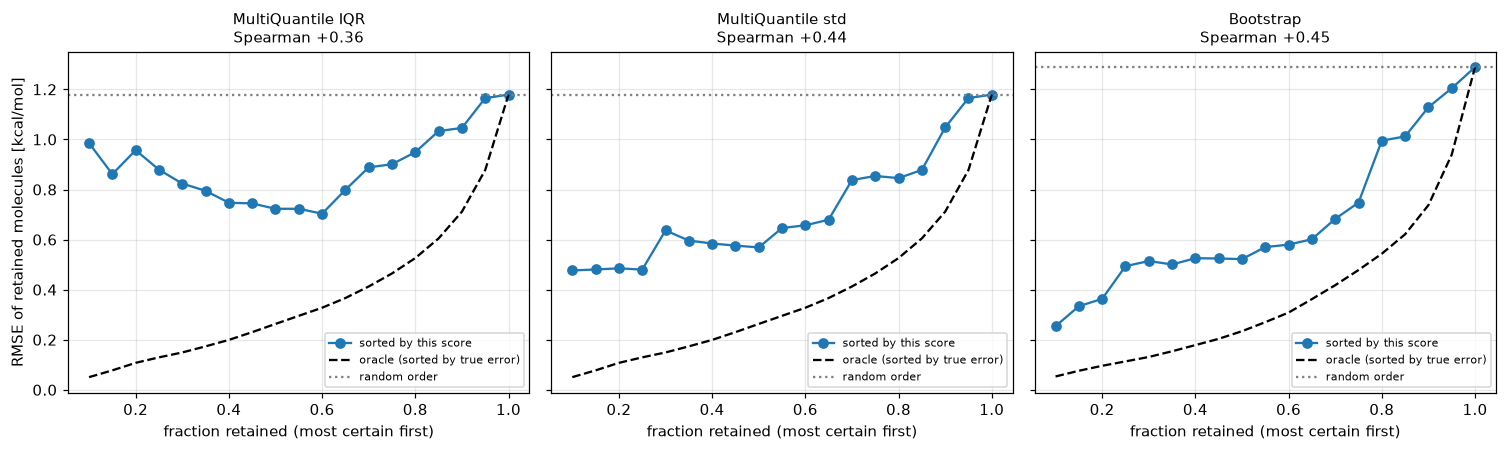

band of the score (most certain → least certain),0%–10%,10%–25%,25%–75%,75%–90%,90%–100%
MultiQuantile IQR,0.86,0.66,0.78,1.48,2.05
MultiQuantile std,0.51,0.48,0.85,1.49,2.26
Bootstrap,0.26,0.57,0.76,1.91,2.23


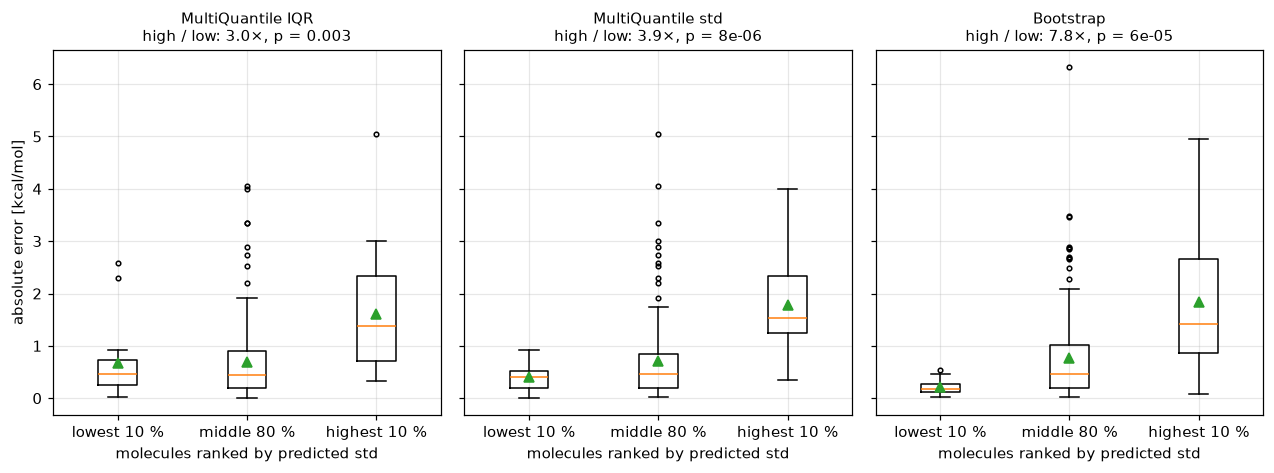

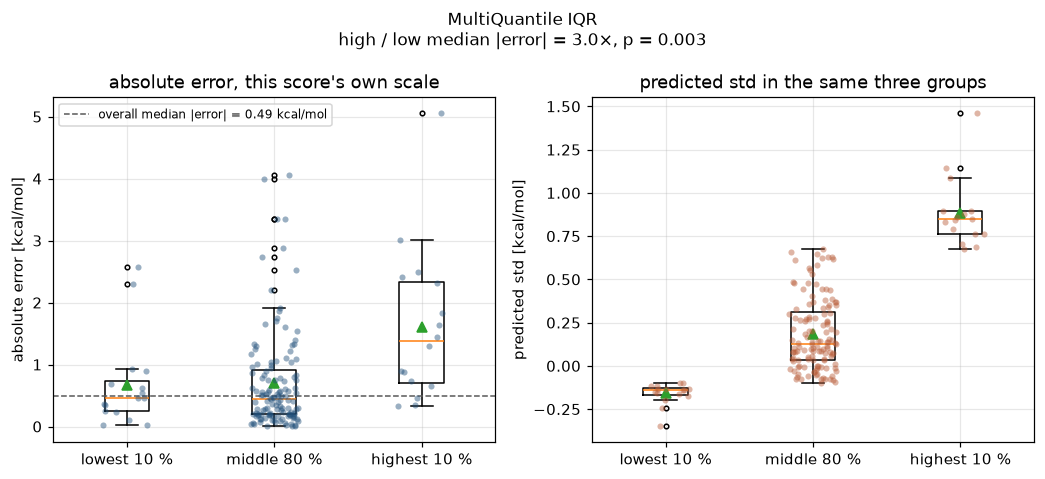

MultiQuantile IQR
                n  median |error|  median predicted std
lowest 10 %    16          0.4548               -0.1380
middle 80 %   128          0.4457                0.1287
highest 10 %   16          1.3773                0.8470



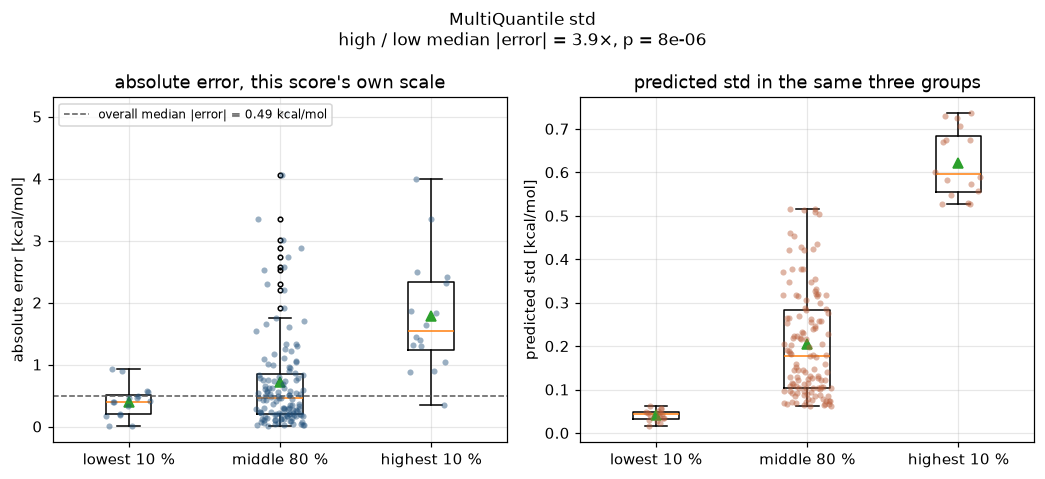

MultiQuantile std
                n  median |error|  median predicted std
lowest 10 %    16          0.3984                0.0427
middle 80 %   128          0.4584                0.1773
highest 10 %   16          1.5409                0.5954



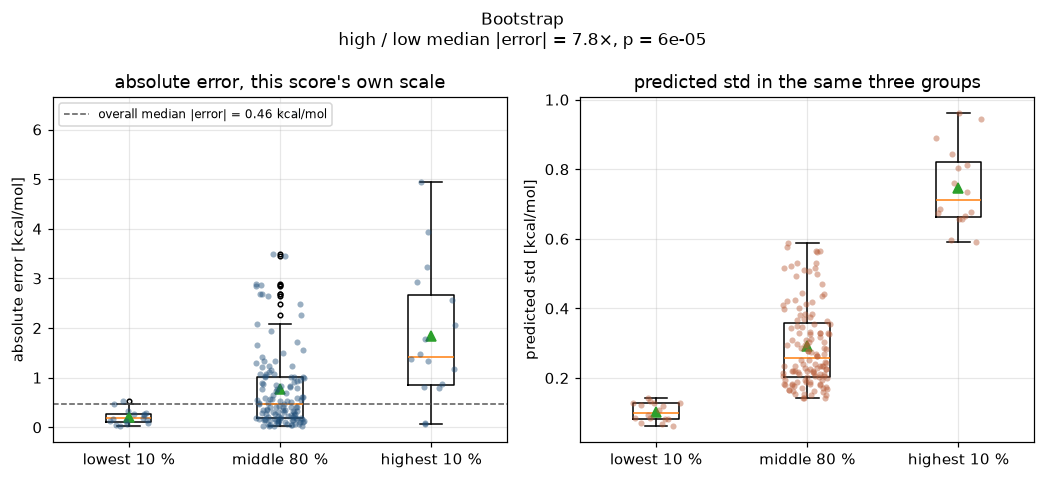

Bootstrap
                n  median |error|  median predicted std
lowest 10 %    16          0.1838                0.1007
middle 80 %   128          0.4681                0.2573
highest 10 %   16          1.4246                0.7111



In [36]:
extra_results = {
    "MultiQuantile IQR": {
        "test": (np.asarray(quantile_table["pred"], float), np.asarray(quantile_table["total_uncertainty"], float))
    },
    "MultiQuantile std": {
        "test": (np.asarray(quantile_table["pred"], float), np.asarray(requested.std(axis=1, ddof=1), float))
    },
    "Bootstrap": {
        "test": (
            np.asarray(bootstrap_results["target_pred"], float),
            np.asarray(bootstrap_results["knowledge_uncertainty"], float),
        )
    },
}

extra_metrics = pd.DataFrame({name: uncertainty_metrics(y_fs, *out["test"]) for name, out in extra_results.items()}).T
display(extra_metrics.round(2))

fig, axes = plt.subplots(1, len(extra_results), figsize=(4.6 * len(extra_results), 4.2), sharey=True)
for ax, (name, out) in zip(axes, extra_results.items()):
    mean, std = out["test"]
    abs_err = np.abs(y_fs - mean)
    fractions, curve = retention_curve(y_fs, mean, std)
    _, oracle = retention_curve(y_fs, mean, abs_err)
    ax.plot(fractions, curve, "o-", label="sorted by this score")
    ax.plot(fractions, oracle, "k--", label="oracle (sorted by true error)")
    ax.axhline(root_mean_squared_error(y_fs, mean), color="grey", ls=":", label="random order")
    spearman, _ = stats.spearmanr(std, abs_err)
    ax.set_title(f"{name}\nSpearman {spearman:+.2f}", fontsize=10)
    ax.set_xlabel("fraction retained (most certain first)")
    ax.legend(fontsize=7)
axes[0].set_ylabel("RMSE of retained molecules [kcal/mol]")
fig.tight_layout()
plt.show()

extra_bands = pd.DataFrame(
    {name: error_by_uncertainty_band(y_fs, *out["test"]) for name, out in extra_results.items()}
).T
extra_bands.columns.name = "band of the score (most certain → least certain)"
display(extra_bands.round(2))

plot_extreme_boxplots(extra_results, y_fs, "kcal/mol")
plot_extreme_details(extra_results, y_fs, "kcal/mol")

**How to read these plots.** A score that is working has three visible signs, and they agree with each other.

* On the retention plot the solid curve falls below the grey dotted line. Leaving out the high scores improves the RMSE.
* In the band table the right-hand columns, the least certain molecules, sit above 1, and the left-hand columns sit below 1. That is the absolute error going up as the uncertainty goes up.
* In the tail plots the right-hand box sits above the left-hand box.

For MultiQuantile that rise is the result to look at. The width of the predicted quantiles is ranking the larger errors on this FreeSolv split. An earlier draft of this tutorial, on a 15-molecule cut, described the opposite pattern. This figure is the one that matches the full test split: high uncertainty, higher error.


### 9.7 Predicted quantiles as box plots

A quantile model is already a box plot. For each molecule the predicted 0.25 and 0.75 quantiles are the box, the predicted median is the line inside it, and the predicted 0.1 and 0.9 quantiles are the whiskers. The measured FreeSolv value is drawn as a point on that box.

The figure shows the eight narrowest boxes and the eight widest boxes on the test set. The narrow boxes are the molecules MultiQuantile is sure about. The wide boxes are the high-uncertainty molecules, and their measured values sit farther from the median. That is the same rise the band table shows, drawn one molecule at a time.


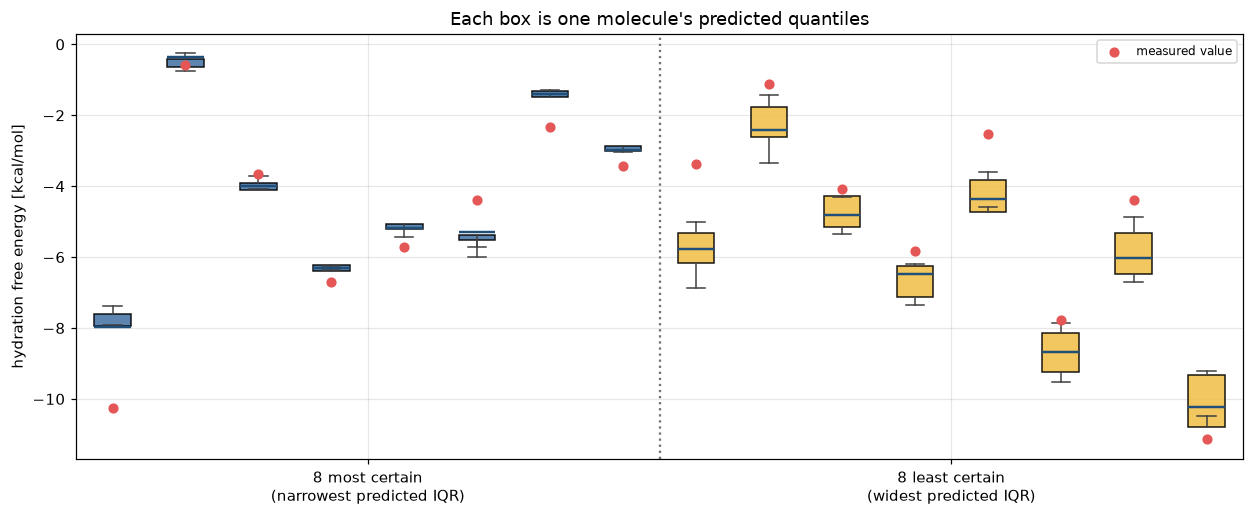

In [37]:
def predicted_quantile_box(row):
    """Box-plot statistics from the quantiles Mother already predicted."""
    return {
        "med": float(row["quantile_0.5"]),
        "q1": float(row["quantile_0.25"]),
        "q3": float(row["quantile_0.75"]),
        "whislo": float(row["quantile_0.1"]),
        "whishi": float(row["quantile_0.9"]),
        "fliers": [],
    }


iqr = np.asarray(quantile_table["total_uncertainty"], float)
order = np.argsort(iqr)
n_show = 8
pick = np.concatenate([order[:n_show], order[-n_show:]])
boxes = [predicted_quantile_box(df_res_quant.iloc[int(i)]) for i in pick]

fig, ax = plt.subplots(figsize=(11.5, 4.8))
drawn = ax.bxp(
    boxes,
    showfliers=False,
    patch_artist=True,
    medianprops={"color": "#1f4e79", "linewidth": 1.6},
    whiskerprops={"color": "0.25"},
    capprops={"color": "0.25"},
)
for patch, certain in zip(drawn["boxes"], [True] * n_show + [False] * n_show):
    patch.set_facecolor("#4c78a8" if certain else "#f2c14e")
    patch.set_alpha(0.9)
ax.scatter(np.arange(1, len(pick) + 1), y_fs[pick], s=32, color="#e45756", zorder=4, label="measured value")
ax.axvline(n_show + 0.5, color="0.45", ls=":")
ax.set_xticks([n_show / 2 + 0.5, n_show + n_show / 2 + 0.5])
ax.set_xticklabels(["8 most certain\n(narrowest predicted IQR)", "8 least certain\n(widest predicted IQR)"])
ax.set_ylabel("hydration free energy [kcal/mol]")
ax.set_title("Each box is one molecule's predicted quantiles")
ax.legend(fontsize=8, loc="best")
fig.tight_layout()
plt.show()

### 9.8 The same scatter and quartile plots for every score

Each score is drawn twice: the scatter with the 95 % lines, then the quartile boxes and the share of large errors in each quartile. The ANOVA line under each name says whether those four bins differ. A non-significant ANOVA means the quarters do not separate; it can still leave the extreme 10 % informative, which is the virtual-ensemble case on FreeSolv (section 6.1).

The last figure puts the scatters side by side. The x-axis is that score's own uncertainty, because the raw scales differ by more than an order of magnitude and a shared axis would flatten the virtual-ensemble and bootstrap panels. The title Spearman is the rank correlation, to two decimal places.

The decile chart is the fair comparison across scores. For each score it plots the mean absolute error in ten equally sized uncertainty bins, divided by that score's own mean absolute error. A useful score climbs from the left (certain) to the right (uncertain). This replaces a curve that plotted a running mean of the error against the raw uncertainty value: that curve mixed the unit of the score into the x-axis, so a virtual-ensemble std near 0.03 could not be compared with a GP std near 0.5. The calibration of the interval width, which is a different question, stays in sections 4.2 and 6.


GP CatBoost: Spearman +0.27 (p = 0.00065), MAE 0.75, RMSE 1.18, R² 0.86
GP CatBoost: ANOVA F = 7.38, p = 0.00012


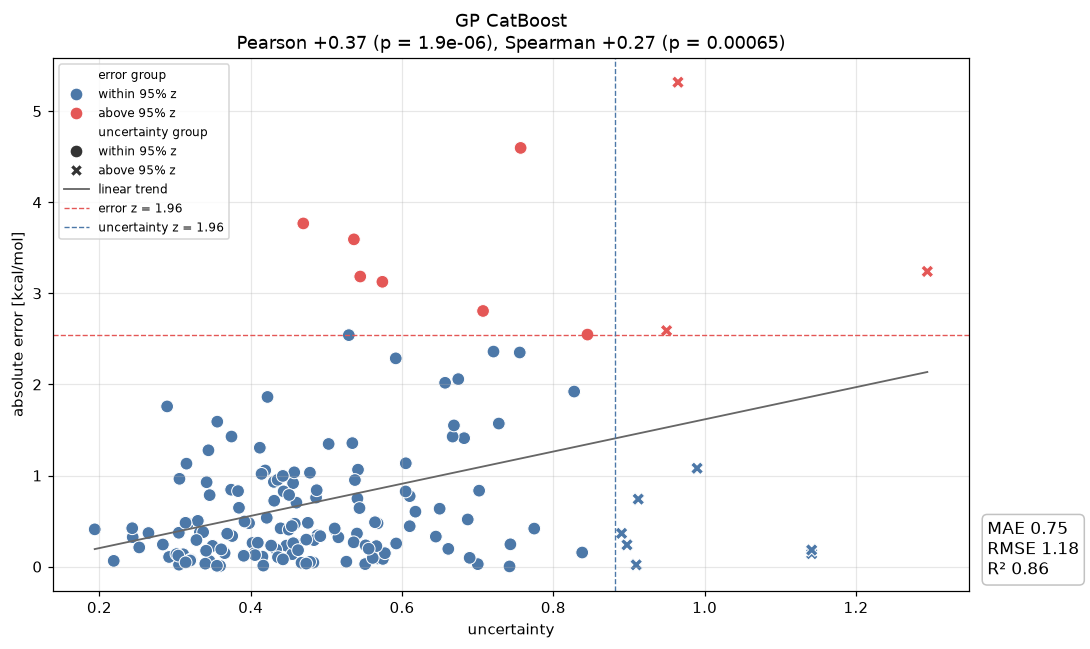

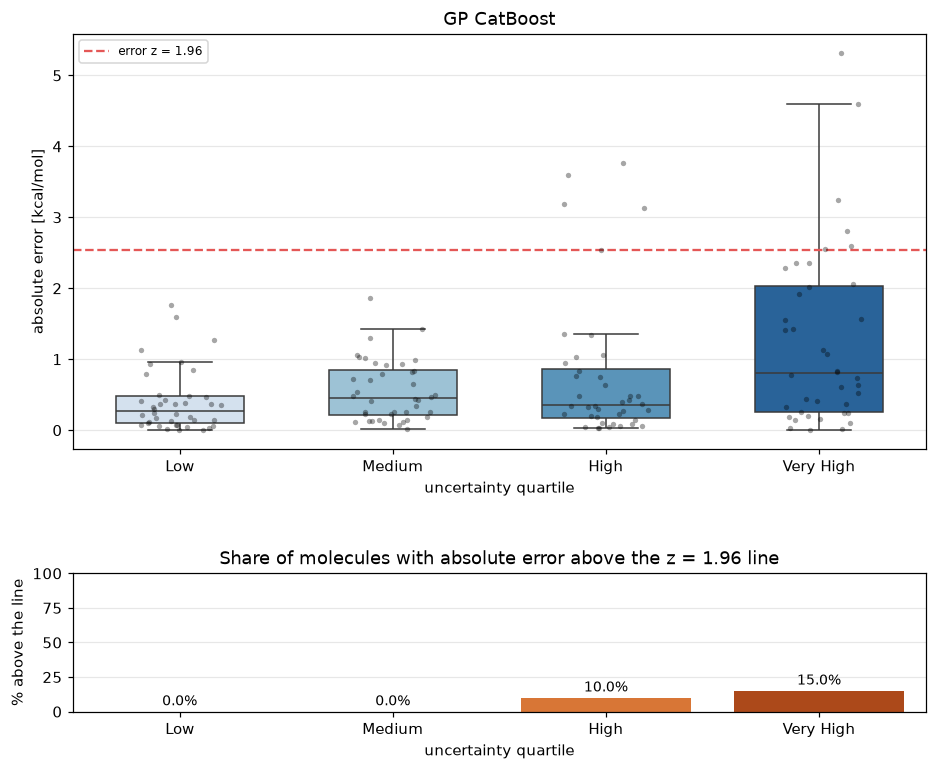

CatBoost RMSE + VE: Spearman +0.17 (p = 0.028), MAE 0.76, RMSE 1.21, R² 0.86
CatBoost RMSE + VE: ANOVA F = 1.98, p = 0.12


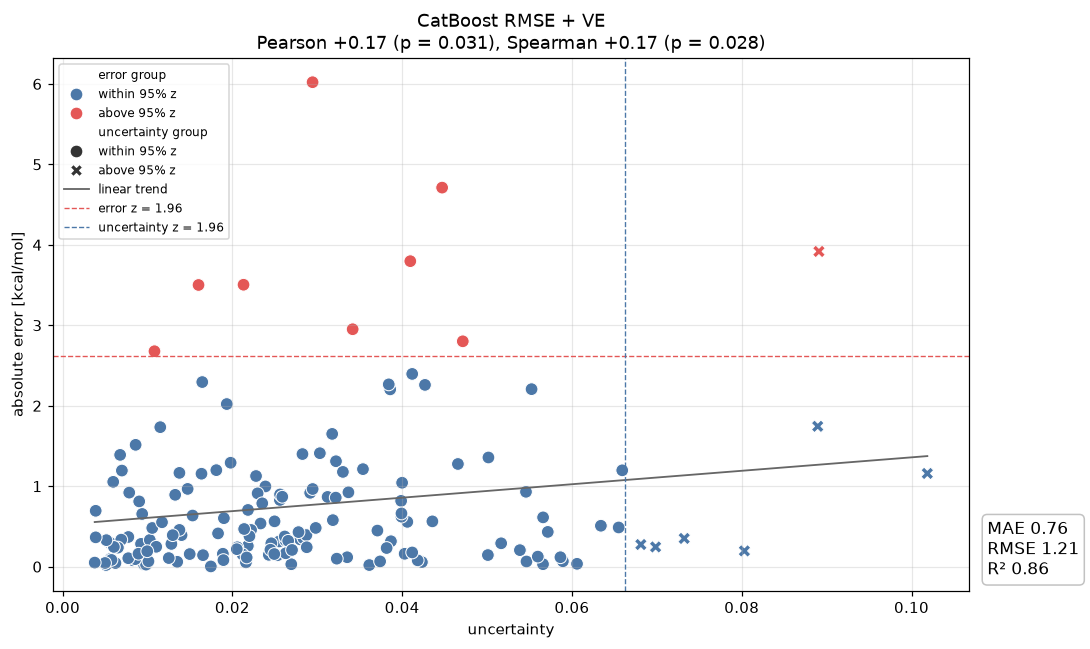

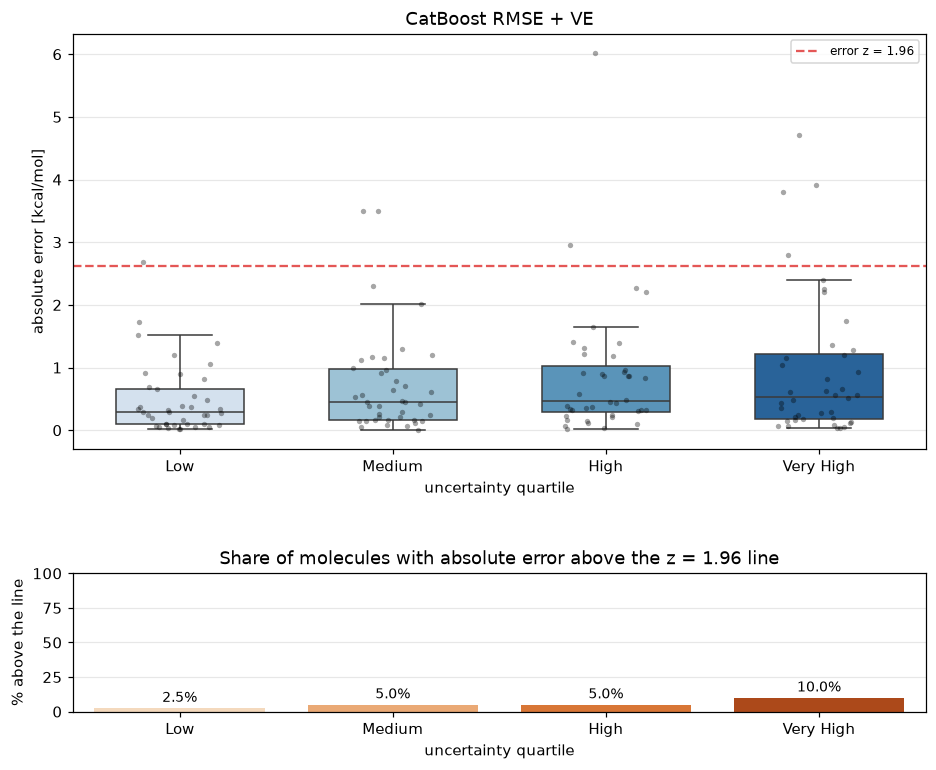

CatBoost RMSEWithUncertainty: Spearman +0.52 (p = 2.1e-12), MAE 0.77, RMSE 1.18, R² 0.86
CatBoost RMSEWithUncertainty: ANOVA F = 18.55, p = 2.4e-10


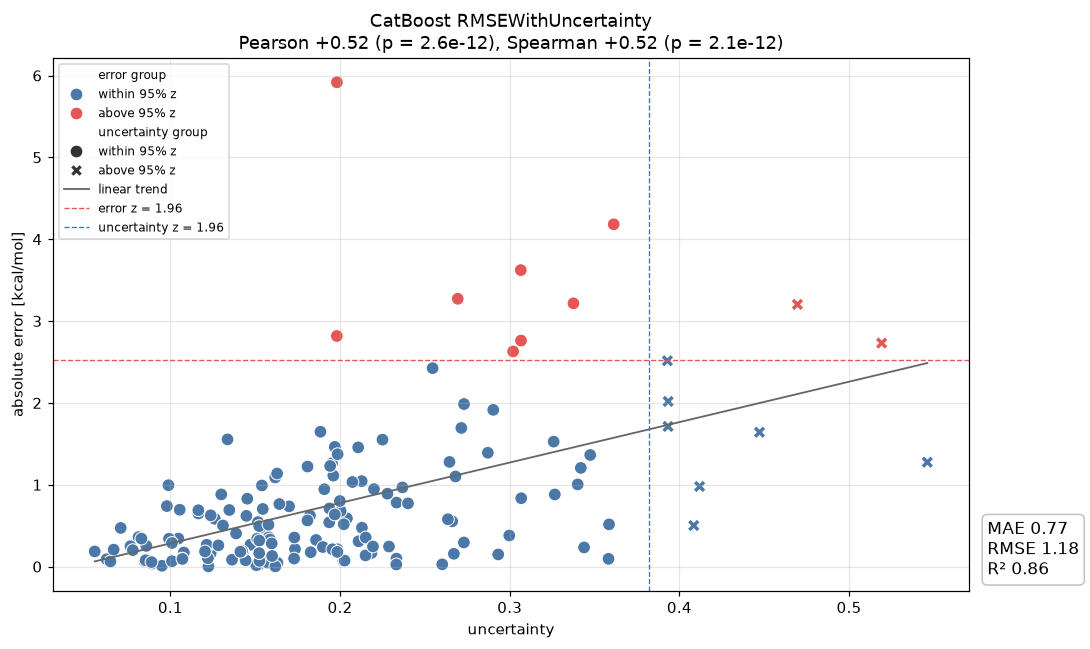

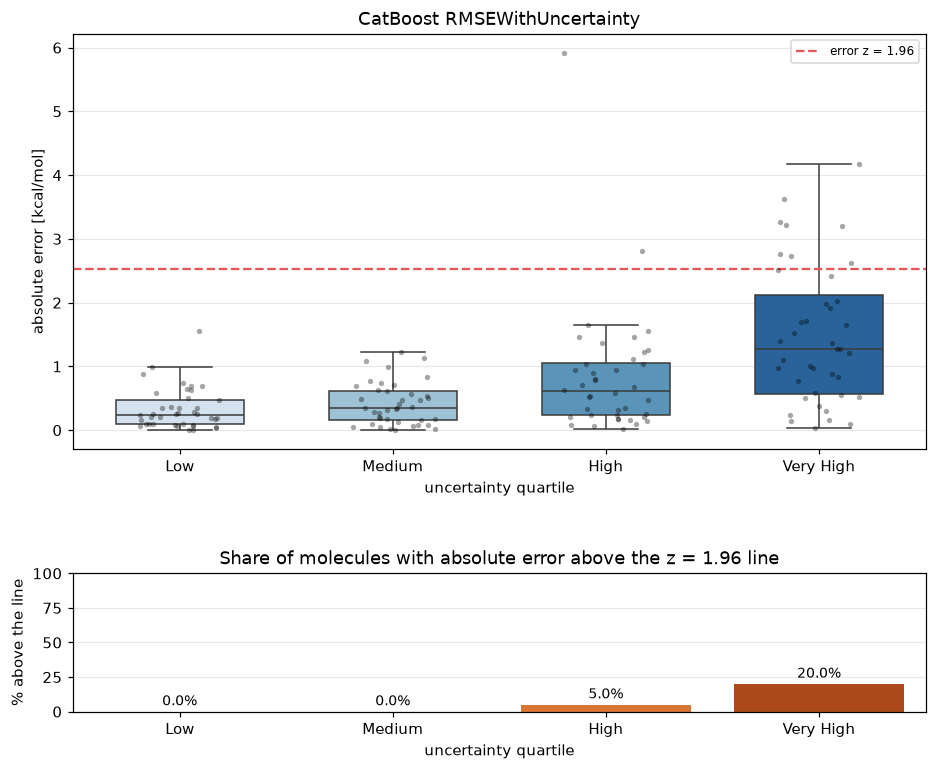

RMSEWithUncertainty knowledge: Spearman +0.07 (p = 0.37), MAE 0.77, RMSE 1.18, R² 0.86
RMSEWithUncertainty knowledge: ANOVA F = 0.66, p = 0.58


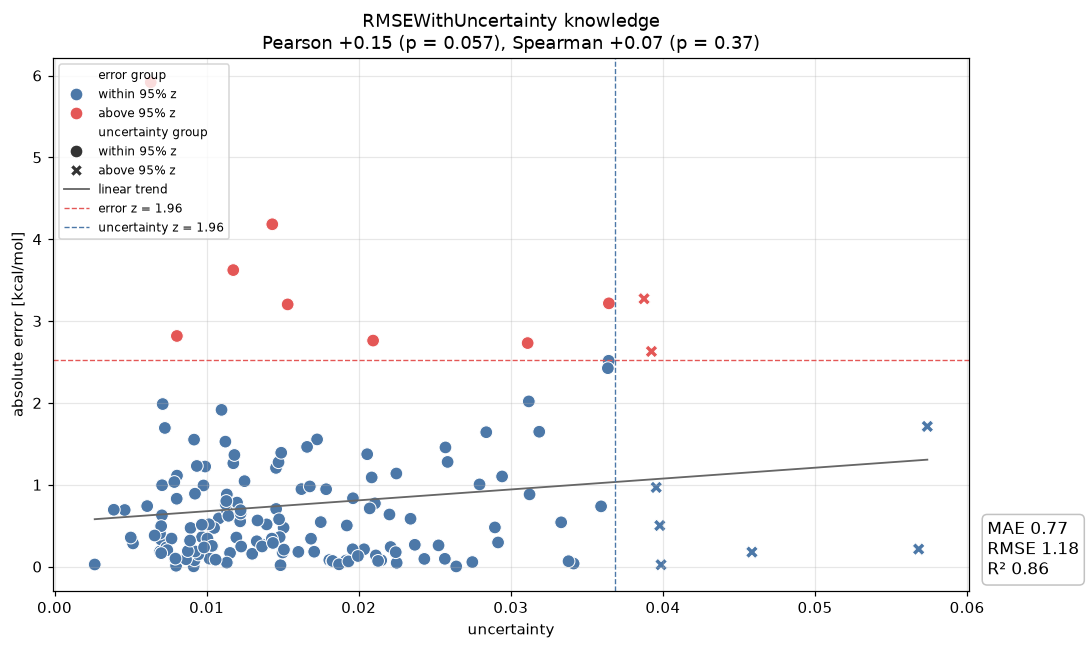

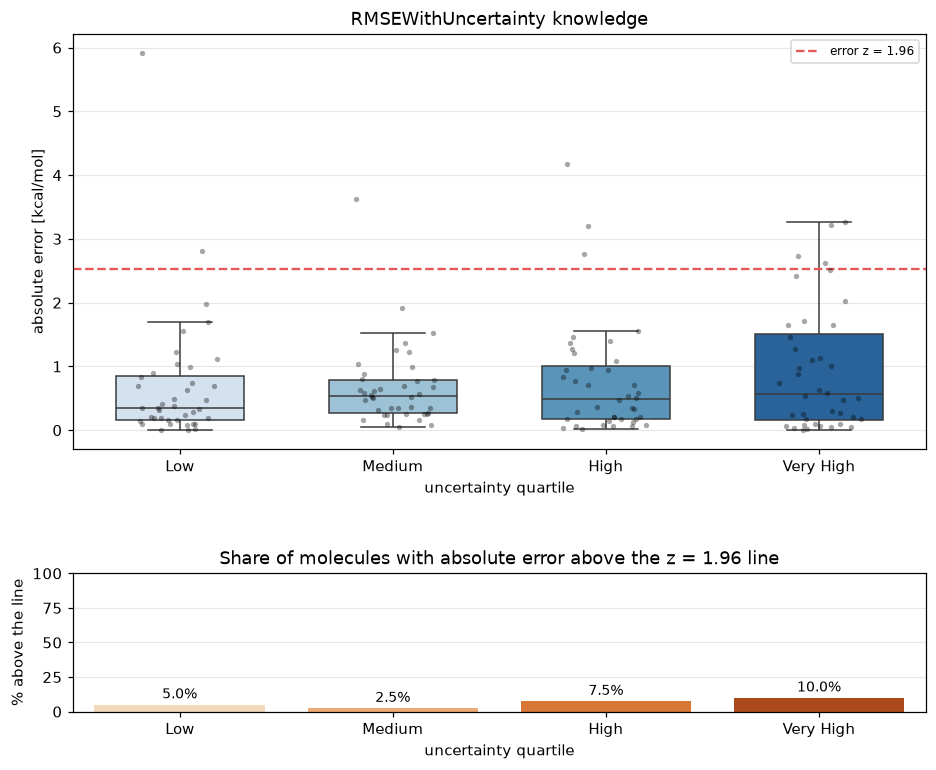

RMSEWithUncertainty data: Spearman +0.52 (p = 1.4e-12), MAE 0.77, RMSE 1.18, R² 0.86
RMSEWithUncertainty data: ANOVA F = 18.84, p = 1.8e-10


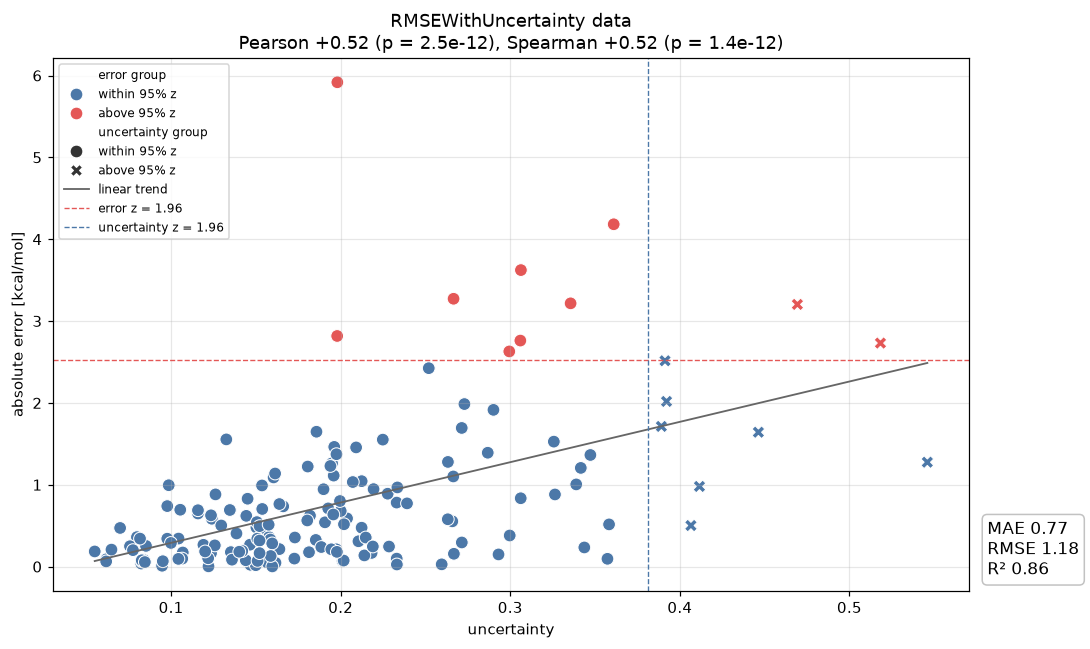

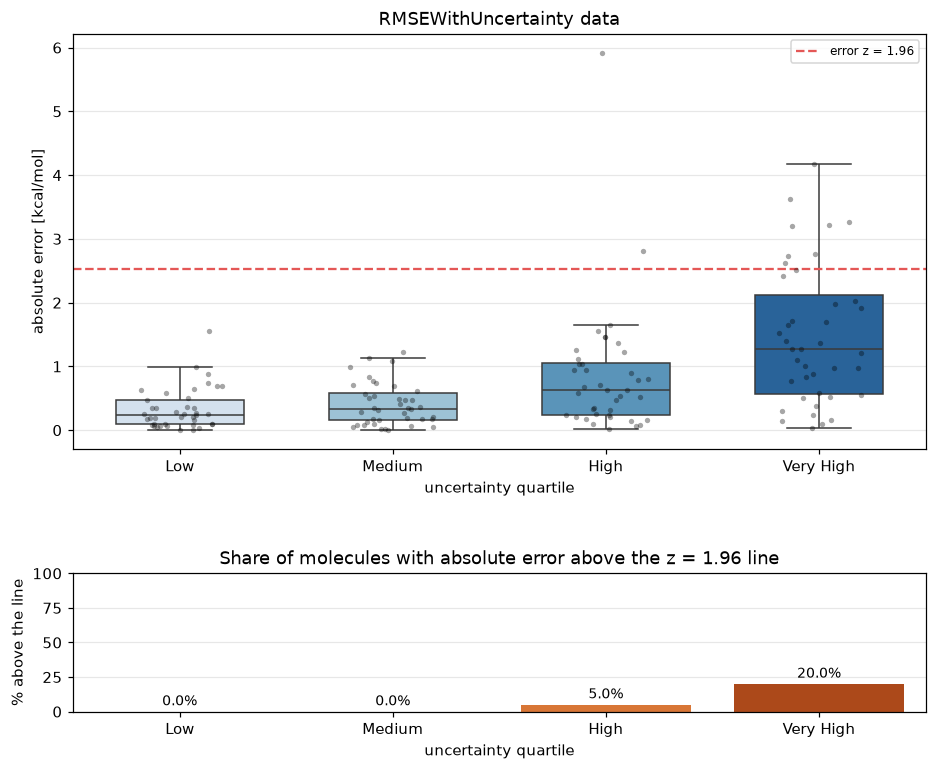

MultiQuantile IQR: Spearman +0.36 (p = 2.3e-06), MAE 0.79, RMSE 1.18, R² 0.86
MultiQuantile IQR: ANOVA F = 10.50, p = 2.5e-06


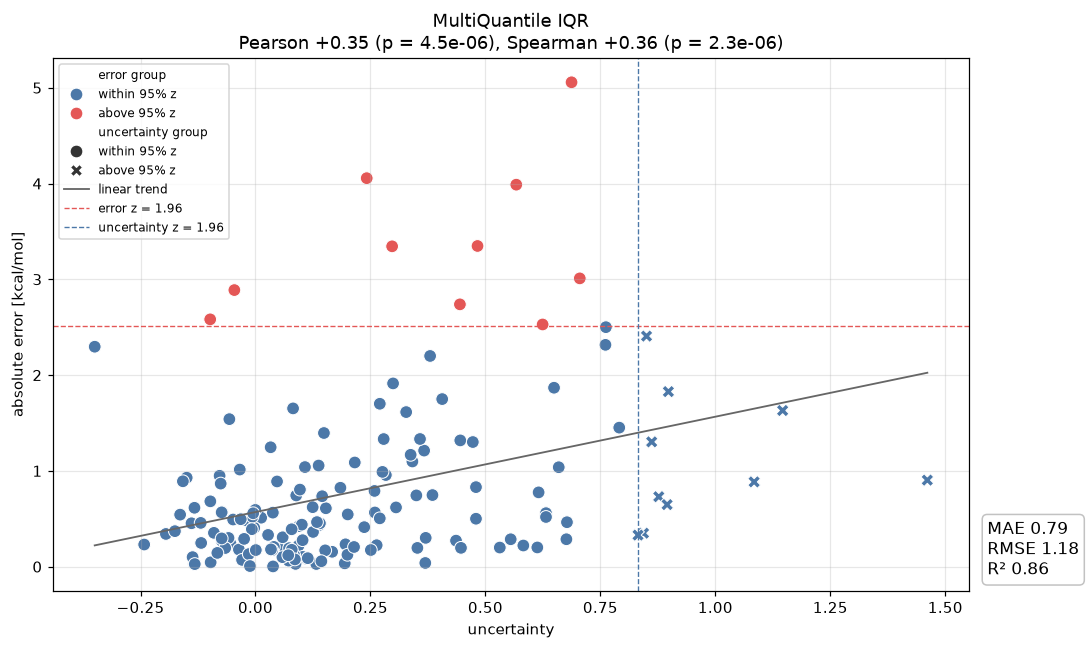

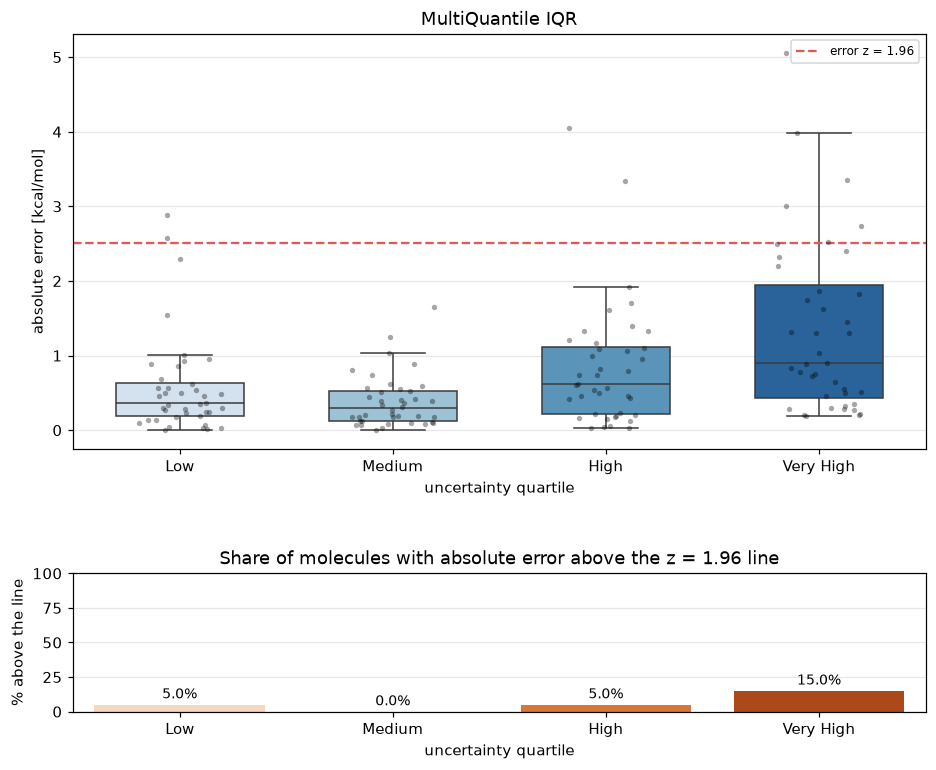

MultiQuantile std of quantiles: Spearman +0.44 (p = 3.9e-09), MAE 0.79, RMSE 1.18, R² 0.86
MultiQuantile std of quantiles: ANOVA F = 14.78, p = 1.6e-08


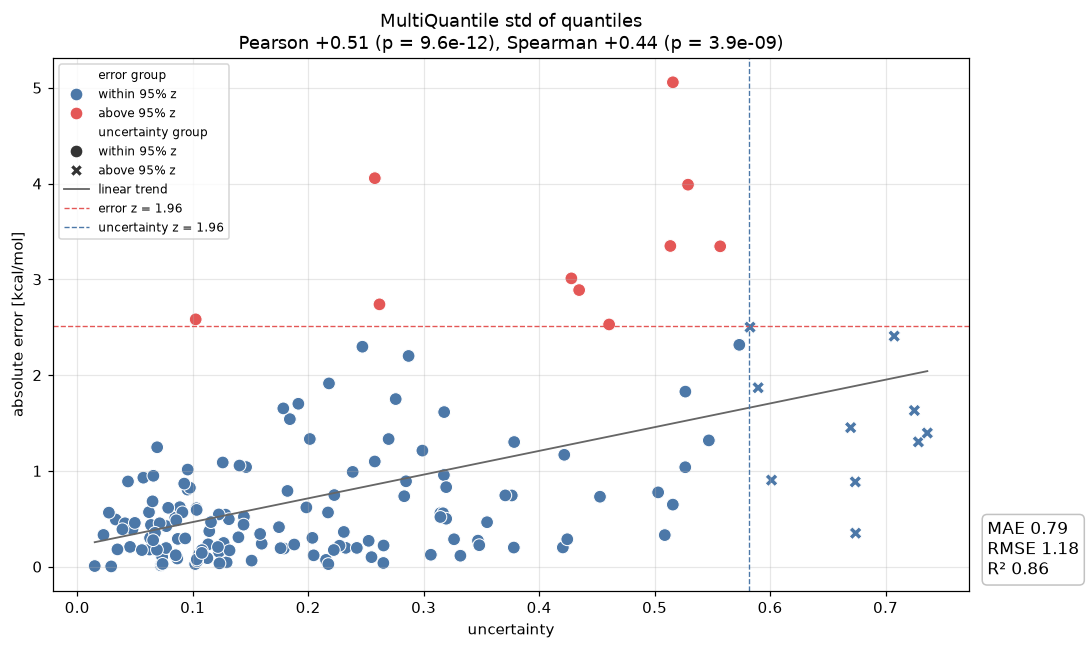

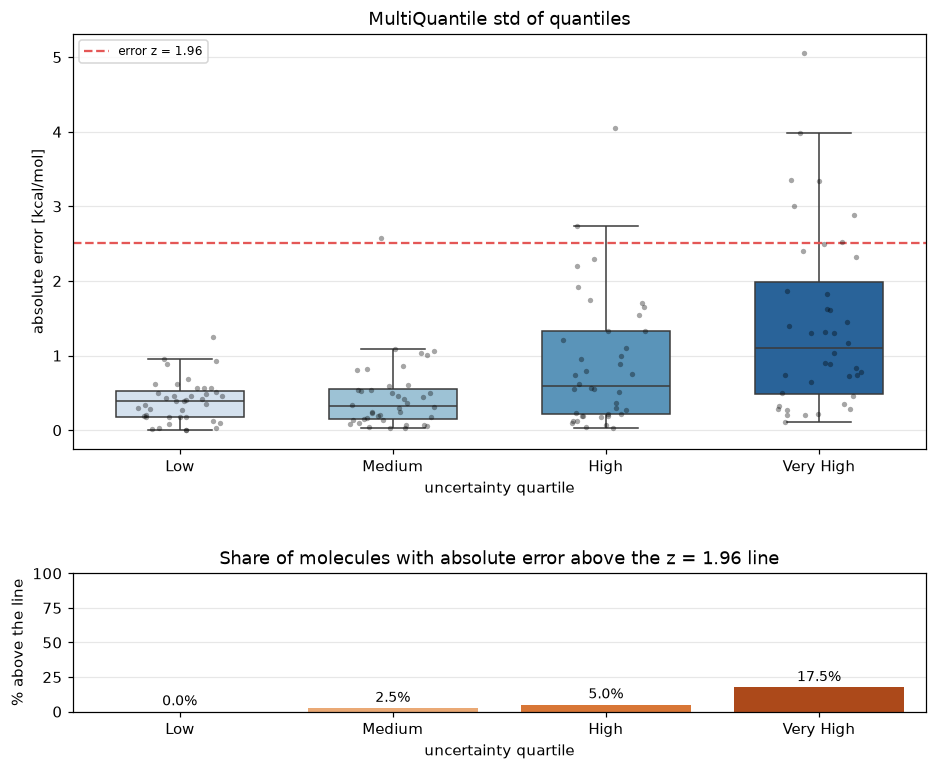

Bootstrap: Spearman +0.45 (p = 2.1e-09), MAE 0.83, RMSE 1.29, R² 0.84
Bootstrap: ANOVA F = 20.14, p = 4.4e-11


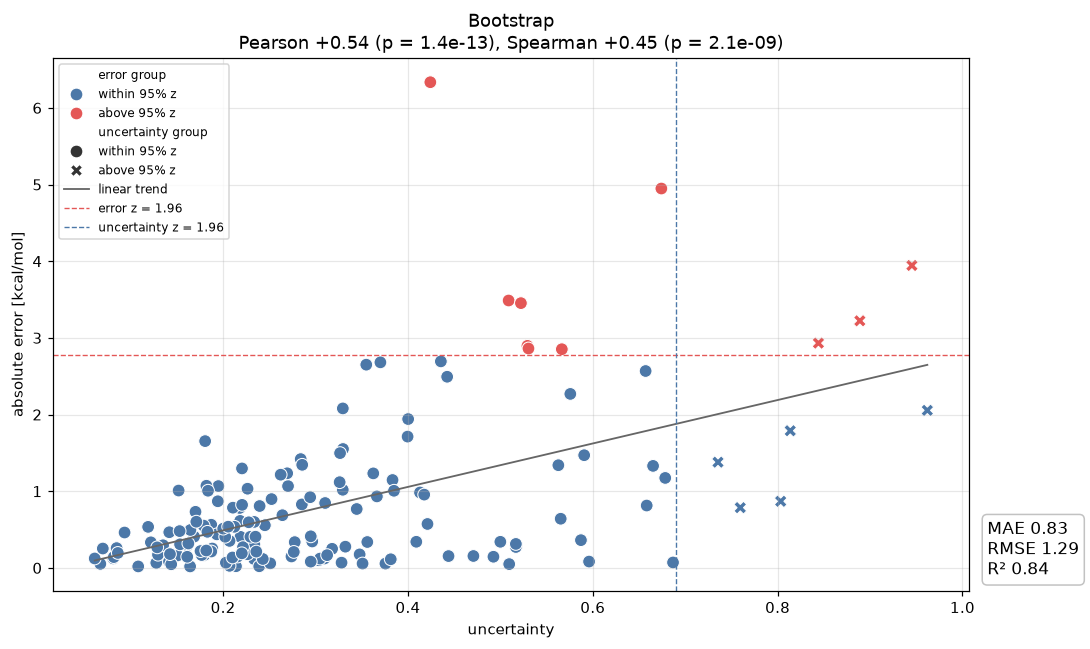

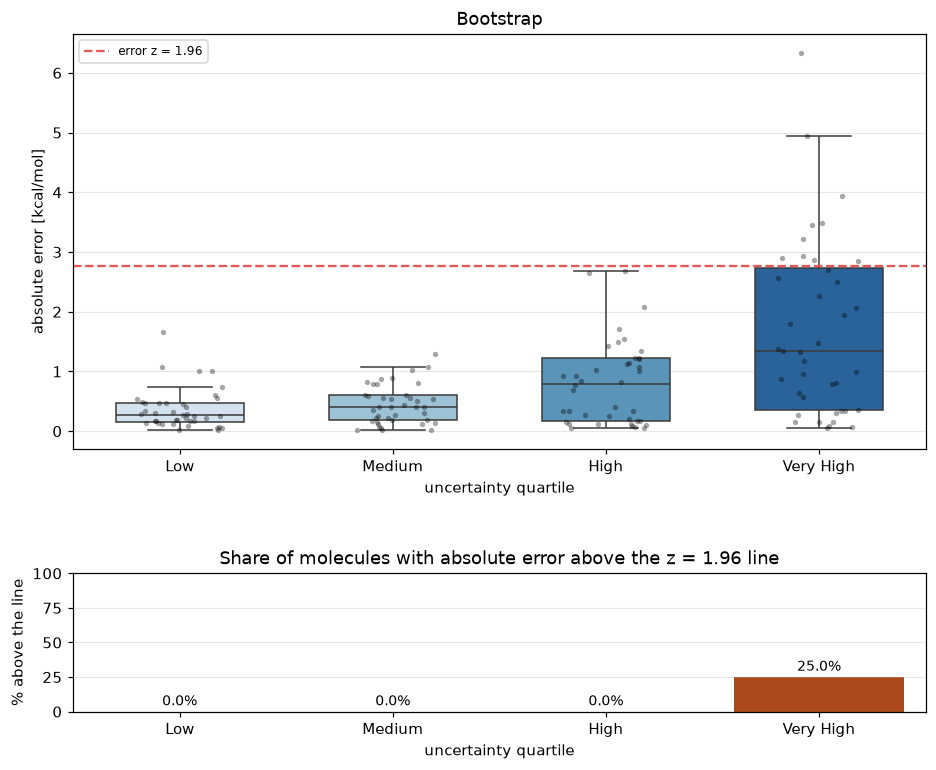

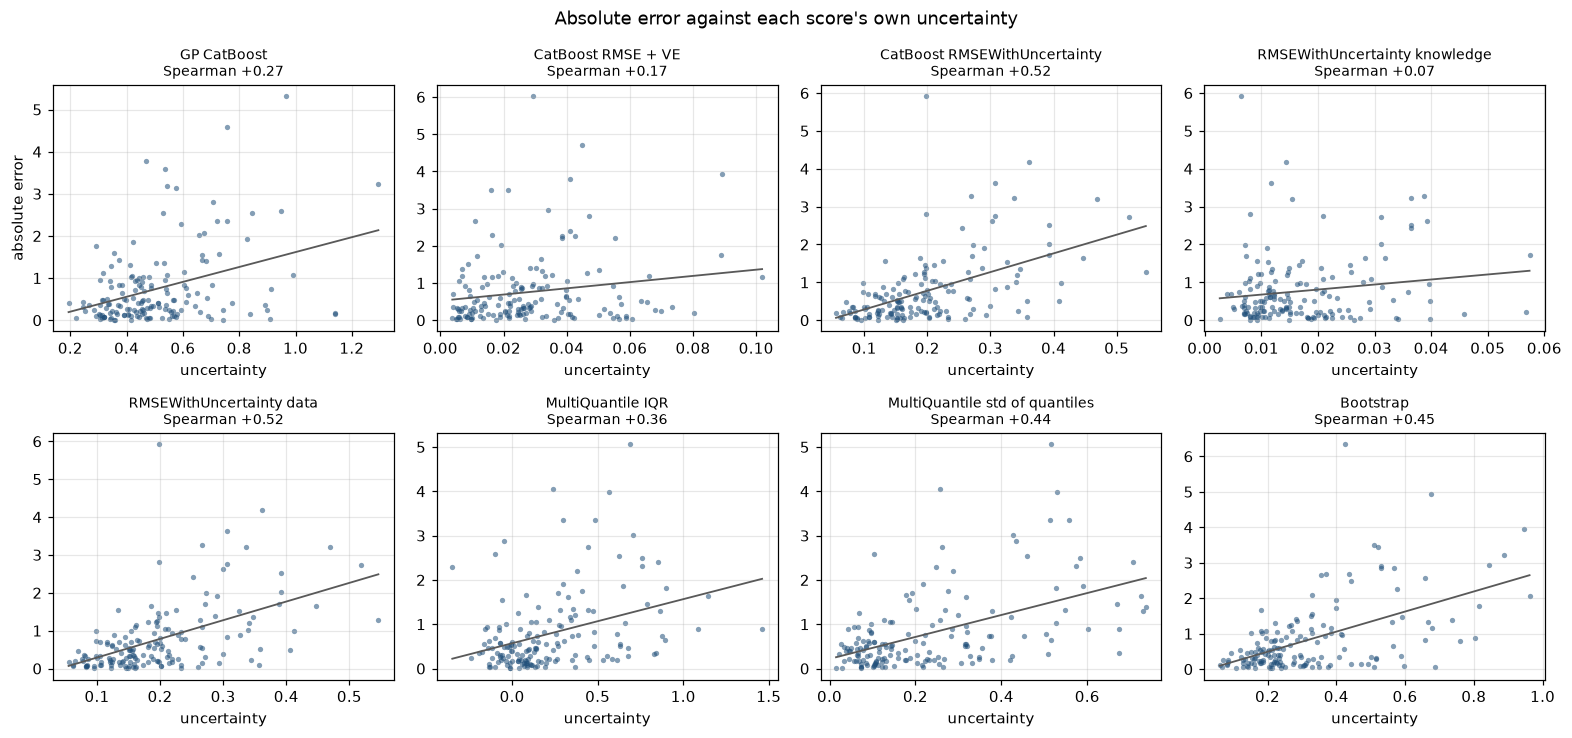

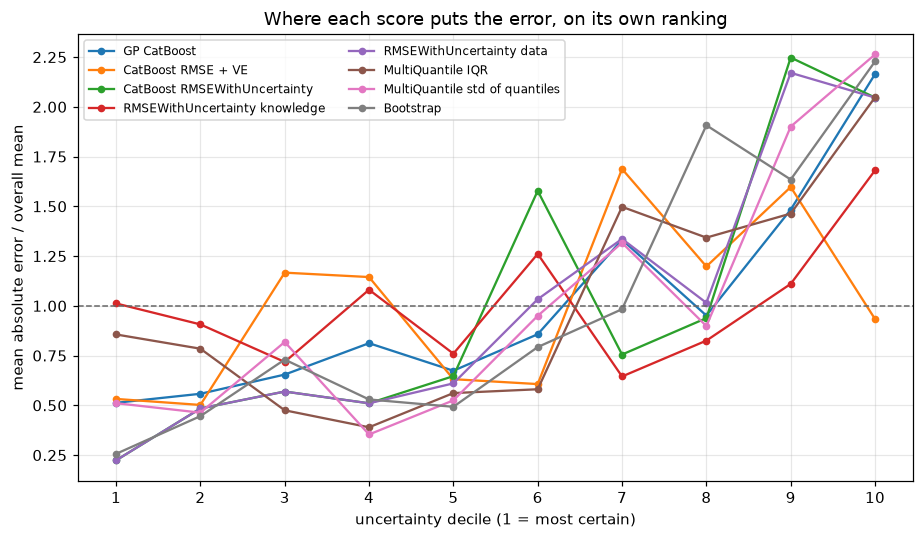

In [38]:
for name, frame in score_frames.items():
    mae, rmse, r2 = describe_score(name, frame, y_fs)
    anova_by_quartile(name, frame)
    plot_uncertainty_vs_error(
        data=frame,
        uncertainty_col="uncertainty",
        prediction_error_col="prediction_error",
        mae=mae,
        rmse=rmse,
        r2=r2,
        title=name,
    )
    plot_boxplot_and_coverage(
        data=frame,
        uncertainty_col="uncertainty",
        prediction_error_col="prediction_error",
        title=name,
    )

names = list(score_frames)
ncols = 4
nrows = int(np.ceil(len(names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.4 * nrows), squeeze=False)
for ax, name in zip(axes.ravel(), names):
    frame = score_frames[name]
    ax.scatter(frame["uncertainty"], frame["prediction_error"], s=12, alpha=0.55, color="#1f4e79", linewidths=0)
    order = np.argsort(frame["uncertainty"].to_numpy(float))
    x = frame["uncertainty"].to_numpy(float)[order]
    y = frame["prediction_error"].to_numpy(float)[order]
    if np.unique(x).size > 1:
        slope, intercept = np.polyfit(x, y, 1)
        ax.plot(x, slope * x + intercept, color="0.35", lw=1.2)
    spearman, _ = stats.spearmanr(frame["uncertainty"], frame["prediction_error"])
    ax.set_title(f"{name}\nSpearman {spearman:+.2f}", fontsize=9)
    ax.set_xlabel("uncertainty")
    ax.set_ylabel("absolute error" if ax is axes.ravel()[0] else "")
for ax in axes.ravel()[len(names) :]:
    ax.axis("off")
fig.suptitle("Absolute error against each score's own uncertainty", fontsize=12)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5))
for name, frame in score_frames.items():
    order = np.argsort(frame["uncertainty"].to_numpy(float))
    err = frame["prediction_error"].to_numpy(float)[order]
    bins = np.array_split(err, 10)
    relative = [bin_err.mean() / err.mean() for bin_err in bins]
    ax.plot(np.arange(1, 11), relative, marker="o", ms=4, label=name)
ax.axhline(1.0, color="0.4", ls="--", lw=1)
ax.set_xticks(np.arange(1, 11))
ax.set_xlabel("uncertainty decile (1 = most certain)")
ax.set_ylabel("mean absolute error / overall mean")
ax.set_title("Where each score puts the error, on its own ranking")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

### 9.9 What to take from the extra estimates

Use the printed Spearman values, to two decimal places, and the decile chart.

* **MultiQuantile** describes the shape of the prediction, and on this FreeSolv split that shape tracks the error. Absolute error rises toward the high-uncertainty end (section 9.6), which is the useful direction. The interquartile range is the uncertainty Mother returns. The standard deviation of the five quantiles is the same width in another unit. The box plot in section 9.7 is the picture of that width: a narrow box is a tight prediction, a wide box is an uncertain one, and the measured value is the point on the box.
* **Bootstrap** is a knowledge score you can compute for any Mother regressor, at the cost of repeated fits. On this comparison it is the expensive cousin of the virtual ensembles, which extract a related spread from the single RMSE model already fit in section 6.
* **Virtual ensembles** stay the free knowledge score. Trust the very low end on FreeSolv. Treat a high score as a hint (the 75–90 % band), and use `RMSEWithUncertainty` or GP CatBoost when you need the high end to mark large errors.
* **Feature selection** is available around any of these models through `get_feature_selection_pipeline`. The count printed in section 9.3 is how many training columns that pipeline keeps. The comparison itself stays on the full matrix.
